## FRED 거시경제 데이터를 정리하고, 분석하고, 검증하는


### 학습 경로
1. **설정·수집:** 환경변수, 조회 기준일, 데이터 사전, 원자료 저장.
2. **전처리:** 날짜·중복·자료형·값 범위, 달력월 정렬, 금리 관측 수, 결측 구간 분류.
3. **사후 EDA용 보간:** 짧은 중간 결측만 선택적으로 채우고 셀별 이력·파생변수 영향 표시.
4. **파생변수·이상치:** 변화폭·증가율·연율화·이동평균·변동성·Sahm 근사, 극단값은 삭제하지 않고 표시.
5. **시각화:** 전체·최근 대시보드, 금리·물가·고용, 상관·시차, 역전 구간, 경기침체 전후, 보간 민감도.
6. **선택적 예측:** ALFRED 시점별 빈티지, 완전한 미래 6개월 정답, 학습·추론 분리, 모델 진단.
7. **저장·체크리스트:** CSV·PNG·SVG, 실행 설정·출처·그림 목차 저장.

## 0. 설치와 실행 준비

Jupyter 또는 Colab에서 아래 설치 셀을 실행하고 필요한 경우 커널을 재시작합니다. 그 다음 설정부터 순서대로 실행하세요. `.env`를 쓰는 기존 작업 방식을 지원하되, FRED와 관계없는 DART·ECOS·KRX 인증 코드는 제거했습니다.

라이브 조회에는 환경변수 `FRED_API_KEY`가 필요합니다. 예: 로컬 `.env` 파일에 `FRED_API_KEY=발급받은키`를 저장합니다. `.env`와 캐시를 외부 저장소에 올리지 말고, 노트북에는 실제 키를 넣지 마세요. Colab은 런타임의 비밀키/환경변수에 저장하세요.

한글 그림에는 `Noto Sans CJK KR`, `NanumGothic`, `Malgun Gothic`, `AppleGothic` 중 하나가 필요합니다. Linux/Colab에서 글꼴이 없다면 운영체제 패키지 `fonts-noto-cjk`를 설치한 뒤 커널을 재시작하세요.


In [20]:
# 최초 실행 또는 패키지가 없을 때만 실행
# %pip install -q fredapi pandas numpy matplotlib seaborn scikit-learn python-dotenv


In [21]:
import os
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
import seaborn as sns
from fredapi import Fred
from dotenv import load_dotenv
from IPython.display import display, Markdown

load_dotenv()
warnings.filterwarnings("default")

FRED_API_KEY = os.getenv("FRED_API_KEY")

RANDOM_STATE = 42
START_DATE = "1990-01-01"
DATA_SNAPSHOT_DATE = os.getenv(
    "FRED_AS_OF_DATE", pd.Timestamp.now(tz="America/Chicago").strftime("%Y-%m-%d")
)
SNAPSHOT_TS = pd.Timestamp(DATA_SNAPSHOT_DATE).normalize()
TODAY_US = pd.Timestamp.now(tz="America/Chicago").tz_localize(None).normalize()
if SNAPSHOT_TS > TODAY_US or SNAPSHOT_TS < pd.Timestamp(START_DATE):
    raise ValueError("조회 기준일은 분석 시작일 이후, 오늘 이전이어야 합니다.")
DATA_SNAPSHOT_DATE = SNAPSHOT_TS.strftime("%Y-%m-%d")
DATA_START_DATE = (pd.Timestamp(START_DATE) - pd.DateOffset(months=24)).strftime("%Y-%m-%d")
AS_OF = SNAPSHOT_TS

# 기본은 실데이터 FRED 조회. API 없이 이미 저장한 원자료로 실행하려면 local_csv 선택.
DATA_MODE = "fred_api"  # 'fred_api' 또는 'local_csv'
LOCAL_INPUT_DIR = Path("inputs")
USE_SNAPSHOT_CACHE = True
ENABLE_EDA_INTERPOLATION = True
MAX_GAP = 1
MIN_DAILY_OBSERVATIONS = 10
OUTLIER_Z_THRESHOLD = 4.5
RECENT_MONTHS = 60
MIN_CORR_PAIRS = 24
LAGS = range(-12, 13)
EVENT_WINDOW_BEFORE = 12
EVENT_WINDOW_AFTER = 24
SAVE_FIGURES = True
SHOW_FIGURES = True
FIGURE_DPI = 160

# 전처리·시각화에 집중하도록 느린 ALFRED 모델 파트는 기본적으로 꺼 둡니다.
RUN_PIT_MODEL = False
PRIMARY_MODEL_NAME = "Logistic Regression"  # 테스트 결과를 본 뒤 고르지 않는 사전 지정 모델
TARGET_HORIZON = 6
MAX_SOURCE_AGE_MONTHS = {
    "DGS10": 1, "DGS2": 1, "CPIAUCSL": 2,
    "FEDFUNDS": 2, "UNRATE": 2, "PAYEMS": 2,
}

OUTPUT_DIR = Path("outputs_detailed") / DATA_SNAPSHOT_DATE
TABLE_DIR, FIG_DIR = OUTPUT_DIR / "tables", OUTPUT_DIR / "figures"
RAW_OUTPUT_DIR = OUTPUT_DIR / "raw"
CACHE_DIR = Path("cache_alfred")
for path in [OUTPUT_DIR, TABLE_DIR, FIG_DIR, RAW_OUTPUT_DIR]:
    path.mkdir(parents=True, exist_ok=True)

RAW_COLS = ["US10Y", "US2Y", "T10Y2Y", "CPI", "FEDFUNDS", "UNRATE", "PAYEMS", "USREC"]
CORR_COLS = ["US10Y", "CPI_YoY", "FEDFUNDS", "UNRATE", "T10Y2Y"]
SERIES = {
    "DGS10": "미국 10년물 국채금리", "DGS2": "미국 2년물 국채금리",
    "CPIAUCSL": "소비자물가지수", "FEDFUNDS": "연방기금 유효금리 월평균",
    "UNRATE": "실업률", "PAYEMS": "비농업 고용자 수", "USREC": "NBER 경기침체 지표",
}
COLORS = {
    "US10Y": "#244B74", "US2Y": "#E18A32", "CPI_YoY": "#BF4A4A",
    "FEDFUNDS": "#7259A4", "UNRATE": "#258F88", "T10Y2Y": "#4C78A8",
}
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
font_names = {font.name for font in font_manager.fontManager.ttflist}
chosen_font = next((name for name in ["Noto Sans CJK KR", "NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK JP"] if name in font_names), None)
if chosen_font:
    plt.rcParams["font.family"] = chosen_font
else:
    warnings.warn("한글 글꼴을 찾지 못했습니다. Noto Sans CJK KR 설치 후 커널을 재시작하세요.")
plt.rcParams.update({"axes.unicode_minus": False, "figure.figsize": (13, 5),
                     "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.bbox": "tight", "svg.fonttype": "none"})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
figure_registry = []
metadata = {}
print("조회 기준일:", DATA_SNAPSHOT_DATE, "/ 데이터 방식:", DATA_MODE)
print("사후 EDA 보간:", ENABLE_EDA_INTERPOLATION, "/ 선택적 PIT 모델:", RUN_PIT_MODEL)
print("그림 글꼴:", chosen_font or "미설정", "/ 결과 폴더:", OUTPUT_DIR)


조회 기준일: 2026-11-11 / 데이터 방식: fred_api
사후 EDA 보간: True / 선택적 PIT 모델: False
그림 글꼴: Malgun Gothic / 결과 폴더: outputs_detailed\2026-11-11


### 주요 설정의 의미

`START_DATE`는 분석 출력 시작일입니다. 변화율과 Sahm 계산을 위해 실제 수집은 24개월 먼저 시작합니다. `FRED_AS_OF_DATE`를 지정하면 오늘 수정판 대신 그 날짜 기준의 값을 조회합니다. 단일 조회일 버전은 전체기간 실시간 데이터와 다르며, 예측용 빈티지는 마지막 선택적 파트에서 따로 만듭니다.

`MIN_DAILY_OBSERVATIONS=10`은 월평균 금리를 계산할 최소 일별 관측 수입니다. 공식 거래일 달력과 비교한 완전성 기준은 아닙니다. `MAX_GAP=1`은 보간할 최대 연속 결측 월 수입니다. 보간은 CPI·실업률·고용의 사후 EDA에만 제한합니다. `FEDFUNDS`는 정책 목표금리 계단값이 아니라 **유효 연방기금금리의 월평균**이므로 기존 첨부본의 무조건적인 전방 채움을 사용하지 않습니다.

`RUN_PIT_MODEL=False`이면 데이터 정리와 모든 거시 시각화, 타깃 완전성 진단까지만 실행됩니다. 모델까지 돌리려면 `True`로 바꾸세요. 최초 ALFRED 이력 다운로드는 길어질 수 있습니다. 실제 빈티지가 없는 과거 기간은 학습에서 제외되므로 실질 학습 기간이 1990년보다 늦게 시작될 수 있습니다.


In [22]:
def shade_recessions(ax, usrec):
    """관측된 USREC=1 구간만 음영. 결측을 비침체 0으로 바꾸지 않습니다."""
    s = pd.to_numeric(usrec, errors="coerce").sort_index()
    if s.empty:
        return
    grid = pd.date_range(s.index.min(), s.index.max(), freq="MS")
    s = s.reindex(grid)
    in_run, begin, previous = False, None, None
    for date, value in s.items():
        active = pd.notna(value) and value == 1
        if active and not in_run:
            begin, in_run = date, True
        if in_run and not active:
            ax.axvspan(begin, previous + pd.offsets.MonthBegin(1), color="#9EA4AB", alpha=0.15, zorder=0)
            in_run = False
        previous = date
    if in_run:
        ax.axvspan(begin, previous + pd.offsets.MonthBegin(1), color="#9EA4AB", alpha=0.15, zorder=0)


def finish_figure(fig, name, caption=""):
    """모든 그림에 조회일·캡션을 기록하고 PNG/SVG를 저장합니다."""
    if fig.get_layout_engine() is None:
        fig.tight_layout()
    if caption:
        fig.text(0.01, -0.005, caption, ha="left", va="top", fontsize=9, color="#555555", wrap=True)
    fig.text(0.99, -0.065, f"조회 기준일 {DATA_SNAPSHOT_DATE}", ha="right", va="top", fontsize=8, color="#777777")
    paths = {}
    if SAVE_FIGURES:
        for extension in ["png", "svg"]:
            path = FIG_DIR / f"{name}.{extension}"
            fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
            paths[extension] = str(path)
    figure_registry.append({"name": name, "caption": caption, **paths})
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


## 1. FRED 원자료 수집과 출처 기록

라이브 모드는 환경변수 키를 사용하여 7개 시리즈와 FRED 메타데이터를 받습니다. 관측값의 조회 버전은 `DATA_SNAPSHOT_DATE`로 고정합니다. 지표 설명 메타데이터는 실행 시 받은 정보임을 따로 기록합니다. API가 실패하면 다른 날짜의 캐시나 임의의 값으로 대체하지 않습니다.

API 없이 실행하려면 `DATA_MODE="local_csv"`로 바꾸고 `inputs/`에 `DGS10.csv` 등 7개 파일을 넣습니다. 각 파일은 `date,value` 두 열이 필요하며, `snapshot_manifest.json`에는 `snapshot_date`, `source`, `series_metadata`를 넣습니다. `snapshot_date`는 설정한 조회 기준일과 같아야 합니다. 원자료 버전이 확인되지 않는 CSV를 실시간 빈티지로 취급하지 않습니다.

첨부 노트북의 `raw` 출력은 앞뒤 일부 값만 보여주며 전체 원자료가 포함되어 있지 않습니다. 따라서 그 출력에서 생략된 값을 복원하거나 추정하지 않습니다.


In [23]:
def safe_series_metadata(info):
    names = ["id", "title", "units", "frequency", "seasonal_adjustment", "observation_start", "observation_end", "last_updated", "notes"]
    return {name: str(info.get(name, "")) for name in names}


snapshot_cache_dir = Path("cache_fred_snapshots") / f"{DATA_START_DATE}_{DATA_SNAPSHOT_DATE}"
manifest_name = "snapshot_manifest.json"
raw = {}
if DATA_MODE == "local_csv":
    source_dir = LOCAL_INPUT_DIR
elif DATA_MODE == "fred_api":
    source_dir = snapshot_cache_dir
else:
    raise ValueError("DATA_MODE는 fred_api 또는 local_csv여야 합니다.")
manifest_path = source_dir / manifest_name
can_load = (manifest_path.is_file() and all((source_dir / f"{sid}.csv").is_file() for sid in SERIES))
if DATA_MODE == "local_csv" or (USE_SNAPSHOT_CACHE and can_load):
    if not can_load:
        raise FileNotFoundError("7개 시리즈 CSV와 snapshot_manifest.json이 필요합니다.")
    snapshot_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if snapshot_manifest.get("snapshot_date") != DATA_SNAPSHOT_DATE:
        raise ValueError("CSV 원자료 버전의 snapshot_date가 설정한 조회 기준일과 다릅니다.")
    if not snapshot_manifest.get("source"):
        raise ValueError("snapshot_manifest.json에 source를 기록해야 합니다.")
    if DATA_MODE == "fred_api" and snapshot_manifest.get("observation_start") != DATA_START_DATE:
        raise ValueError("캐시 관측 시작일이 요청과 다릅니다.")
    metadata = snapshot_manifest.get("series_metadata", {})
    for sid in SERIES:
        frame = pd.read_csv(source_dir / f"{sid}.csv")
        if not {"date", "value"}.issubset(frame.columns):
            raise ValueError(f"{sid}: CSV에 date,value 열이 없습니다.")
        dates = pd.to_datetime(frame["date"], errors="raise")
        raw[sid] = pd.Series(frame["value"].to_numpy(), index=dates, name=sid)
        raw[sid] = raw[sid].loc[(raw[sid].index >= DATA_START_DATE) & (raw[sid].index <= SNAPSHOT_TS)]
    print("기록된 원자료 스냅샷 사용:", source_dir)
else:
    FRED_KEY = os.getenv("FRED_API_KEY")
    if not FRED_KEY:
        raise ValueError("FRED_API_KEY가 없습니다. 키를 설정하거나 local_csv 모드를 사용하세요.")
    fred = Fred(api_key=FRED_KEY)
    for sid, description in SERIES.items():
        print("다운로드:", sid, "-", description)
        try:
            raw[sid] = fred.get_series(
                sid, observation_start=DATA_START_DATE, observation_end=DATA_SNAPSHOT_DATE,
                realtime_start=DATA_SNAPSHOT_DATE, realtime_end=DATA_SNAPSHOT_DATE,
            ).rename(sid)
            metadata[sid] = safe_series_metadata(fred.get_series_info(sid))
        except Exception:
            # URL에 키가 노출될 수 있으므로 원문 예외 메시지는 출력하지 않습니다.
            raise RuntimeError(f"{sid}: FRED 조회 실패. 키·네트워크·지표 지원을 확인하세요.") from None
    snapshot_manifest = {
        "snapshot_date": DATA_SNAPSHOT_DATE, "observation_start": DATA_START_DATE,
        "source": "FRED API series/observations",
        "retrieved_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "metadata_basis": "series metadata retrieved on execution date",
        "series_metadata": metadata,
        "series_urls": {sid: f"https://fred.stlouisfed.org/series/{sid}" for sid in SERIES},
    }
    # 모두 성공한 뒤에만 캐시 저장. API 키는 저장하지 않습니다.
    snapshot_cache_dir.mkdir(parents=True, exist_ok=True)
    for sid, values in raw.items():
        values.rename_axis("date").rename("value").to_csv(snapshot_cache_dir / f"{sid}.csv")
    (snapshot_cache_dir / manifest_name).write_text(json.dumps(snapshot_manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

for sid, values in raw.items():
    if values.empty:
        raise ValueError(f"{sid}: 요청 기간 원자료가 비어 있습니다.")
    values.rename_axis("date").rename("value").to_csv(RAW_OUTPUT_DIR / f"{sid}.csv")
(RAW_OUTPUT_DIR / manifest_name).write_text(json.dumps(snapshot_manifest, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("원자료 저장:", RAW_OUTPUT_DIR)
display(pd.DataFrame(metadata).T)


다운로드: DGS10 - 미국 10년물 국채금리
다운로드: DGS2 - 미국 2년물 국채금리
다운로드: CPIAUCSL - 소비자물가지수
다운로드: FEDFUNDS - 연방기금 유효금리 월평균
다운로드: UNRATE - 실업률
다운로드: PAYEMS - 비농업 고용자 수
다운로드: USREC - NBER 경기침체 지표
원자료 저장: outputs_detailed\2026-11-11\raw


,id,title,units,frequency,seasonal_adjustment,observation_start,observation_end,last_updated,notes
DGS10,DGS10,Market Yield on U.S. Treasury Securities at 10...,Percent,Daily,Not Seasonally Adjusted,1962-01-02,2026-11-09,2026-11-10 15:16:40-06,H.15 Statistical Release (https://www.federalr...
DGS2,DGS2,Market Yield on U.S. Treasury Securities at 2-...,Percent,Daily,Not Seasonally Adjusted,1976-06-01,2026-11-09,2026-11-10 15:16:37-06,H.15 Statistical Release notes (https://www.fe...
CPIAUCSL,CPIAUCSL,Consumer Price Index for All Urban Consumers: ...,Index 1982-1984=100,Monthly,Seasonally Adjusted,1947-01-01,2026-10-01,2026-11-10 08:12:46-06,The Consumer Price Index for All Urban Consume...
FEDFUNDS,FEDFUNDS,Federal Funds Effective Rate,Percent,Monthly,Not Seasonally Adjusted,1954-07-01,2026-10-01,2026-11-02 15:16:50-06,Daily Federal Funds Rate from 1928-1954 (http...
UNRATE,UNRATE,Unemployment Rate,Percent,Monthly,Seasonally Adjusted,1948-01-01,2026-10-01,2026-11-06 09:43:15-06,The unemployment rate represents the number of...
PAYEMS,PAYEMS,"All Employees, Total Nonfarm",Thousands of Persons,Monthly,Seasonally Adjusted,1939-01-01,2026-10-01,2026-11-06 09:43:20-06,"All Employees: Total Nonfarm, commonly known a..."
USREC,USREC,NBER based Recession Indicators for the United...,+1 or 0,Monthly,Not Seasonally Adjusted,1854-12-01,2026-10-01,2026-11-02 18:02:26-06,This time series is an interpretation of US Bu...


## 2. 상세 전처리: 관측 사실과 탐색용 추정을 분리하기

이 장은 수집된 `raw`만 이용하며 새로운 API 요청을 하지 않습니다. 처리 흐름은 **원본 보존 → 구조 검증 → 값 검증 → 날짜가 맞는 일별 금리 집계 → 연속 달력월 구성 → 완료 월 분리 → 과거 구간을 이용한 파생변수 계산 → 별도 EDA 보간 → 출처·품질 검증**입니다.

전처리는 결측을 없애는 작업이 아니라 결측의 원인과 분석 가능 범위를 명시하는 작업입니다. 시작 결측은 지표의 늦은 시작 또는 계산 준비기간, 끝 결측은 미발표 또는 공급 지연, 중간 결측은 원자료 누락일 수 있습니다. 어떤 경우에도 결측인 경기침체 신호를 정상 상태 `0`으로 바꾸지 않습니다.

- `raw_original`: 변경하지 않는 입력 사본. `raw_clean`: 잘못된 값만 결측으로 격리한 정렬 사본.
- `monthly_base`: 완료 월의 원자료 수준 관측본. `monthly_observed`: 관측본으로만 계산한 파생변수 포함 자료.
- `monthly_eda`: 선택적으로 짧은 결측을 추정하고 파생변수를 다시 계산한 **사후 탐색용** 자료. 양쪽 끝 관측을 쓰므로 실시간 예측 입력으로 금지합니다.
- `monthly = monthly_observed`: 기존 분석 코드와의 호환용 이름입니다. 선택적 머신러닝은 ALFRED의 당시 빈티지로 별도 입력을 만들며 EDA 보간은 사용하지 않습니다. 모델의 표준화 등은 학습 구간에서만 적합합니다.

현재 FRED 스냅샷을 과거 날짜로 잘라 계산해도 과거 당시의 발표 여부·빈티지를 재현하지는 못합니다. 아래 함수가 순수하게 과거 구간만 계산하는 것과 실제 시점 정보가 검증되는 것은 서로 다른 문제입니다.


In [24]:
# 상위 환경에서 전달받은 설정은 덮어쓰지 않습니다.
SOURCE_MAP = {
    'US10Y': 'DGS10', 'US2Y': 'DGS2', 'CPI': 'CPIAUCSL',
    'FEDFUNDS': 'FEDFUNDS', 'UNRATE': 'UNRATE',
    'PAYEMS': 'PAYEMS', 'USREC': 'USREC',
}
DAILY_COLS = ['US10Y', 'US2Y', 'T10Y2Y']
MONTHLY_SOURCE_COLS = ['CPI', 'FEDFUNDS', 'UNRATE', 'PAYEMS', 'USREC']
EXPECTED_RAW_COLS = ['US10Y', 'US2Y', 'T10Y2Y', 'CPI', 'FEDFUNDS', 'UNRATE', 'PAYEMS', 'USREC']
assert list(RAW_COLS) == EXPECTED_RAW_COLS, 'RAW_COLS의 순서/구성을 확인하세요.'
assert isinstance(MAX_GAP, (int, np.integer)) and not isinstance(MAX_GAP, bool) and MAX_GAP >= 0
assert isinstance(MIN_DAILY_OBSERVATIONS, (int, np.integer)) and MIN_DAILY_OBSERVATIONS >= 1
assert np.isfinite(OUTLIER_Z_THRESHOLD) and OUTLIER_Z_THRESHOLD > 0
# FEDFUNDS는 실제 월평균 유효 연방기금금리: 목표금리의 계단함수가 아닙니다.
FILL_PLAN = {
    'US10Y': None, 'US2Y': None, 'T10Y2Y': None,
    'CPI': 'time', 'FEDFUNDS': None, 'UNRATE': 'time', 'PAYEMS': 'time', 'USREC': None,
}
for directory in (OUTPUT_DIR, TABLE_DIR, FIG_DIR):
    Path(directory).mkdir(parents=True, exist_ok=True)
SNAPSHOT_TS = pd.Timestamp(SNAPSHOT_TS)
if pd.isna(SNAPSHOT_TS):
    raise ValueError('SNAPSHOT_TS가 NaT입니다.')
# 날짜 라벨은 시간대 없는 기준월입니다. 스냅샷의 현지 달력월을 사용합니다.
snapshot_local = SNAPSHOT_TS.tz_localize(None) if SNAPSHOT_TS.tzinfo is not None else SNAPSHOT_TS
closed_month_cutoff = snapshot_local.to_period('M').to_timestamp()
analysis_start = pd.Timestamp(START_DATE)
if pd.isna(analysis_start) or analysis_start.tzinfo is not None:
    raise ValueError('START_DATE는 유효한 시간대 없는 날짜여야 합니다.')
print('완료 월 조건: month <', closed_month_cutoff.date())
print('관측 최소 개수:', MIN_DAILY_OBSERVATIONS, '| EDA 보간:', ENABLE_EDA_INTERPOLATION, '| 최대 결측 길이:', MAX_GAP)


완료 월 조건: month < 2026-11-01
관측 최소 개수: 10 | EDA 보간: True | 최대 결측 길이: 1


### 2-1. 원자료의 구조와 값: 조용한 수정 대신 기록 또는 중단

FRED 식별자와 분석용 이름을 명시적으로 대응합니다. 일별 `DGS10`·`DGS2`는 나중에 **동일한 유효 관측일의 교집합**에서 금리차를 계산합니다. 원자료 날짜가 정렬되지 않았다면 정렬한 사본을 만들고 감사표에 기록합니다. 날짜 중복은 값이 서로 같아도 중단합니다. 동일 값을 가진 중복을 지워 버리면 입력 오류와 실제 공급자 수정 이력이 숨겨지기 때문입니다. 월별 지표에 한 달의 관측 행이 둘 이상 들어온 경우도 임의의 마지막 값이나 최댓값으로 덮지 않고 중단합니다.

문자열 숫자는 수치로 변환할 수 있지만 변환 횟수를 기록합니다. 비수치·무한대·허용 범위를 벗어난 값은 원본을 남긴 채 정제본에서 `NaN`으로 격리합니다. `UNRATE`는 0~100%, `CPI`·`PAYEMS`는 양수, `USREC`은 0 또는 1만 허용합니다. 국채금리와 FEDFUNDS에는 임의의 양수 제약을 두지 않습니다. 음의 금리는 그 자체만으로 입력 오류가 아닙니다.

`raw_audit`는 시리즈별 건수와 기간, `raw_invalid_log`는 날짜별 원래 값·문제 유형을 제공합니다. 구조 오류는 함수가 결과를 내기 전에 예외를 발생시키는 **fail-closed** 정책입니다. 범위 위반과 통계적 급변은 서로 다릅니다. 후자는 뒤의 이상치 점검에서 표시만 하고 값을 수정하지 않습니다.


In [25]:
def _resolve_raw_sources(raw):
    if not isinstance(raw, dict):
        raise TypeError('raw는 시리즈 이름 -> pandas Series의 dict여야 합니다.')
    accepted = set(SOURCE_MAP) | set(SOURCE_MAP.values())
    unexpected = set(raw) - accepted
    if unexpected:
        raise ValueError(f'예상하지 않은 raw 키: {sorted(map(str, unexpected))}. T10Y2Y는 재계산합니다.')
    resolved = {}
    for col, series_id in SOURCE_MAP.items():
        candidates = list(dict.fromkeys([series_id, col]))
        present = [key for key in candidates if key in raw]
        if len(present) != 1:
            raise ValueError(f'{col}: 입력 키가 정확히 하나 필요합니다. 허용={candidates}, 존재={present}')
        series = raw[present[0]]
        if not isinstance(series, pd.Series):
            raise TypeError(f'{present[0]}: pandas Series가 아닙니다.')
        resolved[col] = (series_id, series)
    return resolved


def _validated_datetime_series(series, label):
    out = series.copy(deep=True)
    # 빈 과거 구간도 지원합니다. 빈 RangeIndex는 날짜 정보가 없어도 안전합니다.
    if len(out) == 0:
        out.index = pd.DatetimeIndex([], name='date')
        return out, True
    if isinstance(out.index, pd.MultiIndex) or pd.api.types.is_numeric_dtype(out.index.dtype):
        raise TypeError(f'{label}: 날짜 인덱스가 필요합니다. 숫자 인덱스 자동 변환은 금지합니다.')
    try:
        idx = pd.DatetimeIndex(pd.to_datetime(out.index, errors='raise'))
    except Exception as exc:
        raise ValueError(f'{label}: 날짜 해석 실패') from exc
    if idx.isna().any() or idx.tz is not None:
        raise ValueError(f'{label}: NaT 또는 시간대가 있는 인덱스는 명시적으로 정리하세요.')
    if not idx.equals(idx.normalize()):
        raise ValueError(f'{label}: 일중 시각이 포함되어 있습니다. 날짜 단위 정의를 먼저 확인하세요.')
    if idx.duplicated(keep=False).any():
        duplicates = idx[idx.duplicated(keep=False)].unique()
        raise ValueError(f'{label}: 동일 값 여부와 무관하게 날짜 중복 중단: {list(duplicates[:10])}')
    was_sorted = bool(idx.is_monotonic_increasing)
    out.index = idx.rename('date')
    return out.sort_index(), was_sorted


def clean_raw_series(raw):
    '''입력 불변. FRED 7개 키의 정제 dict, 감사표, 무효값 로그를 반환합니다.'''
    resolved = _resolve_raw_sources(raw)
    cleaned, audit_rows, invalid_rows = {}, [], []
    for col, (series_id, original) in resolved.items():
        s, was_sorted = _validated_datetime_series(original, series_id)
        if col in MONTHLY_SOURCE_COLS and s.index.to_period('M').duplicated().any():
            bad_months = s.index.to_period('M')[s.index.to_period('M').duplicated(keep=False)].unique()
            raise ValueError(f'{series_id}: 월별 자료 한 달 두 행 이상: {list(bad_months[:10])}')
        numeric = pd.to_numeric(s, errors='coerce')
        # 복소수/불리언은 FRED 실수 관측값으로 간주하지 않습니다.
        nonreal = s.map(lambda value: isinstance(value, (complex, np.complexfloating, bool, np.bool_)))
        if pd.api.types.is_complex_dtype(numeric.dtype):
            numeric = pd.Series(np.real(numeric.to_numpy()), index=s.index)
        numeric = numeric.astype('float64')
        nonnumeric = s.notna() & (numeric.isna() | nonreal)
        inf_mask = pd.Series(np.isinf(numeric.to_numpy()), index=s.index) & ~nonnumeric
        finite = numeric.notna() & ~inf_mask & ~nonnumeric
        outside = pd.Series(False, index=s.index)
        if col == 'UNRATE':
            outside = finite & ~numeric.between(0, 100)
        elif col in ['CPI', 'PAYEMS']:
            outside = finite & (numeric <= 0)
        elif col == 'USREC':
            outside = finite & ~numeric.isin([0.0, 1.0])
        invalid = nonnumeric | inf_mask | outside
        reason = pd.Series('', index=s.index, dtype='object')
        reason.loc[nonnumeric] = 'non_numeric_or_non_real'
        reason.loc[inf_mask] = 'infinite'
        reason.loc[outside] = 'outside_domain'
        for date in s.index[invalid]:
            invalid_rows.append({
                'series_id': series_id, 'column': col, 'date': date,
                'original_value': repr(s.loc[date]), 'parsed_value': numeric.loc[date],
                'reason': reason.loc[date], 'action': 'set_nan_in_clean_copy',
            })
        result = numeric.mask(invalid).rename(series_id)
        cleaned[series_id] = result
        audit_rows.append({
            'series_id': series_id, 'column': col, 'input_rows': len(s),
            'input_sorted': was_sorted, 'sorted_copy_created': not was_sorted,
            'duplicate_dates': 0, 'original_missing': int(s.isna().sum()),
            'parsed_string_numbers': int((s.map(lambda value: isinstance(value, str)) & finite & ~outside).sum()),
            'non_numeric': int(nonnumeric.sum()), 'infinite': int(inf_mask.sum()),
            'outside_domain': int(outside.sum()), 'invalid_total': int(invalid.sum()),
            'clean_valid': int(result.notna().sum()), 'first_date': s.index.min(),
            'last_date': s.index.max(), 'first_valid': result.first_valid_index(),
            'last_valid': result.last_valid_index(), 'input_dtype': str(original.dtype),
        })
    invalid_cols = ['series_id', 'column', 'date', 'original_value', 'parsed_value', 'reason', 'action']
    raw_audit = pd.DataFrame(audit_rows).set_index('series_id')
    raw_invalid_log = pd.DataFrame(invalid_rows, columns=invalid_cols)
    return cleaned, raw_audit, raw_invalid_log


### 2-2. 일별 금리를 월별로 바꿀 때 잃는 정보와 남길 정보

월평균은 해당 월의 **실제로 관측된 날짜**에 동일 가중치를 둔 평균입니다. 달력일 전체를 보간해서 평균내지 않습니다. 같은 월의 중앙값은 급변 날짜의 영향을 줄여 비교하는 요약치이며, `eop`는 월의 마지막 **유효 관측일** 값입니다. 달력상 말일 값 또는 거래소의 공식 월말 종가라고 보장하지 않습니다. `std`는 관측 금리 수준의 표본 표준편차이고, 뒤에서 계산할 금리 월간 변화의 12개월 변동성과 다릅니다.

`daily_monthly_stats`에 `mean / median / eop / min / max / std / count`, 첫·마지막 유효 날짜, 입력 날짜 수와 월의 달력일 수를 남깁니다. `calendar_observation_ratio = count / calendar_days`는 데이터 밀도 진단일 뿐, 거래일 커버리지가 아닙니다. 공급자가 관측을 제공한 날짜만 이용하며 임의의 거래소 휴장일 달력을 만들지 않습니다. 금리차의 `paired_coverage_ratio`는 두 금리 중 하나라도 유효한 날짜 대비 **둘 다 유효한 날짜**의 비율입니다.

정책상 유효 일별 관측이 `MIN_DAILY_OBSERVATIONS`개 미만이면 해당 시리즈의 분석용 월평균을 결측으로 둡니다. 이것은 보수적 분석 규칙이지 통계적 완전성의 증명이 아닙니다. 원래 요약치와 `low_count`는 감사표에 유지하고 월 행 전체는 제거하지 않습니다. `T10Y2Y`는 동일 날짜의 10년물-2년물 차이의 평균입니다. 두 금리의 관측일이 다르면 개별 월평균의 차이와 다를 수 있습니다.

월별 CPI·FEDFUNDS·UNRATE·PAYEMS·USREC는 월당 정확히 한 입력 행만 허용하고, 값의 날짜를 해당 월초 라벨로 옮깁니다. FEDFUNDS의 관측 자체가 월평균 유효금리이므로 별도의 평균이나 전방 채움을 적용하지 않습니다. 모든 지표의 시작~끝 사이를 완전한 월초 달력으로 재색인해야 `diff(3)`과 `pct_change(12)`의 간격이 실제 3개월·12개월이 됩니다.


In [26]:
DAILY_STATS_COLS = [
    'month', 'series', 'mean', 'median', 'eop', 'min', 'max', 'std',
    'count', 'input_date_count', 'calendar_days', 'calendar_observation_ratio',
    'first_valid_date', 'last_valid_date', 'eop_date', 'low_count',
    'union_valid_date_count', 'paired_date_count', 'paired_coverage_ratio',
    'paired_us10y_mean', 'paired_us2y_mean', 'analysis_mean',
]


def build_monthly_base(raw):
    '''전체 기간 달력월 base와 일별 집계 감사표. 반복 빈티지 계산용 벡터화 집계.'''
    cleaned, _, _ = clean_raw_series(raw)
    source = {col: cleaned[sid] for col, sid in SOURCE_MAP.items()}
    date_indices = [s.index for s in source.values() if len(s)]
    if not date_indices:
        idx = pd.DatetimeIndex([], name='month')
        return pd.DataFrame(index=idx, columns=RAW_COLS, dtype='float64'), pd.DataFrame(columns=DAILY_STATS_COLS)
    first_month = min(idx.min() for idx in date_indices).to_period('M').to_timestamp()
    last_month = max(idx.max() for idx in date_indices).to_period('M').to_timestamp()
    full_idx = pd.date_range(first_month, last_month, freq='MS', name='month')
    base = pd.DataFrame(index=full_idx, columns=RAW_COLS, dtype='float64')
    pair_frame = pd.concat([source['US10Y'], source['US2Y']], axis=1)
    pair_frame.columns = ['US10Y', 'US2Y']
    pair_valid = pair_frame.notna().all(axis=1)
    pair_union = pair_frame.notna().any(axis=1)
    paired_spread = (pair_frame['US10Y'] - pair_frame['US2Y']).where(pair_valid).rename('T10Y2Y')
    daily = {'US10Y': source['US10Y'], 'US2Y': source['US2Y'], 'T10Y2Y': paired_spread}
    stat_parts = []
    for col, s in daily.items():
        if s.empty:
            stats = pd.DataFrame(np.nan, index=full_idx, columns=['mean', 'median', 'eop', 'min', 'max', 'std'])
            stats['count'] = 0
            stats['input_date_count'] = 0
        else:
            grouped = s.resample('MS')
            stats = grouped.agg(['mean', 'median', 'last', 'min', 'max', 'std', 'count']).rename(columns={'last': 'eop'}).reindex(full_idx)
            stats['count'] = stats['count'].fillna(0).astype('int64')
            stats['input_date_count'] = grouped.size().reindex(full_idx, fill_value=0).astype('int64')
        stats['month'] = full_idx
        stats['series'] = col
        stats['calendar_days'] = full_idx.days_in_month
        stats['calendar_observation_ratio'] = stats['count'] / stats['calendar_days']
        valid = s.dropna()
        if valid.empty:
            stats['first_valid_date'] = pd.NaT
            stats['last_valid_date'] = pd.NaT
        else:
            date_values = pd.Series(valid.index, index=valid.index)
            stats['first_valid_date'] = date_values.resample('MS').first().reindex(full_idx)
            stats['last_valid_date'] = date_values.resample('MS').last().reindex(full_idx)
        stats['eop_date'] = stats['last_valid_date']
        stats['low_count'] = stats['count'] < MIN_DAILY_OBSERVATIONS
        stats['analysis_mean'] = stats['mean'].mask(stats['low_count'])
        for name in ['union_valid_date_count', 'paired_date_count', 'paired_coverage_ratio', 'paired_us10y_mean', 'paired_us2y_mean']:
            stats[name] = np.nan
        if col == 'T10Y2Y' and not pair_frame.empty:
            union_count = pair_union.astype('int64').resample('MS').sum().reindex(full_idx, fill_value=0)
            both_count = pair_valid.astype('int64').resample('MS').sum().reindex(full_idx, fill_value=0)
            stats['union_valid_date_count'] = union_count
            stats['paired_date_count'] = both_count
            stats['paired_coverage_ratio'] = both_count / union_count.replace(0, np.nan)
            paired_means = pair_frame.where(pair_valid, axis=0).resample('MS').mean().reindex(full_idx)
            stats['paired_us10y_mean'] = paired_means['US10Y']
            stats['paired_us2y_mean'] = paired_means['US2Y']
        base[col] = stats['analysis_mean']
        stat_parts.append(stats.reset_index(drop=True).reindex(columns=DAILY_STATS_COLS))
    for col in MONTHLY_SOURCE_COLS:
        s = source[col]
        month_labels = s.index.to_period('M').to_timestamp()
        if month_labels.duplicated().any():
            raise ValueError(f'{col}: 한 달에 여러 월별 관측값')
        monthly_s = pd.Series(s.to_numpy(), index=month_labels, dtype='float64')
        base[col] = monthly_s.reindex(full_idx)
    base = base.replace([np.inf, -np.inf], np.nan)
    daily_monthly_stats = pd.concat(stat_parts, ignore_index=True).reindex(columns=DAILY_STATS_COLS)
    return base, daily_monthly_stats


### 2-3. 완료 월·미완성 월·계산 준비기간을 구별하기

`SNAPSHOT_TS`가 속한 달과 이후 달은 완료 월 분석에서 제외하되 `partial_month_table`에 따로 보관합니다. 한 달이 끝났다는 것은 모든 경제지표가 발표됐다는 뜻이 아닙니다. 예를 들어 완료 월에도 CPI·고용·USREC가 결측이면 그대로 남습니다. 날짜 라벨은 관측 기준월이지 발표일이 아닙니다.

다음 함수는 모든 입력 기간을 보존하고, 호출부가 스냅샷 경계를 적용합니다. `START_DATE`로 먼저 잘라서 CPI YoY·Sahm Rule을 계산하면 초반 계산이 불필요하게 사라집니다. 따라서 보유한 과거 자료로 파생변수를 만든 **뒤** 표시·분석 구간을 잘라냅니다. 수집 단계가 START_DATE 이전 자료를 받지 않았다면 이 전처리가 과거 데이터를 만들어 낼 수는 없습니다. 준비기간 부족의 영향을 아래 `warmup_impact`에서 실제 입력으로 계산합니다.


In [27]:
# 원본 raw 객체를 덮어쓰지 않습니다.
raw_original = {key: value.copy(deep=True) for key, value in raw.items()}
raw_clean, raw_audit, raw_invalid_log = clean_raw_series(raw_original)
monthly_base_all, daily_monthly_stats = build_monthly_base(raw_clean)
monthly_base_warmup = monthly_base_all.loc[monthly_base_all.index < closed_month_cutoff].copy()
monthly_base = monthly_base_warmup.copy()
partial_month_table = monthly_base_all.loc[monthly_base_all.index >= closed_month_cutoff].copy()
partial_month_table.insert(0, 'status', [
    'current_incomplete_month' if date == closed_month_cutoff else 'future_month_excluded'
    for date in partial_month_table.index
])
partial_daily_monthly_stats = daily_monthly_stats.loc[
    daily_monthly_stats['month'] >= closed_month_cutoff
].copy()
# 한 달 행이 통째로 빠졌는지를 원자료 날짜 라벨과 대조합니다.
source_months = set()
for s in raw_clean.values():
    source_months.update(s.index.to_period('M').to_timestamp())
calendar_inserted_months = monthly_base_all.index.difference(pd.DatetimeIndex(sorted(source_months)))
print('원자료 감사표:')
display(raw_audit)
print('잘못된 값 격리 로그:')
display(raw_invalid_log)
print('미완성/미래 월은 관측 분석에 포함하지 않습니다:')
display(partial_month_table)
print('삽입한 달력월 수:', len(calendar_inserted_months), '| 준비기간 포함 완료 월 수:', len(monthly_base_warmup))
print('일별 관측 수 부족 감사행:')
display(daily_monthly_stats.loc[daily_monthly_stats['low_count'].eq(True)])


원자료 감사표:


,column,input_rows,input_sorted,sorted_copy_created,duplicate_dates,original_missing,parsed_string_numbers,non_numeric,infinite,outside_domain,invalid_total,clean_valid,first_date,last_date,first_valid,last_valid,input_dtype
series_id,,,,,,,,,,,,,,,,,
DGS10,US10Y,10137,True,False,0,417,0,0,0,0,0,9720,1988-01-01,2026-11-09,1988-01-04,2026-11-09,float64
DGS2,US2Y,10137,True,False,0,417,0,0,0,0,0,9720,1988-01-01,2026-11-09,1988-01-04,2026-11-09,float64
CPIAUCSL,CPI,466,True,False,0,1,0,0,0,0,0,465,1988-01-01,2026-10-01,1988-01-01,2026-10-01,float64
FEDFUNDS,FEDFUNDS,466,True,False,0,0,0,0,0,0,0,466,1988-01-01,2026-10-01,1988-01-01,2026-10-01,float64
UNRATE,UNRATE,466,True,False,0,1,0,0,0,0,0,465,1988-01-01,2026-10-01,1988-01-01,2026-10-01,float64
PAYEMS,PAYEMS,466,True,False,0,0,0,0,0,0,0,466,1988-01-01,2026-10-01,1988-01-01,2026-10-01,float64
USREC,USREC,466,True,False,0,0,0,0,0,0,0,466,1988-01-01,2026-10-01,1988-01-01,2026-10-01,float64


잘못된 값 격리 로그:


,series_id,column,date,original_value,parsed_value,reason,action


미완성/미래 월은 관측 분석에 포함하지 않습니다:


,status,US10Y,US2Y,T10Y2Y,CPI,FEDFUNDS,UNRATE,PAYEMS,USREC
month,,,,,,,,,
2026-11-01,current_incomplete_month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


삽입한 달력월 수: 0 | 준비기간 포함 완료 월 수: 466
일별 관측 수 부족 감사행:


,month,series,mean,median,eop,min,max,std,count,input_date_count,calendar_days,calendar_observation_ratio,first_valid_date,last_valid_date,eop_date,low_count,union_valid_date_count,paired_date_count,paired_coverage_ratio,paired_us10y_mean,paired_us2y_mean,analysis_mean
466,2026-11-01,US10Y,4.890000,4.89,4.88,4.84,4.95,0.038987,6,6,30,0.2,2026-11-02,2026-11-09,2026-11-09,True,NaN,NaN,NaN,NaN,NaN,NaN
933,2026-11-01,US2Y,4.551667,4.57,4.56,4.46,4.61,0.056362,6,6,30,0.2,2026-11-02,2026-11-09,2026-11-09,True,NaN,NaN,NaN,NaN,NaN,NaN
1400,2026-11-01,T10Y2Y,0.338333,0.33,0.32,0.32,0.38,0.024014,6,6,30,0.2,2026-11-02,2026-11-09,2026-11-09,True,6.0,6.0,1.0,4.89,4.551667,NaN


### 2-4. 파생변수: 식·단위·정보 시점을 함께 이해하기

모든 시차는 빈 월까지 포함한 **달력월 간격**입니다. `pct_change(..., fill_method=None)`을 명시해 결측을 이전 값으로 채운 뒤 변화율을 계산하는 동작을 금지합니다. 0으로 나눠 생기는 무한대도 결측으로 바꿉니다. 금리의 상대 변화율은 분모가 0에 가까울 때 폭발하므로 금리 분석의 주된 변화량은 `%p` 차이입니다.

| 변수 묶음 | 계산식과 해석 |
|---|---|
| CPI YoY / MoM | `100 × (CPI_t / CPI_(t-k) - 1)`, 각각 k=12 / 1. 같은 기저월이므로 변화를 비교할 수 있지만 기저효과에 민감합니다. |
| CPI 3M / 6M 연율 | `100 × ((CPI_t / CPI_(t-k))^(12/k) - 1)`. 최근 k개월 추세가 1년 유지된다는 가정의 환산값이지 미래 물가 예측이 아닙니다. 계절조정 CPI 사용을 전제로 합니다. |
| 금리·실업률·금리차 변화 | 현재 수준에서 1개월 또는 3개월 전 수준을 뺀 값, 단위 %p. 고용 변화는 원자료 단위인 천 명입니다. |
| PAYEMS_Change_3M_Mean | 최근 3개월 월간 고용 증감의 평균. 3개 증감 계산에 원자료 4개월이 필요합니다. |
| UNRATE_3M / Sahm | `3개월 실업률 평균 - 그 3개월 평균의 최근 12개월 최저`. 기준값 0.50%p를 쓰는 교육용 근사치입니다. 최저값 계산에 원자료 14개월이 필요하며 공식 실시간 빈티지 지표와 동일하지 않습니다. |
| 12개월 이동상관 | 10년물 금리와 CPI YoY의 최근 12개 완전한 관측쌍에 대한 Pearson 상관. CPI의 12개월 시차까지 합치면 24개월 원자료 범위가 관련됩니다. 인과관계를 뜻하지 않습니다. |
| US10Y_Change_Vol_12M | 최근 12개 월간 금리 변화의 표본 표준편차(ddof=1), 단위 %p. 원자료 13개월 필요. |
| MA3 / MA12 | 관측값 3개 / 12개가 모두 있어야 계산하는 후행 단순평균. 결측이 있는 창은 결과도 결측입니다. |
| ExPost_Real_* | 명목금리 - 관측 CPI YoY. 사후적 물가 차감 **대용치**이며 TIPS 실질수익률, 기대 인플레이션 차감 실질금리 또는 정확한 Fisher 조정이 아닙니다. |

`Yield_Inversion`·`Sahm_Signal`은 기준값이 없으면 nullable `Int64`의 `<NA>`입니다. "자료가 없어 판단 불가"와 "역전/신호가 없음"을 분리합니다. 처음 계산에 필요한 과거가 없는 것은 정상적인 준비기간 결측이며 행 삭제의 근거가 아닙니다.


In [28]:
ORIGINAL_DERIVED_COLS = [
    'CPI_YoY', 'CPI_MoM', 'US10Y_Change', 'US10Y_3M_Change', 'US10Y_PctChange',
    'Yield_Spread', 'Yield_Inversion', 'PAYEMS_Change', 'PAYEMS_YoY',
    'UNRATE_3M', 'UNRATE_LOW_12M', 'Sahm_Rule', 'Sahm_Signal', 'Rolling_Corr_12M',
]
EXTRA_DERIVED_COLS = [
    'CPI_3M_Annualized', 'CPI_6M_Annualized', 'UNRATE_Change', 'UNRATE_3M_Change',
    'PAYEMS_Change_3M_Mean', 'FEDFUNDS_Change', 'FEDFUNDS_3M_Change', 'Spread_Change',
    'US10Y_Change_Vol_12M', 'US10Y_MA3', 'US10Y_MA12', 'CPI_YoY_MA3',
    'ExPost_Real_US10Y', 'ExPost_Real_FEDFUNDS',
]
DERIVED_COLS = ORIGINAL_DERIVED_COLS + EXTRA_DERIVED_COLS + ['Imputed']


def _assert_monthly_grid(df):
    if not isinstance(df.index, pd.DatetimeIndex):
        raise TypeError('월별 자료는 DatetimeIndex여야 합니다.')
    if df.index.tz is not None or df.index.isna().any():
        raise ValueError('월별 인덱스에 시간대 또는 NaT가 있습니다.')
    if df.index.duplicated().any() or not df.index.is_monotonic_increasing:
        raise ValueError('월별 인덱스는 중복 없이 오름차순이어야 합니다.')
    if len(df):
        expected = pd.date_range(df.index.min(), df.index.max(), freq='MS')
        if not df.index.equals(expected.rename(df.index.name)):
            raise ValueError('누락 월 또는 월초가 아닌 날짜: 먼저 전체 달력월로 재색인하세요.')


def add_derived_features(df):
    '''완전한 월별 격자에 후행 피처를 계산합니다. 빈 자료도 고정 스키마로 반환합니다.'''
    missing = set(RAW_COLS) - set(df.columns)
    if missing:
        raise ValueError(f'파생변수 계산에 필요한 원자료 열 없음: {sorted(missing)}')
    _assert_monthly_grid(df)
    out = df.copy(deep=True)
    for col in RAW_COLS:
        out[col] = pd.to_numeric(out[col], errors='raise').astype('float64').replace([np.inf, -np.inf], np.nan)
    out['CPI_YoY'] = out['CPI'].pct_change(12, fill_method=None) * 100
    out['CPI_MoM'] = out['CPI'].pct_change(1, fill_method=None) * 100
    out['US10Y_Change'] = out['US10Y'].diff(1)
    out['US10Y_3M_Change'] = out['US10Y'].diff(3)
    out['US10Y_PctChange'] = out['US10Y'].pct_change(1, fill_method=None) * 100
    out['Yield_Spread'] = out['T10Y2Y']
    out['Yield_Inversion'] = (out['Yield_Spread'] < 0).astype('Int64').where(out['Yield_Spread'].notna())
    out['PAYEMS_Change'] = out['PAYEMS'].diff(1)
    out['PAYEMS_YoY'] = out['PAYEMS'].pct_change(12, fill_method=None) * 100
    out['UNRATE_3M'] = out['UNRATE'].rolling(3, min_periods=3).mean()
    out['UNRATE_LOW_12M'] = out['UNRATE_3M'].rolling(12, min_periods=12).min()
    out['Sahm_Rule'] = out['UNRATE_3M'] - out['UNRATE_LOW_12M']
    out['Sahm_Signal'] = (out['Sahm_Rule'] >= 0.50).astype('Int64').where(out['Sahm_Rule'].notna())
    out['Rolling_Corr_12M'] = out['US10Y'].rolling(12, min_periods=12).corr(out['CPI_YoY'])
    for months in (3, 6):
        ratio = out['CPI'] / out['CPI'].shift(months)
        out[f'CPI_{months}M_Annualized'] = (ratio.pow(12 / months) - 1) * 100
    out['UNRATE_Change'] = out['UNRATE'].diff(1)
    out['UNRATE_3M_Change'] = out['UNRATE'].diff(3)
    out['PAYEMS_Change_3M_Mean'] = out['PAYEMS_Change'].rolling(3, min_periods=3).mean()
    out['FEDFUNDS_Change'] = out['FEDFUNDS'].diff(1)
    out['FEDFUNDS_3M_Change'] = out['FEDFUNDS'].diff(3)
    out['Spread_Change'] = out['T10Y2Y'].diff(1)
    out['US10Y_Change_Vol_12M'] = out['US10Y_Change'].rolling(12, min_periods=12).std(ddof=1)
    out['US10Y_MA3'] = out['US10Y'].rolling(3, min_periods=3).mean()
    out['US10Y_MA12'] = out['US10Y'].rolling(12, min_periods=12).mean()
    out['CPI_YoY_MA3'] = out['CPI_YoY'].rolling(3, min_periods=3).mean()
    out['ExPost_Real_US10Y'] = out['US10Y'] - out['CPI_YoY']
    out['ExPost_Real_FEDFUNDS'] = out['FEDFUNDS'] - out['CPI_YoY']
    if 'Imputed' not in out:
        out['Imputed'] = pd.Series(0, index=out.index, dtype='Int64')
    # 0 분모·오버플로·상수 창 상관에서 발생한 무한대를 남기지 않습니다.
    for col in out.select_dtypes(include=['floating']).columns:
        out[col] = out[col].replace([np.inf, -np.inf], np.nan)
    # 입력에 Imputed가 이미 있어도 관측본/EDA본의 열 순서를 일치시킵니다.
    fixed_columns = RAW_COLS + ORIGINAL_DERIVED_COLS + EXTRA_DERIVED_COLS + ['Imputed']
    extra_columns = [col for col in out.columns if col not in fixed_columns]
    return out.reindex(columns=fixed_columns + extra_columns)


### 2-5. 준비기간의 영향을 실제로 비교하기

필요한 최소 과거 길이는 변수마다 다릅니다. CPI YoY는 현재 포함 13개월, Sahm 근사치는 14개월, 이동상관은 24개월 범위를 이용합니다. 아래 표는 같은 관측 원자료에 대해 **전체 보유 과거를 사용한 계산**과 **START_DATE 이후만 먼저 잘랐을 때의 계산**을 비교합니다. `valid_gain_from_warmup`은 과거를 보존해서 추가로 계산 가능한 분석 기간 셀의 수입니다.

값이 0이면 효과가 없다는 사실만 의미합니다. 이미 수집이 START_DATE부터 시작되었다면 추가 과거 자체가 없었을 수 있습니다. 표의 `required_history_months`는 식의 준비길이이며, 중간 결측·분모 0·상수 창 상관 때문에 실제 첫 유효월은 더 늦을 수 있습니다. 관측값이 충분하다는 것과 당시 실제로 발표되어 있었다는 것은 별도 검증 사항입니다.


In [29]:
monthly_observed_warmup = add_derived_features(monthly_base_warmup)
naive_cut_first = add_derived_features(monthly_base_warmup.loc[monthly_base_warmup.index >= analysis_start])
HISTORY_MONTHS = {col: 1 for col in RAW_COLS + ['Yield_Spread', 'Yield_Inversion', 'Imputed']}
HISTORY_MONTHS.update({
    'CPI_YoY': 13, 'CPI_MoM': 2, 'US10Y_Change': 2, 'US10Y_3M_Change': 4,
    'US10Y_PctChange': 2, 'PAYEMS_Change': 2, 'PAYEMS_YoY': 13,
    'UNRATE_3M': 3, 'UNRATE_LOW_12M': 14, 'Sahm_Rule': 14, 'Sahm_Signal': 14,
    'Rolling_Corr_12M': 24, 'CPI_3M_Annualized': 4, 'CPI_6M_Annualized': 7,
    'UNRATE_Change': 2, 'UNRATE_3M_Change': 4, 'PAYEMS_Change_3M_Mean': 4,
    'FEDFUNDS_Change': 2, 'FEDFUNDS_3M_Change': 4, 'Spread_Change': 2,
    'US10Y_Change_Vol_12M': 13, 'US10Y_MA3': 3, 'US10Y_MA12': 12,
    'CPI_YoY_MA3': 15, 'ExPost_Real_US10Y': 13, 'ExPost_Real_FEDFUNDS': 13,
})
observed_target = monthly_observed_warmup.loc[monthly_observed_warmup.index >= analysis_start]
warmup_impact = pd.DataFrame({
    'required_history_months': pd.Series(HISTORY_MONTHS),
    'valid_using_all_history': observed_target.notna().sum(),
    'valid_if_cut_first': naive_cut_first.notna().sum(),
    'first_valid_using_history': observed_target.apply(lambda s: s.first_valid_index()),
    'first_valid_if_cut_first': naive_cut_first.apply(lambda s: s.first_valid_index()),
}).reindex(monthly_observed_warmup.columns)
warmup_impact['valid_gain_from_warmup'] = warmup_impact['valid_using_all_history'] - warmup_impact['valid_if_cut_first']
print('분석 시작 이전에 보유한 완료 월:', int((monthly_base_warmup.index < analysis_start).sum()))
display(warmup_impact)


분석 시작 이전에 보유한 완료 월: 24


,required_history_months,valid_using_all_history,valid_if_cut_first,first_valid_using_history,first_valid_if_cut_first,valid_gain_from_warmup
US10Y,1,442,442,1990-01-01,1990-01-01,0
US2Y,1,442,442,1990-01-01,1990-01-01,0
T10Y2Y,1,442,442,1990-01-01,1990-01-01,0
CPI,1,441,441,1990-01-01,1990-01-01,0
FEDFUNDS,1,442,442,1990-01-01,1990-01-01,0
UNRATE,1,441,441,1990-01-01,1990-01-01,0
PAYEMS,1,442,442,1990-01-01,1990-01-01,0
USREC,1,442,442,1990-01-01,1990-01-01,0
CPI_YoY,13,440,428,1990-01-01,1991-01-01,12
CPI_MoM,2,440,439,1990-01-01,1990-02-01,1


### 2-6. 결측 개수에서 결측 구간으로: 보간 가능한 것부터 구분하기

결측률 하나만 보면 1개월씩 흩어진 누락과 수년 연속 누락을 구분할 수 없습니다. `gap_info`는 시작·중간·끝·전체 결측과 가장 긴 중간 구간을 반환하고, `gap_summary`는 열별 수치와 첫·마지막 유효월을 붙입니다. 전체가 결측인 열은 `all_missing`으로 별도 분류해 시작·끝에 이중 계산하지 않습니다. 빈 열은 모든 결측 건수가 0이고 결측률은 `NaN`입니다.

`gap_intervals`는 개별 연속 결측의 시작월·끝월·길이·유형 및 양쪽 유효 관측월을 기록합니다. 파생변수도 진단하되 보간 대상은 아닙니다. CPI YoY의 시작 결측 또는 Sahm의 시작 13개월 결측은 계산상 자연스러운 결과입니다. 반대로 중간의 원자료 결측이 후행 계산 창에 들어가면 파생결측이 여러 달 이어질 수 있습니다.

품질 비교는 두 개의 동일한 분석 기간을 사용합니다. 그래프는 최근 일부 월을 보여주지만 감사표와 로그는 전체 분석 구간을 남깁니다. 지금 단계에서는 전역 `dropna()`를 호출하지 않습니다. 특정 상관분석·모델의 필요 열만 나중에 명시적으로 선택해야 합니다.


In [30]:
def _gap_runs(s):
    '''누락 구간을 위치 기반으로 추출합니다. 양끝 경계는 원 관측 기준입니다.'''
    missing = s.isna().to_numpy()
    starts = np.flatnonzero(missing & np.r_[True, ~missing[:-1]]) if len(s) else np.array([], dtype=int)
    ends = np.flatnonzero(missing & np.r_[~missing[1:], True]) if len(s) else np.array([], dtype=int)
    rows = []
    for start, end in zip(starts, ends):
        if start == 0 and end == len(s) - 1:
            kind = 'all_missing'
        elif start == 0:
            kind = 'leading'
        elif end == len(s) - 1:
            kind = 'trailing'
        else:
            kind = 'interior'
        rows.append({
            'gap_start': s.index[start], 'gap_end': s.index[end],
            'gap_length': int(end - start + 1), 'gap_type': kind,
            'left_date': s.index[start - 1] if start > 0 else pd.NaT,
            'right_date': s.index[end + 1] if end + 1 < len(s) else pd.NaT,
            'start_position': int(start), 'end_position': int(end),
        })
    return rows


def gap_info(s):
    rows = _gap_runs(s)
    totals = {kind: sum(r['gap_length'] for r in rows if r['gap_type'] == kind)
              for kind in ['leading', 'interior', 'trailing', 'all_missing']}
    return {
        'leading_missing': totals['leading'], 'interior_missing': totals['interior'],
        'trailing_missing': totals['trailing'], 'all_missing': totals['all_missing'],
        'longest_interior_gap': max([r['gap_length'] for r in rows if r['gap_type'] == 'interior'], default=0),
        'first_valid': s.first_valid_index() if s.notna().any() else pd.NaT,
        'last_valid': s.last_valid_index() if s.notna().any() else pd.NaT,
    }


def gap_summary(df, cols=None):
    cols = list(df.columns) if cols is None else list(cols)
    rows = []
    for col in cols:
        rows.append({
            'column': col, 'dtype': str(df[col].dtype), 'rows': len(df),
            'missing_count': int(df[col].isna().sum()),
            'missing_pct': float(df[col].isna().mean() * 100) if len(df) else np.nan,
            **gap_info(df[col]),
        })
    schema = ['column', 'dtype', 'rows', 'missing_count', 'missing_pct',
              'leading_missing', 'interior_missing', 'trailing_missing', 'all_missing',
              'longest_interior_gap', 'first_valid', 'last_valid']
    return pd.DataFrame(rows, columns=schema).set_index('column')


def make_gap_intervals(df, view):
    rows = []
    for col in df.columns:
        for row in _gap_runs(df[col]):
            rows.append({'view': view, 'column': col, **row})
    return pd.DataFrame(rows, columns=[
        'view', 'column', 'gap_start', 'gap_end', 'gap_length', 'gap_type',
        'left_date', 'right_date', 'start_position', 'end_position',
    ])

quality_before_warmup = gap_summary(monthly_observed_warmup)
display(quality_before_warmup)


,dtype,rows,missing_count,missing_pct,leading_missing,interior_missing,trailing_missing,all_missing,longest_interior_gap,first_valid,last_valid
column,,,,,,,,,,,
US10Y,float64,466,0,0.000000,0,0,0,0,0,1988-01-01,2026-10-01
US2Y,float64,466,0,0.000000,0,0,0,0,0,1988-01-01,2026-10-01
T10Y2Y,float64,466,0,0.000000,0,0,0,0,0,1988-01-01,2026-10-01
CPI,float64,466,1,0.214592,0,1,0,0,1,1988-01-01,2026-10-01
FEDFUNDS,float64,466,0,0.000000,0,0,0,0,0,1988-01-01,2026-10-01
UNRATE,float64,466,1,0.214592,0,1,0,0,1,1988-01-01,2026-10-01
PAYEMS,float64,466,0,0.000000,0,0,0,0,0,1988-01-01,2026-10-01
USREC,float64,466,0,0.000000,0,0,0,0,0,1988-01-01,2026-10-01
CPI_YoY,float64,466,14,3.004292,12,1,1,0,1,1989-01-01,2026-09-01


### 2-7. EDA 전용 짧은 보간: 전체 구간 길이를 먼저 검사하기

기본 `FILL_PLAN`은 CPI·UNRATE·PAYEMS의 짧은 **중간** 결측만 시간 선형 보간합니다. 시점 간 거리의 비율에 따라 양끝 관측값을 연결하기 때문에 월별 단순 산술 중간값과 조금 다를 수 있습니다. 보간은 새로운 관측 사실이 아닙니다. 수준의 완만한 움직임을 살펴보기 위한 선택적 추정이며 급격한 경기변화를 인위적으로 평탄하게 만들 수 있습니다.

단순히 `interpolate(limit=MAX_GAP)`를 쓰면 긴 누락의 일부만 채울 수 있습니다. 여기서는 각 **전체 연속 결측 구간**이 MAX_GAP 이하이고 양끝이 모두 원래 관측이어야 구간 전체를 채웁니다. 2개월 누락에 MAX_GAP=1이면 두 칸 모두 그대로 남깁니다. 시작·끝·전체 결측은 어떤 경우에도 채우지 않습니다.

국채금리·짝지은 금리차·FEDFUNDS·USREC는 보간하지 않습니다. FEDFUNDS에 전방 채움을 적용하면 실제 월평균 유효금리를 "목표금리가 변하지 않았다"는 잘못된 가정으로 대체하게 됩니다. 파생변수는 보간하지 않고 보간된 원자료의 식을 재계산합니다. `imputed_mask`는 원자료 8개 열의 칸별 추정 여부, `impute_log`는 구간·양끝 관측·추정값·방식을 기록합니다. 보간 비활성화 또는 대상 없음이면 빈 로그와 전부 False인 마스크를 남깁니다.


In [31]:
def fill_short_gaps(s, method='time', max_gap=1):
    '''기존 유효값 불변, 양끝 원 관측에 둘러싸인 짧은 전체 구간만 채웁니다.'''
    if not isinstance(max_gap, (int, np.integer)) or isinstance(max_gap, bool) or max_gap < 0:
        raise ValueError('max_gap는 0 이상의 정수여야 합니다.')
    if method is None or max_gap == 0 or len(s) == 0:
        return s.copy(deep=True)
    if method != 'time':
        raise ValueError('본 교육용 EDA에서는 time 방식만 허용합니다. ffill/bfill 금지.')
    _assert_monthly_grid(s.to_frame())
    candidate = s.astype('float64').interpolate(method='time', limit_area='inside')
    out = s.copy(deep=True)
    for run in _gap_runs(s):
        if run['gap_type'] == 'interior' and run['gap_length'] <= max_gap:
            positions = slice(run['start_position'], run['end_position'] + 1)
            out.iloc[positions] = candidate.iloc[positions]
    return out


monthly_eda_base_warmup = monthly_base_warmup.copy(deep=True)
imputed_mask_warmup = pd.DataFrame(False, index=monthly_base_warmup.index, columns=RAW_COLS, dtype=bool)
impute_rows = []
for col in RAW_COLS:
    method = FILL_PLAN[col]
    if not ENABLE_EDA_INTERPOLATION or method is None:
        continue
    original = monthly_base_warmup[col]
    filled = fill_short_gaps(original, method=method, max_gap=MAX_GAP)
    new_cells = original.isna() & filled.notna()
    monthly_eda_base_warmup[col] = filled
    imputed_mask_warmup[col] = new_cells
    for run in _gap_runs(original):
        if run['gap_type'] != 'interior' or run['gap_length'] > MAX_GAP:
            continue
        for date in original.index[run['start_position']:run['end_position'] + 1]:
            if not new_cells.loc[date]:
                continue
            impute_rows.append({
                'month': date, 'column': col, 'method': method,
                'gap_start': run['gap_start'], 'gap_end': run['gap_end'],
                'gap_length': run['gap_length'], 'left_date': run['left_date'],
                'right_date': run['right_date'], 'left_value': original.loc[run['left_date']],
                'right_value': original.loc[run['right_date']], 'imputed_value': filled.loc[date],
                'eda_only': True, 'in_analysis_period': date >= analysis_start,
            })
impute_log = pd.DataFrame(impute_rows, columns=[
    'month', 'column', 'method', 'gap_start', 'gap_end', 'gap_length',
    'left_date', 'right_date', 'left_value', 'right_value', 'imputed_value',
    'eda_only', 'in_analysis_period',
])
monthly_eda_base_warmup['Imputed'] = imputed_mask_warmup.any(axis=1).astype('Int64')
monthly_eda_warmup = add_derived_features(monthly_eda_base_warmup)
print('준비기간 포함 EDA 추정 칸:', int(imputed_mask_warmup.to_numpy().sum()))
display(impute_log)


준비기간 포함 EDA 추정 칸: 2


,month,column,method,gap_start,gap_end,gap_length,left_date,right_date,left_value,right_value,imputed_value,eda_only,in_analysis_period
0,2025-10-01,CPI,time,2025-10-01,2025-10-01,1,2025-09-01,2025-11-01,324.245,325.063,324.647295,True,True
1,2025-10-01,UNRATE,time,2025-10-01,2025-10-01,1,2025-09-01,2025-11-01,4.400,4.500,4.449180,True,True


### 2-8. 보간 영향은 채운 달보다 오래 남습니다

`Imputed=1`은 그 달의 원자료가 직접 보간됐다는 뜻입니다. 하지만 전년 대비 CPI에는 12개월 전 추정이, Sahm에는 최근 14개월 중 추정이 들어갈 수 있습니다. 행별 Imputed만 보고 파생변수를 관측값처럼 취급하면 추정의 영향이 숨겨집니다. `taint_mask`는 `monthly_eda`와 같은 행·열을 갖는 Boolean 표로 이 **계산 의존성 오염 가능성**을 표시합니다.

차분과 변화율은 실제 계산에 양끝만 사용하지만, 이해와 필터링의 안전성을 위해 사이 기간까지 포함한 창을 보수적으로 표시합니다. 예를 들어 3개월 차분은 최근 4개월 중 하나라도 보간이면 True입니다. Sahm 원자료 창은 14개월, 12개월 이동상관은 CPI의 전년 시차를 합친 24개월입니다. 결과가 여전히 결측이어도 의존 창에 추정이 들어 있으면 True일 수 있습니다. 이는 수치가 반드시 달라졌다는 뜻이 아니라 **추정값에 의존했을 가능성을 배제할 수 없음**을 의미합니다.

마스크를 전체 보유 과거에서 만든 후 START_DATE로 자르므로, 시작 이전의 추정이 첫 분석월 피처에 미치는 영향도 놓치지 않습니다. 관측본에는 EDA 보간·오염 표식을 적용하지 않으며 `monthly`의 원자료와 파생식은 계속 관측본 기준입니다.


In [32]:
def build_taint_mask(imputed_mask, derived_columns):
    '''raw 보간에서 파생 의존성까지 보수적으로 전파한 Boolean DataFrame.'''
    mask = imputed_mask.reindex(columns=RAW_COLS, fill_value=False).astype(bool)
    out = pd.DataFrame(False, index=mask.index, columns=derived_columns, dtype=bool)
    for col in RAW_COLS:
        out[col] = mask[col]
    def win(col, months):
        return mask[col].astype('int64').rolling(months, min_periods=1).max().astype(bool)
    rules = {
        'CPI_YoY': ('CPI', 13), 'CPI_MoM': ('CPI', 2),
        'US10Y_Change': ('US10Y', 2), 'US10Y_3M_Change': ('US10Y', 4),
        'US10Y_PctChange': ('US10Y', 2), 'Yield_Spread': ('T10Y2Y', 1),
        'Yield_Inversion': ('T10Y2Y', 1), 'PAYEMS_Change': ('PAYEMS', 2),
        'PAYEMS_YoY': ('PAYEMS', 13), 'UNRATE_3M': ('UNRATE', 3),
        'UNRATE_LOW_12M': ('UNRATE', 14), 'Sahm_Rule': ('UNRATE', 14),
        'Sahm_Signal': ('UNRATE', 14), 'CPI_3M_Annualized': ('CPI', 4),
        'CPI_6M_Annualized': ('CPI', 7), 'UNRATE_Change': ('UNRATE', 2),
        'UNRATE_3M_Change': ('UNRATE', 4), 'PAYEMS_Change_3M_Mean': ('PAYEMS', 4),
        'FEDFUNDS_Change': ('FEDFUNDS', 2), 'FEDFUNDS_3M_Change': ('FEDFUNDS', 4),
        'Spread_Change': ('T10Y2Y', 2), 'US10Y_Change_Vol_12M': ('US10Y', 13),
        'US10Y_MA3': ('US10Y', 3), 'US10Y_MA12': ('US10Y', 12),
        'CPI_YoY_MA3': ('CPI', 15),
    }
    for target, (source, months) in rules.items():
        out[target] = win(source, months)
    out['Rolling_Corr_12M'] = win('US10Y', 24) | win('CPI', 24)
    out['ExPost_Real_US10Y'] = win('US10Y', 1) | win('CPI', 13)
    out['ExPost_Real_FEDFUNDS'] = win('FEDFUNDS', 1) | win('CPI', 13)
    out['Imputed'] = mask.any(axis=1)
    if set(out.columns) != set(derived_columns):
        raise ValueError('taint_mask 열 계약 불일치')
    return out.reindex(columns=derived_columns).astype(bool)


taint_mask_warmup = build_taint_mask(imputed_mask_warmup, monthly_eda_warmup.columns)
# 모든 계산이 끝난 뒤에 분석 시작 경계를 적용합니다.
monthly_base = monthly_base_warmup.loc[monthly_base_warmup.index >= analysis_start].copy()
monthly_observed = monthly_observed_warmup.loc[monthly_observed_warmup.index >= analysis_start].copy()
monthly_eda = monthly_eda_warmup.loc[monthly_eda_warmup.index >= analysis_start].copy()
imputed_mask = imputed_mask_warmup.reindex(index=monthly_observed.index).copy()
taint_mask = taint_mask_warmup.reindex(index=monthly_observed.index).copy()
monthly = monthly_observed  # 후속 상관/ML의 기본값; EDA로 덮어쓰지 않습니다.
monthly_before_clean = monthly_observed.copy(deep=True)  # 기존 점검 코드 호환: EDA 보간 전 자료
quality_before = gap_summary(monthly_observed)
quality_after = gap_summary(monthly_eda)
quality = quality_before  # 기존 품질표 이름은 관측본
missing_comparison = pd.DataFrame({
    'observed_missing': monthly_observed.isna().sum(),
    'eda_missing': monthly_eda.isna().sum(),
    'direct_imputed_cells': imputed_mask.sum().reindex(monthly_observed.columns, fill_value=0),
    'dependency_tainted_cells': taint_mask.sum(),
})
missing_comparison['missing_reduction'] = missing_comparison['observed_missing'] - missing_comparison['eda_missing']
gap_intervals = pd.concat([
    make_gap_intervals(monthly_observed, 'observed'),
    make_gap_intervals(monthly_eda, 'eda'),
], ignore_index=True)
display(missing_comparison)


,observed_missing,eda_missing,direct_imputed_cells,dependency_tainted_cells,missing_reduction
US10Y,0,0,0,0,0
US2Y,0,0,0,0,0
T10Y2Y,0,0,0,0,0
CPI,1,0,1,1,1
FEDFUNDS,0,0,0,0,0
UNRATE,1,0,1,1,1
PAYEMS,0,0,0,0,0
USREC,0,0,0,0,0
CPI_YoY,2,0,0,13,2
CPI_MoM,2,0,0,2,2


### 2-9. 전처리 후 반드시 성립해야 하는 불변조건

아래 검증은 보기 좋은 그래프보다 먼저 확인할 사항입니다. 원래 관측된 원자료는 EDA에서도 정확히 같아야 하고, 바뀐 칸은 오직 원래 결측이며 `imputed_mask=True`인 칸이어야 합니다. 긴 구간을 일부만 채우거나, 끝 결측을 채우거나, 금리·USREC를 추정하면 중단합니다. 날짜 격자·원본 보존·무한대·값 범위·nullable 신호도 확인합니다.

보간으로 계산 가능해진 파생변수는 허용되지만 `taint_mask`와 함께 제시해야 합니다. `CORR_COLS`의 유효 관측 수와 표준편차를 확인하되 짧은 PIT 자료가 비어 있다는 이유만으로 함수 자체를 실패시키지 않습니다. 상관계수는 상수 열이나 관측쌍이 너무 적으면 해석 불가하므로 실제 상관 분석 단계에서 유효표본을 다시 확인해야 합니다. 이 전처리 단계는 전역 행 삭제를 하지 않습니다.


In [33]:
for key in raw_original:
    pd.testing.assert_series_equal(raw[key], raw_original[key], check_exact=True)
for df in (monthly_base_warmup, monthly_observed, monthly_eda):
    _assert_monthly_grid(df)
    assert (df.index < closed_month_cutoff).all(), '미완성/미래 월 유입'
    numeric = df.select_dtypes(include='number').astype('float64')
    assert not np.isinf(numeric.to_numpy()).any(), '무한대 잔존'
    assert set(df['USREC'].dropna().unique()) <= {0.0, 1.0}
    assert df['UNRATE'].dropna().between(0, 100).all()
    assert df['CPI'].dropna().gt(0).all() and df['PAYEMS'].dropna().gt(0).all()
assert monthly_observed.index.equals(monthly_eda.index)
assert monthly_observed.columns.equals(monthly_eda.columns)
for before, after, mask in [
    (monthly_base_warmup, monthly_eda_base_warmup[RAW_COLS], imputed_mask_warmup),
    (monthly_base, monthly_eda[RAW_COLS], imputed_mask),
]:
    changed = ~((before == after) | (before.isna() & after.isna()))
    pd.testing.assert_frame_equal(changed.astype(bool), mask.astype(bool), check_exact=True)
    assert not (mask & before.notna()).to_numpy().any(), '원래 유효값을 바꿨습니다.'
    for col in RAW_COLS:
        for run in _gap_runs(before[col]):
            # 자른 자료의 첫 구간은 준비기간 관측이 왼쪽에 있을 수 있습니다.
            # 따라서 양끝/전체길이 규칙의 권위 있는 검증은 warmup 자료에서 합니다.
            if before is monthly_base_warmup:
                cells = mask[col].iloc[run['start_position']:run['end_position'] + 1]
                allowed = ENABLE_EDA_INTERPOLATION and FILL_PLAN[col] is not None and run['gap_type'] == 'interior' and run['gap_length'] <= MAX_GAP
                if allowed:
                    assert cells.all(), '짧은 구간 전체 보간 실패'
                else:
                    assert not cells.any(), '허용하지 않은 결측 보간'
for col in ['US10Y', 'US2Y', 'T10Y2Y', 'FEDFUNDS', 'USREC']:
    assert not imputed_mask_warmup[col].any(), f'{col}: 금지된 보간'
assert (monthly_observed['Imputed'] == 0).all(), '관측본에 EDA 표식 혼입'
assert monthly_eda['Imputed'].equals(imputed_mask.any(axis=1).astype('Int64'))
assert all(dtype == bool for dtype in imputed_mask.dtypes)
assert all(dtype == bool for dtype in taint_mask.dtypes)
for df in (monthly_observed, monthly_eda):
    assert str(df['Yield_Inversion'].dtype) == 'Int64' and str(df['Sahm_Signal'].dtype) == 'Int64'
    assert df.loc[df['Yield_Spread'].isna(), 'Yield_Inversion'].isna().all()
    assert df.loc[df['Sahm_Rule'].isna(), 'Sahm_Signal'].isna().all()
# 같은 관측 원자료로 재계산하면 동일해야 합니다.
recomputed_warmup = add_derived_features(monthly_base_warmup)
pd.testing.assert_frame_equal(monthly_observed, recomputed_warmup.loc[recomputed_warmup.index >= analysis_start], check_exact=True)
paired_audit = daily_monthly_stats.loc[daily_monthly_stats['series'].eq('T10Y2Y')]
valid_pair_rows = paired_audit['count'].gt(0)
assert np.allclose(
    paired_audit.loc[valid_pair_rows, 'mean'].to_numpy(dtype=float),
    (paired_audit.loc[valid_pair_rows, 'paired_us10y_mean'] - paired_audit.loc[valid_pair_rows, 'paired_us2y_mean']).to_numpy(dtype=float),
    rtol=1e-10, atol=1e-10,
), '동일 관측일 금리차 평균 검증 실패'
corr_input_quality = pd.DataFrame({
    'observed_valid': monthly_observed[CORR_COLS].notna().sum(),
    'eda_valid': monthly_eda[CORR_COLS].notna().sum(),
    'observed_std': monthly_observed[CORR_COLS].std(),
    'first_valid': monthly_observed[CORR_COLS].apply(lambda s: s.first_valid_index()),
    'last_valid': monthly_observed[CORR_COLS].apply(lambda s: s.last_valid_index()),
})
print('불변조건 검증 완료. 원본 관측값 유지; 미완성 월/금지 보간 없음.')
display(corr_input_quality)
display(quality_before)
display(quality_after)


불변조건 검증 완료. 원본 관측값 유지; 미완성 월/금지 보간 없음.


,observed_valid,eda_valid,observed_std,first_valid,last_valid
US10Y,442,442,1.917057,1990-01-01,2026-10-01
CPI_YoY,440,442,1.585145,1990-01-01,2026-09-01
FEDFUNDS,442,442,2.319500,1990-01-01,2026-10-01
UNRATE,441,442,1.735334,1990-01-01,2026-10-01
T10Y2Y,442,442,0.907584,1990-01-01,2026-10-01


,dtype,rows,missing_count,missing_pct,leading_missing,interior_missing,trailing_missing,all_missing,longest_interior_gap,first_valid,last_valid
column,,,,,,,,,,,
US10Y,float64,442,0,0.000000,0,0,0,0,0,1990-01-01,2026-10-01
US2Y,float64,442,0,0.000000,0,0,0,0,0,1990-01-01,2026-10-01
T10Y2Y,float64,442,0,0.000000,0,0,0,0,0,1990-01-01,2026-10-01
CPI,float64,442,1,0.226244,0,1,0,0,1,1990-01-01,2026-10-01
FEDFUNDS,float64,442,0,0.000000,0,0,0,0,0,1990-01-01,2026-10-01
UNRATE,float64,442,1,0.226244,0,1,0,0,1,1990-01-01,2026-10-01
PAYEMS,float64,442,0,0.000000,0,0,0,0,0,1990-01-01,2026-10-01
USREC,float64,442,0,0.000000,0,0,0,0,0,1990-01-01,2026-10-01
CPI_YoY,float64,442,2,0.452489,0,1,1,0,1,1990-01-01,2026-09-01


,dtype,rows,missing_count,missing_pct,leading_missing,interior_missing,trailing_missing,all_missing,longest_interior_gap,first_valid,last_valid
column,,,,,,,,,,,
US10Y,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01
US2Y,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01
T10Y2Y,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01
CPI,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01
FEDFUNDS,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01
UNRATE,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01
PAYEMS,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01
USREC,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01
CPI_YoY,float64,442,0,0.0,0,0,0,0,0,1990-01-01,2026-10-01


### 2-10. 이상치: 과거 기준으로 표시하되 경제적 충격을 지우지 않기

금리·실업률·고용의 급변은 데이터 오류일 수도 있지만 실제 정책전환이나 경기충격일 수 있습니다. 따라서 수준 자체보다 월간 변화량을 진단하고, 원자료를 윈저라이즈하거나 삭제하지 않습니다. **오직 관측본**에서 월간 변화량을 사용합니다.

현재 변화량 `x_t`에 대해 직전 최대 36개월의 변화량으로 중앙값 `m_t`와 `MAD_t = median(|x - median(x)|)`를 구한 다음 `robust_z_t = (x_t - m_t) / (1.4826 × MAD_t)`를 계산합니다. `shift(1)` 후 후행 창을 구성하므로 현재·미래 관측은 기준값 계산에 들어가지 않습니다. 최소 유효 과거 12개월이 있어야 평가하며 `abs(robust_z) > OUTLIER_Z_THRESHOLD`이면 검토 대상으로 표시합니다.

과거 MAD가 0이면 나누기 대신 점수를 결측으로 두고 **평가 불가**로 표시합니다. 짧은 자료·모든 값 동일·결측도 평가 불가입니다. `outlier_flags`는 nullable Boolean이라 미평가 상태를 False로 오해하지 않고, `outlier_log`에는 실제로 표시된 사건만 남습니다. 이상치 점수는 정규분포 가정에 따른 정확한 확률이 아니며 임계값의 경제적 타당성을 자동 보장하지 않습니다. 준비기간 데이터가 있으면 과거 기준에도 활용한 뒤 분석 구간으로 자릅니다.


In [34]:
OUTLIER_CHANGE_COLS = ['US10Y_Change', 'CPI_MoM', 'UNRATE_Change', 'PAYEMS_Change', 'FEDFUNDS_Change', 'Spread_Change']


def flag_historical_outliers(df, columns, threshold, window=36, min_history=12):
    flags = pd.DataFrame(index=df.index)
    scores = pd.DataFrame(index=df.index)
    details, log_rows = [], []
    for col in columns:
        current = df[col].astype('float64')
        past = current.shift(1)
        median = past.rolling(window, min_periods=min_history).median()
        def historical_mad(values):
            values = values[np.isfinite(values)]
            return np.median(np.abs(values - np.median(values))) if len(values) else np.nan
        mad = past.rolling(window, min_periods=min_history).apply(historical_mad, raw=True)
        count = past.rolling(window, min_periods=1).count()
        scale = (1.4826 * mad).where(mad > 0)
        z = ((current - median) / scale).replace([np.inf, -np.inf], np.nan)
        assessed = current.notna() & median.notna() & scale.notna() & count.ge(min_history)
        flag = z.abs().gt(threshold).astype('boolean').where(assessed)
        flags[col], scores[col] = flag, z
        detail = pd.DataFrame({
            'month': df.index, 'column': col, 'observed_change': current.to_numpy(),
            'historical_median': median.to_numpy(), 'historical_mad': mad.to_numpy(),
            'historical_count': count.to_numpy(), 'robust_z': z.to_numpy(),
            'assessed': assessed.to_numpy(), 'flag': flag.to_numpy(),
        })
        details.append(detail)
        for date in df.index[flag.fillna(False).to_numpy(dtype=bool)]:
            log_rows.append({
                'month': date, 'column': col, 'observed_change': current.loc[date],
                'historical_median': median.loc[date], 'historical_mad': mad.loc[date],
                'historical_count': count.loc[date], 'robust_z': z.loc[date],
                'threshold': threshold, 'window': window, 'min_history': min_history,
                'action': 'flag_only_no_value_modification',
            })
    detail_cols = ['month', 'column', 'observed_change', 'historical_median', 'historical_mad', 'historical_count', 'robust_z', 'assessed', 'flag']
    log_cols = ['month', 'column', 'observed_change', 'historical_median', 'historical_mad', 'historical_count', 'robust_z', 'threshold', 'window', 'min_history', 'action']
    return flags, scores, pd.concat(details, ignore_index=True) if details else pd.DataFrame(columns=detail_cols), pd.DataFrame(log_rows, columns=log_cols)


outlier_flags_all, outlier_scores_all, outlier_details_all, outlier_log_all = flag_historical_outliers(
    monthly_observed_warmup, OUTLIER_CHANGE_COLS, OUTLIER_Z_THRESHOLD,
)
outlier_flags = outlier_flags_all.reindex(monthly_observed.index).copy()
outlier_scores = outlier_scores_all.reindex(monthly_observed.index).copy()
outlier_details = outlier_details_all.loc[outlier_details_all['month'] >= analysis_start].copy()
outlier_log = outlier_log_all.loc[outlier_log_all['month'] >= analysis_start].copy()
outlier_summary = pd.DataFrame({
    'assessed_months': outlier_flags.notna().sum(),
    'unassessed_months': outlier_flags.isna().sum(),
    'flagged_months': outlier_flags.fillna(False).sum(),
})
print('값 수정 없이 과거 기준 검토 대상만 표시합니다.')
display(outlier_summary)
display(outlier_log)


값 수정 없이 과거 기준 검토 대상만 표시합니다.


,assessed_months,unassessed_months,flagged_months
US10Y_Change,442,0,1
CPI_MoM,440,2,8
UNRATE_Change,440,2,10
PAYEMS_Change,442,0,12
FEDFUNDS_Change,428,14,51
Spread_Change,442,0,8


,month,column,observed_change,historical_median,historical_mad,historical_count,robust_z,threshold,window,min_history,action
0,2008-12-01,US10Y_Change,-1.110303,-0.033815,0.138780,36.0,-5.231889,4.5,36,12,flag_only_no_value_modification
3,1990-01-01,CPI_MoM,0.950119,0.334728,0.085440,23.0,4.858090,4.5,36,12,flag_only_no_value_modification
4,1999-04-01,CPI_MoM,0.667476,0.182649,0.062526,36.0,5.230030,4.5,36,12,flag_only_no_value_modification
5,2005-09-01,CPI_MoM,1.376849,0.217973,0.164491,36.0,4.751950,4.5,36,12,flag_only_no_value_modification
6,2008-11-01,CPI_MoM,-1.770548,0.294378,0.207621,36.0,-6.708248,4.5,36,12,flag_only_no_value_modification
...,...,...,...,...,...,...,...,...,...,...,...
87,2001-04-01,Spread_Change,0.363818,0.015752,0.049469,36.0,4.745792,4.5,36,12,flag_only_no_value_modification
88,2001-09-01,Spread_Change,0.399028,0.020030,0.052358,36.0,4.882345,4.5,36,12,flag_only_no_value_modification
89,2008-02-01,Spread_Change,0.495929,-0.009633,0.066653,36.0,5.116035,4.5,36,12,flag_only_no_value_modification
90,2008-12-01,Spread_Change,-0.718434,0.038475,0.083463,36.0,-6.116842,4.5,36,12,flag_only_no_value_modification


### 2-11. 데이터 사전으로 해석과 의존성을 고정하기

열 이름이 같아도 단위와 집계 방식이 다르면 분석이 달라집니다. 아래 `data_dictionary`는 8개 원자료, 기존 14개 파생변수, 추가 14개 파생변수 및 `Imputed`를 설명합니다. 즉 기존 분석 열 22개를 보존하고 14개 피처와 1개 출처표식을 추가합니다. 금리는 %, 차이와 표준편차는 %p, 고용은 천 명, 고용 증가율은 %입니다.

`required_history_months`는 필요한 달력 범위, `dependency_sources`는 입력 지표, `eda_direct_fill`은 원자료 자체의 보간 허용 여부입니다. 파생변수가 False라고 보간 영향을 안 받는 것은 아니므로 반드시 `taint_mask`를 함께 봅니다. 각 시리즈의 빈도·계절조정·단위는 수집 단계의 실제 `metadata`와 대조해야 합니다. 여기서 추가 메타데이터를 요청하거나 단위 검증 성공을 꾸며내지는 않습니다.


In [35]:
DICTIONARY_SPECS = {
    'US10Y': ('%', 'DGS10', '유효 일별 10년물 금리 평균; count 기준 미달은 결측', 'US10Y'),
    'US2Y': ('%', 'DGS2', '유효 일별 2년물 금리 평균; count 기준 미달은 결측', 'US2Y'),
    'T10Y2Y': ('%p', 'DGS10 + DGS2', '동일 유효 관측일의 10년물-2년물 차이 평균', 'US10Y,US2Y'),
    'CPI': ('지수', 'CPIAUCSL', '계절조정 CPI의 해당 기준월 관측', 'CPI'),
    'FEDFUNDS': ('%', 'FEDFUNDS', '월평균 유효 연방기금금리; 목표금리 아님', 'FEDFUNDS'),
    'UNRATE': ('%', 'UNRATE', '해당 기준월 실업률', 'UNRATE'),
    'PAYEMS': ('천 명', 'PAYEMS', '해당 기준월 비농업 고용 수준', 'PAYEMS'),
    'USREC': ('0/1', 'USREC', '해당 기준월 NBER 경기침체 표시; 결측은 판단 불가', 'USREC'),
    'CPI_YoY': ('%', '계산', '100*(CPI/CPI.shift(12)-1)', 'CPI'),
    'CPI_MoM': ('%', '계산', '100*(CPI/CPI.shift(1)-1)', 'CPI'),
    'US10Y_Change': ('%p', '계산', 'US10Y.diff(1)', 'US10Y'),
    'US10Y_3M_Change': ('%p', '계산', 'US10Y.diff(3)', 'US10Y'),
    'US10Y_PctChange': ('%', '계산', '100*(US10Y/US10Y.shift(1)-1); 0 근처 분모 해석 주의', 'US10Y'),
    'Yield_Spread': ('%p', '계산', 'T10Y2Y 복사', 'T10Y2Y'),
    'Yield_Inversion': ('0/1/<NA>', '계산', 'T10Y2Y<0; 원값 결측이면 <NA>', 'T10Y2Y'),
    'PAYEMS_Change': ('천 명', '계산', 'PAYEMS.diff(1)', 'PAYEMS'),
    'PAYEMS_YoY': ('%', '계산', '100*(PAYEMS/PAYEMS.shift(12)-1)', 'PAYEMS'),
    'UNRATE_3M': ('%', '계산', 'UNRATE.rolling(3,min_periods=3).mean()', 'UNRATE'),
    'UNRATE_LOW_12M': ('%', '계산', 'UNRATE_3M.rolling(12,min_periods=12).min()', 'UNRATE'),
    'Sahm_Rule': ('%p', '계산', 'UNRATE_3M - UNRATE_LOW_12M; 교육용 근사치', 'UNRATE'),
    'Sahm_Signal': ('0/1/<NA>', '계산', 'Sahm_Rule>=0.50; 원값 결측이면 <NA>', 'UNRATE'),
    'Rolling_Corr_12M': ('-1~1', '계산', 'US10Y와 CPI_YoY 후행 12개월 Pearson 상관', 'US10Y,CPI'),
    'CPI_3M_Annualized': ('% 연율', '계산', '100*((CPI/CPI.shift(3))**4-1)', 'CPI'),
    'CPI_6M_Annualized': ('% 연율', '계산', '100*((CPI/CPI.shift(6))**2-1)', 'CPI'),
    'UNRATE_Change': ('%p', '계산', 'UNRATE.diff(1)', 'UNRATE'),
    'UNRATE_3M_Change': ('%p', '계산', 'UNRATE.diff(3)', 'UNRATE'),
    'PAYEMS_Change_3M_Mean': ('천 명/월', '계산', 'PAYEMS.diff(1)의 후행 3개월 평균', 'PAYEMS'),
    'FEDFUNDS_Change': ('%p', '계산', 'FEDFUNDS.diff(1)', 'FEDFUNDS'),
    'FEDFUNDS_3M_Change': ('%p', '계산', 'FEDFUNDS.diff(3)', 'FEDFUNDS'),
    'Spread_Change': ('%p', '계산', 'T10Y2Y.diff(1)', 'T10Y2Y'),
    'US10Y_Change_Vol_12M': ('%p', '계산', 'US10Y.diff(1) 후행 12개월 표본 표준편차', 'US10Y'),
    'US10Y_MA3': ('%', '계산', 'US10Y 후행 3개월 평균', 'US10Y'),
    'US10Y_MA12': ('%', '계산', 'US10Y 후행 12개월 평균', 'US10Y'),
    'CPI_YoY_MA3': ('%', '계산', 'CPI_YoY 후행 3개월 평균', 'CPI'),
    'ExPost_Real_US10Y': ('%p', '계산', 'US10Y-CPI_YoY; 사후 CPI 차감 대용치, TIPS 아님', 'US10Y,CPI'),
    'ExPost_Real_FEDFUNDS': ('%p', '계산', 'FEDFUNDS-CPI_YoY; 사후 CPI 차감 대용치', 'FEDFUNDS,CPI'),
    'Imputed': ('0/1', '출처표식', '같은 달 원자료 보간 칸 존재 여부; 관측본은 항상 0', '모든 원자료'),
}
dictionary_rows = []
for col in monthly_observed.columns:
    unit, source_id, formula, dependencies = DICTIONARY_SPECS[col]
    dictionary_rows.append({
        'column': col, 'kind': 'base' if col in RAW_COLS else ('provenance' if col == 'Imputed' else 'derived'),
        'unit': unit, 'source_or_formula': source_id, 'definition': formula,
        'dependency_sources': dependencies, 'required_history_months': HISTORY_MONTHS[col],
        'eda_direct_fill': FILL_PLAN.get(col) is not None,
        'observed_dtype': str(monthly_observed[col].dtype),
    })
data_dictionary = pd.DataFrame(dictionary_rows).set_index('column')
assert data_dictionary.index.equals(monthly_observed.columns)
display(data_dictionary)


,kind,unit,source_or_formula,definition,dependency_sources,required_history_months,eda_direct_fill,observed_dtype
column,,,,,,,,
US10Y,base,%,DGS10,유효 일별 10년물 금리 평균; count 기준 미달은 결측,US10Y,1,False,float64
US2Y,base,%,DGS2,유효 일별 2년물 금리 평균; count 기준 미달은 결측,US2Y,1,False,float64
T10Y2Y,base,%p,DGS10 + DGS2,동일 유효 관측일의 10년물-2년물 차이 평균,"US10Y,US2Y",1,False,float64
CPI,base,지수,CPIAUCSL,계절조정 CPI의 해당 기준월 관측,CPI,1,True,float64
FEDFUNDS,base,%,FEDFUNDS,월평균 유효 연방기금금리; 목표금리 아님,FEDFUNDS,1,False,float64
UNRATE,base,%,UNRATE,해당 기준월 실업률,UNRATE,1,True,float64
PAYEMS,base,천 명,PAYEMS,해당 기준월 비농업 고용 수준,PAYEMS,1,True,float64
USREC,base,0/1,USREC,해당 기준월 NBER 경기침체 표시; 결측은 판단 불가,USREC,1,False,float64
CPI_YoY,derived,%,계산,100*(CPI/CPI.shift(12)-1),CPI,13,False,float64


### 2-12. 품질 시각화 ①~③: 결측 위치·종류·일별 집계 밀도

첫 그림은 관측본 최근 120개월의 원자료와 핵심 파생변수 결측 위치입니다. 색이 있는 칸은 값이 없는 칸이며 결측을 0으로 대체한 값 그림이 아닙니다. 두 번째 그림은 분석 구간 전체 원자료 결측을 시작·중간·끝·전체 결측으로 분해합니다. 같은 결측 수라도 시작 차이, 미발표, 중간 누락의 해석은 다릅니다.

세 번째 그림은 완료 월 최근 120개월의 유효 일별 관측 개수와 짝지은 날짜 비율을 보여줍니다. 점선은 MIN_DAILY_OBSERVATIONS의 **정책 임계값**이지 예상 거래일 수가 아닙니다. 10년물과 2년물의 개별 개수는 같더라도 날짜가 다르면 짝지은 개수는 작아질 수 있습니다. 달력일 대비 비율은 감사표에 저장하고 그래프에서는 혼동을 줄이기 위해 관측일 교집합/합집합 비율을 별도 축으로 제시합니다.

자료가 없을 때 임의의 그림을 채워 넣지 않고 빈 이유를 표시합니다. 그림은 `finish_figure`로 PNG·SVG 저장, 표시, 종료합니다. 그림의 통계와 범위는 실행 시 실제 관측본에서 계산하며 저장된 과거 출력의 특정 결측 건수를 설명에 하드코딩하지 않습니다.


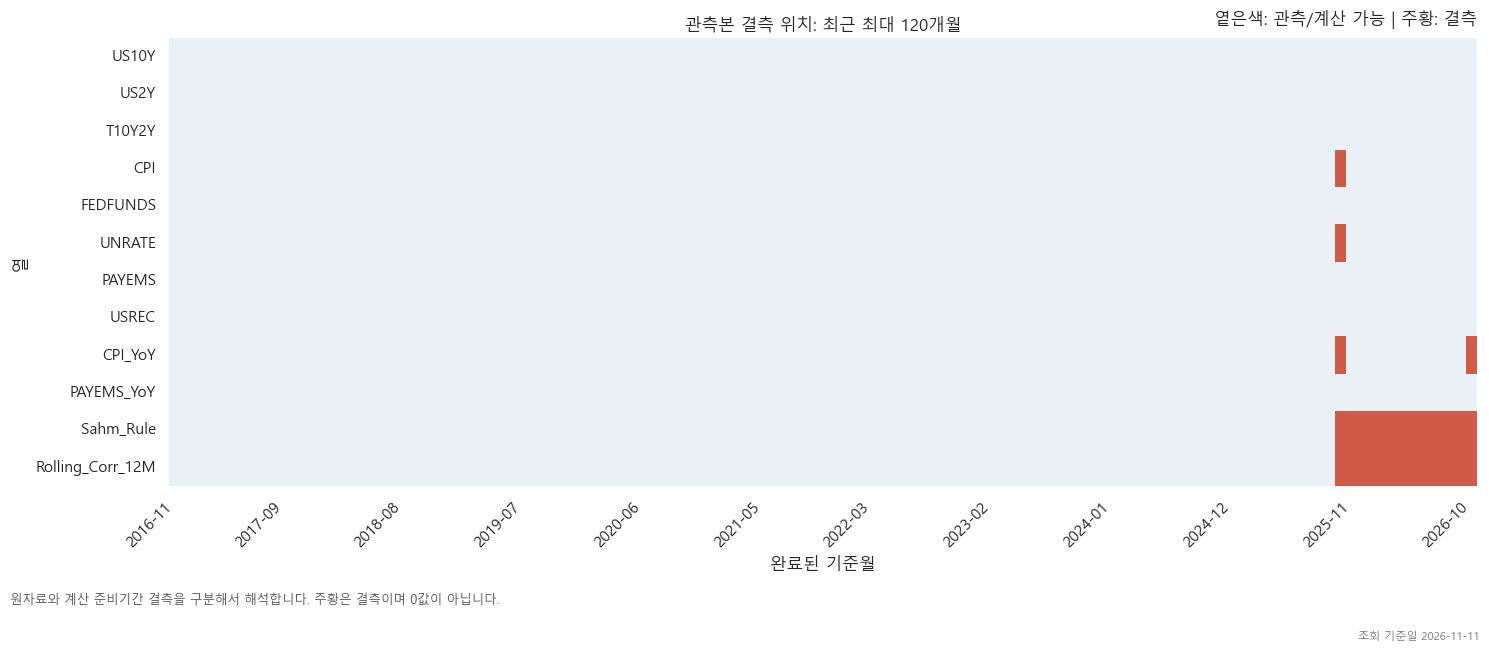

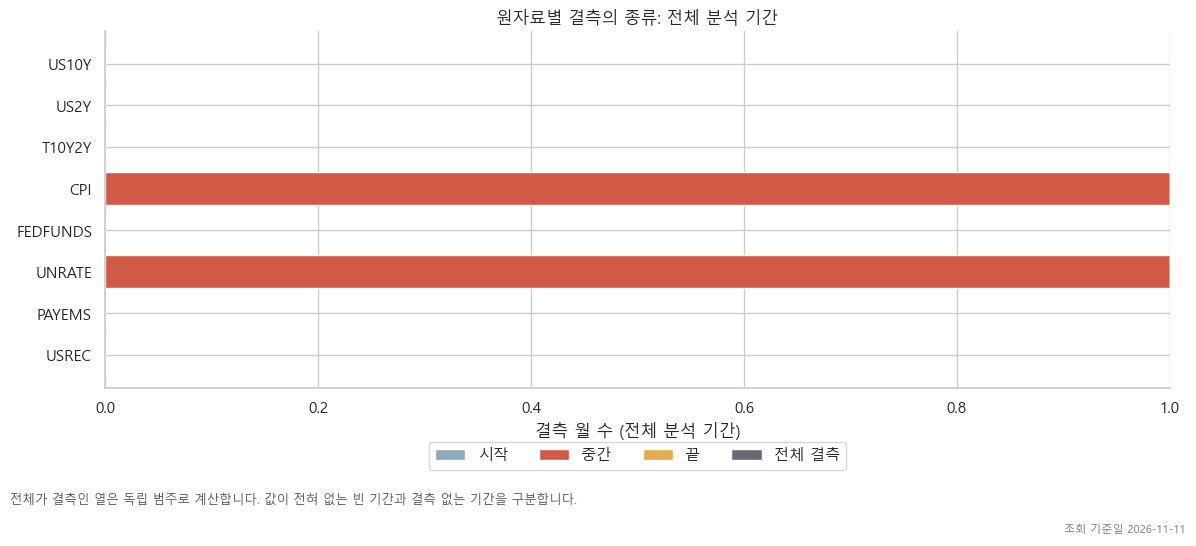

c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)


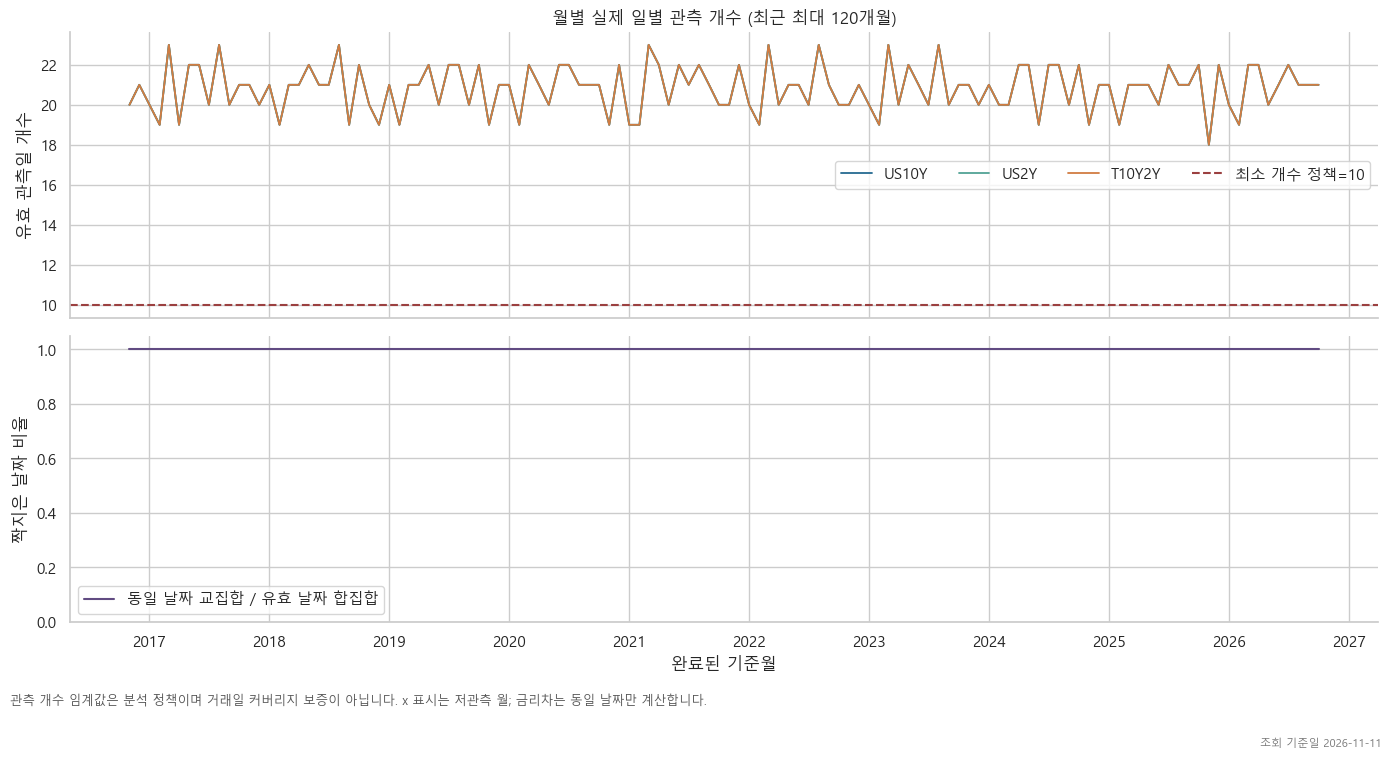

In [36]:
# ① 관측본 결측 위치: 최근 최대 120개월, 핵심 열만 표시
heat_cols = RAW_COLS + ['CPI_YoY', 'PAYEMS_YoY', 'Sahm_Rule', 'Rolling_Corr_12M']
heat = monthly_observed[heat_cols].tail(120)
fig, ax = plt.subplots(figsize=(15, 6))
if len(heat):
    sns.heatmap(heat.isna().astype(int).T, ax=ax, cmap=['#e9f1f7', '#d05a45'],
                vmin=0, vmax=1, cbar=False, xticklabels=False, yticklabels=True)
    tick_pos = np.unique(np.linspace(0, len(heat) - 1, min(12, len(heat))).astype(int))
    ax.set_xticks(tick_pos + 0.5)
    ax.set_xticklabels([heat.index[p].strftime('%Y-%m') for p in tick_pos], rotation=45, ha='right')
    ax.set_xlabel('완료된 기준월')
    ax.set_ylabel('열')
    ax.text(1, 1.03, '옅은색: 관측/계산 가능 | 주황: 결측', transform=ax.transAxes, ha='right')
else:
    ax.text(0.5, 0.5, '분석 구간에 완료 월 자료가 없습니다.', ha='center', va='center', transform=ax.transAxes)
    ax.set_axis_off()
ax.set_title('관측본 결측 위치: 최근 최대 120개월')
finish_figure(fig, 'prep_01_missing_heatmap', '원자료와 계산 준비기간 결측을 구분해서 해석합니다. 주황은 결측이며 0값이 아닙니다.')

# ② 전체 분석 기간 원자료 결측 유형
categories = ['leading_missing', 'interior_missing', 'trailing_missing', 'all_missing']
labels = ['시작', '중간', '끝', '전체 결측']
colors = ['#8faac0', '#d05a45', '#e2ad50', '#676b73']
gap_counts = quality_before.loc[RAW_COLS, categories].astype(int)
fig, ax = plt.subplots(figsize=(12, 5))
if len(monthly_observed):
    left = np.zeros(len(RAW_COLS), dtype=float)
    for category, label, color in zip(categories, labels, colors):
        values = gap_counts[category].to_numpy()
        ax.barh(RAW_COLS, values, left=left, label=label, color=color)
        left += values
    if not left.any():
        ax.text(0.5, 0.5, '분석 구간 원자료 결측 없음', transform=ax.transAxes, ha='center')
    ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.13))
    ax.set_xlabel('결측 월 수 (전체 분석 기간)')
    ax.invert_yaxis()
else:
    ax.text(0.5, 0.5, '자료가 없어 결측률·유형 비교가 불가능합니다.', transform=ax.transAxes, ha='center')
    ax.set_axis_off()
ax.set_title('원자료별 결측의 종류: 전체 분석 기간')
finish_figure(fig, 'prep_02_missing_categories', '전체가 결측인 열은 독립 범주로 계산합니다. 값이 전혀 없는 빈 기간과 결측 없는 기간을 구분합니다.')

# ③ 일별 유효 관측 수와 동일 날짜 매칭 비율
coverage = daily_monthly_stats.loc[
    (daily_monthly_stats['month'] >= analysis_start) & (daily_monthly_stats['month'] < closed_month_cutoff)
].copy()
recent_months = sorted(coverage['month'].unique())[-120:]
coverage = coverage.loc[coverage['month'].isin(recent_months)]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
if len(coverage):
    for col, color in zip(DAILY_COLS, ['#256a91', '#52a295', '#d17c42']):
        part = coverage.loc[coverage['series'].eq(col)].sort_values('month')
        axes[0].plot(part['month'], part['count'], label=col, color=color, linewidth=1.3)
        low = part['low_count'].eq(True)
        axes[0].scatter(part.loc[low, 'month'], part.loc[low, 'count'], color=color, s=18, marker='x')
    axes[0].axhline(MIN_DAILY_OBSERVATIONS, color='#9b4040', linestyle='--', label=f'최소 개수 정책={MIN_DAILY_OBSERVATIONS}')
    pair = coverage.loc[coverage['series'].eq('T10Y2Y')].sort_values('month')
    axes[1].plot(pair['month'], pair['paired_coverage_ratio'], color='#614b82', label='동일 날짜 교집합 / 유효 날짜 합집합')
    axes[1].set_ylim(0, 1.05)
    axes[0].legend(ncol=4)
    axes[1].legend()
else:
    for ax in axes:
        ax.text(0.5, 0.5, '완료 월 일별 집계 자료가 없습니다.', transform=ax.transAxes, ha='center')
axes[0].set_title('월별 실제 일별 관측 개수 (최근 최대 120개월)')
axes[0].set_ylabel('유효 관측일 개수')
axes[1].set_ylabel('짝지은 날짜 비율')
axes[1].set_xlabel('완료된 기준월')
finish_figure(fig, 'prep_03_daily_coverage', '관측 개수 임계값은 분석 정책이며 거래일 커버리지 보증이 아닙니다. x 표시는 저관측 월; 금리차는 동일 날짜만 계산합니다.')


### 2-13. 품질 시각화 ④~⑤: 실제로 추정한 위치와 과거 기준 급변

보간 전후 그림은 분석 구간의 **가장 최근 보간 사례 주변 최대 20개월**을 중심으로 CPI·UNRATE·PAYEMS를 각각 그립니다. 원관측은 선과 원형 점, EDA 사본은 점선, 실제 채운 칸만 주황 마름모로 표시합니다. 보간이 없거나 꺼져 있으면 그 사실을 표시하고 최근 관측만 제시합니다. 중간 결측 때문에 관측본 선이 끊기는 것 자체가 중요한 정보입니다. 각 패널의 단위가 다르므로 공통 y축을 쓰지 않습니다.

이상치 그림은 값 수준이 아니라 과거만으로 계산한 robust z를 사용합니다. 실제 표시 사건이 있으면 가장 최근 사건 주변 최대 120개월, 없으면 최근 최대 120개월을 보여줍니다. 임계값 안쪽·바깥쪽을 구분하되 평가 불가 구간을 0점으로 채우지 않습니다. 급변 표식은 "삭제할 오류"가 아니라 "원자료 또는 경제적 원인 검토 필요"라는 의미입니다.


c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)


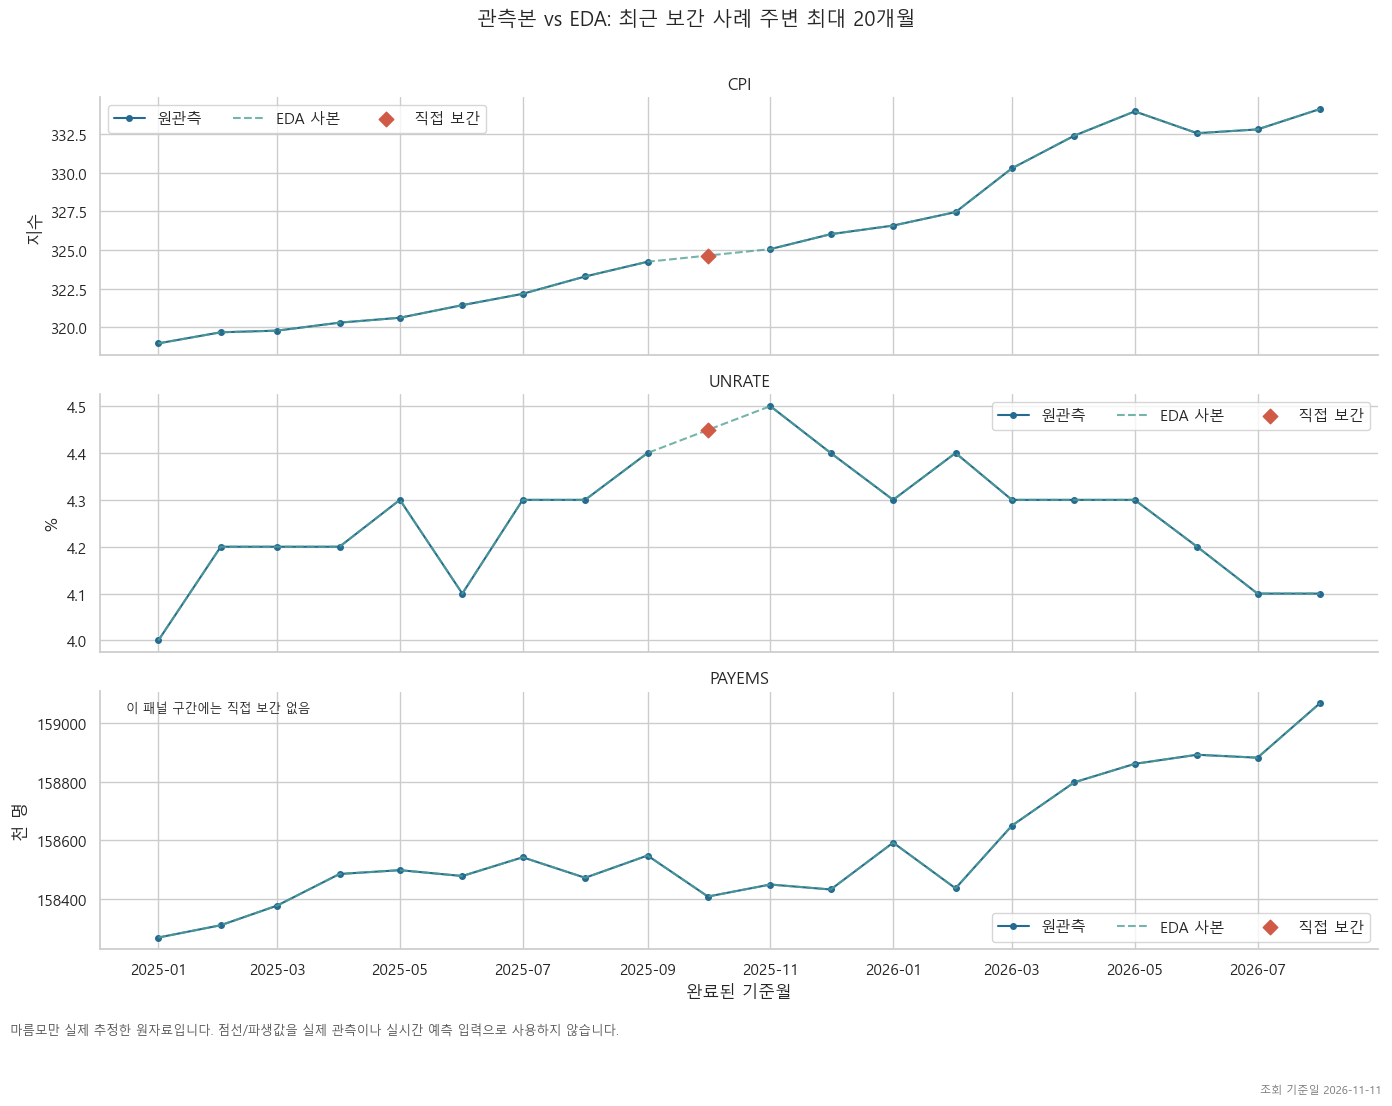

c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)
c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)
c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)
c

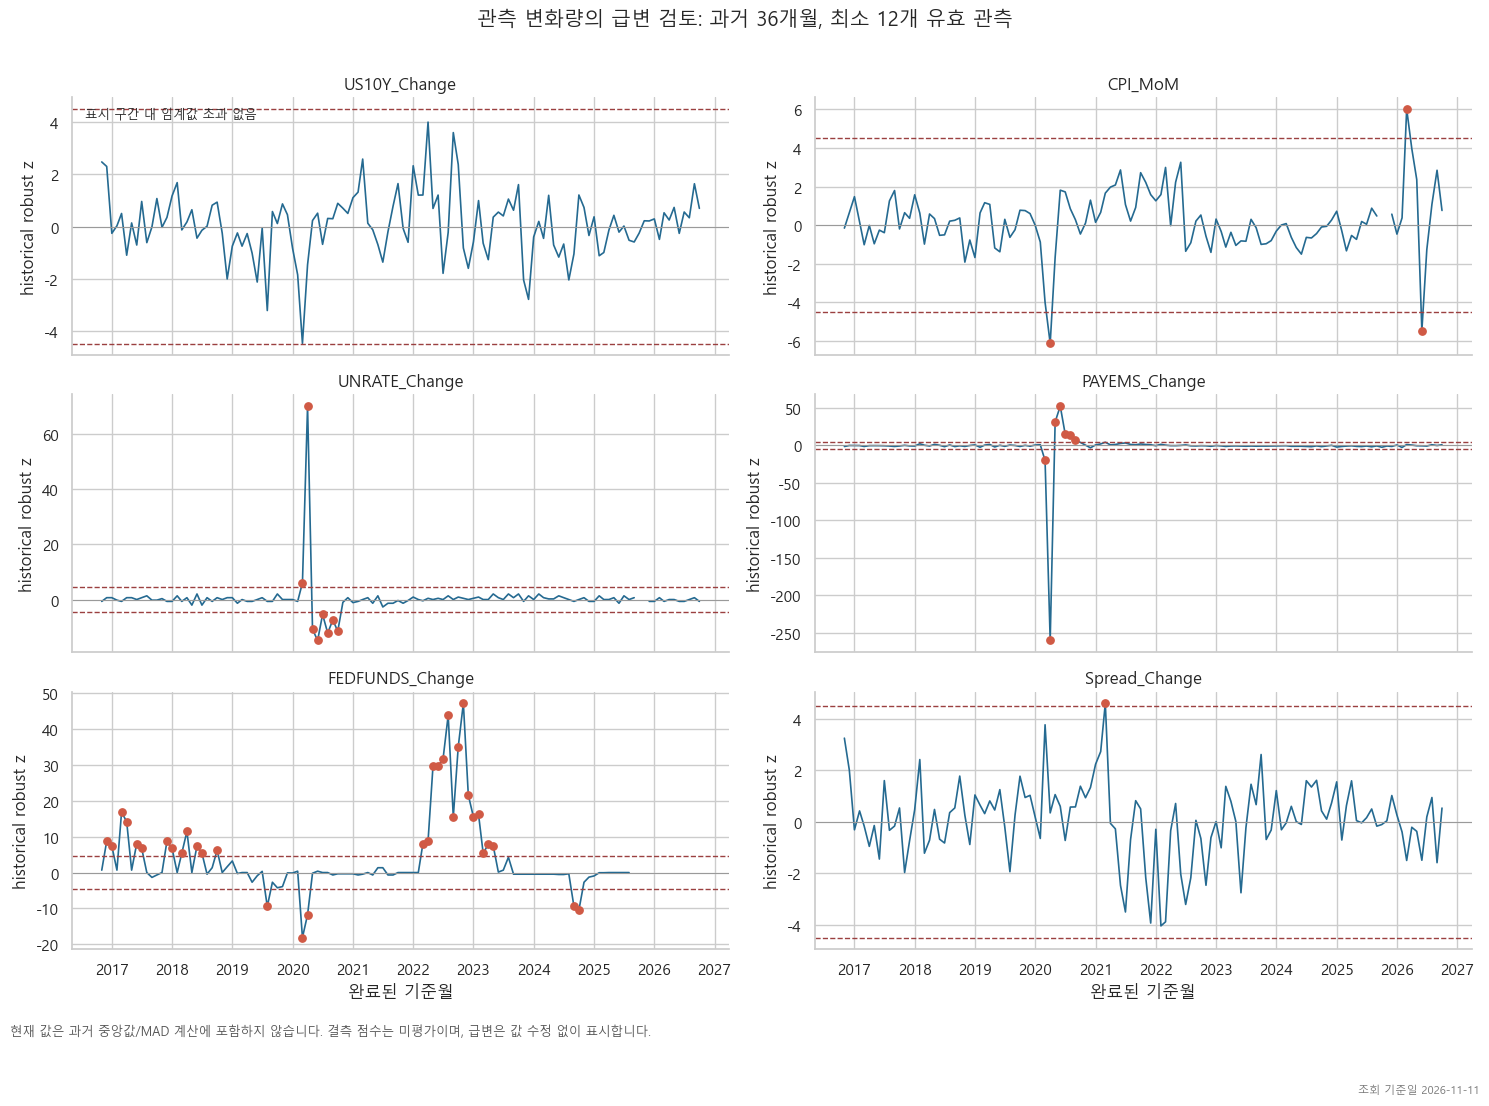

In [37]:
fillable = ['CPI', 'UNRATE', 'PAYEMS']
filled_months = imputed_mask.index[imputed_mask.any(axis=1)]
if len(monthly_observed):
    if len(filled_months):
        anchor = monthly_observed.index.get_loc(filled_months[-1])
        start_position = max(0, min(anchor - 9, len(monthly_observed) - 20))
        view_idx = monthly_observed.index[start_position:start_position + 20]
    else:
        view_idx = monthly_observed.index[-20:]
else:
    view_idx = monthly_observed.index
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, col, unit in zip(axes, fillable, ['지수', '%', '천 명']):
    if len(view_idx):
        observed = monthly_observed.loc[view_idx, col]
        eda = monthly_eda.loc[view_idx, col]
        ax.plot(view_idx, observed, marker='o', markersize=4, color='#256a91', label='원관측')
        ax.plot(view_idx, eda, linestyle='--', color='#52a295', alpha=0.8, label='EDA 사본')
        filled_here = imputed_mask.loc[view_idx, col]
        ax.scatter(view_idx[filled_here], eda.loc[filled_here], marker='D', color='#d05a45', s=55, zorder=5, label='직접 보간')
        if not filled_here.any():
            ax.text(0.02, 0.92, '이 패널 구간에는 직접 보간 없음', transform=ax.transAxes, fontsize=9)
        ax.legend(loc='best', ncol=3)
    else:
        ax.text(0.5, 0.5, '분석 구간 자료 없음', transform=ax.transAxes, ha='center')
    ax.set_title(col)
    ax.set_ylabel(unit)
if not ENABLE_EDA_INTERPOLATION:
    title_suffix = '보간 비활성화'
elif not len(filled_months):
    title_suffix = '분석 구간 보간 없음'
else:
    title_suffix = '최근 보간 사례 주변 최대 20개월'
fig.suptitle('관측본 vs EDA: ' + title_suffix, y=1.01)
axes[-1].set_xlabel('완료된 기준월')
finish_figure(fig, 'prep_04_eda_before_after', '마름모만 실제 추정한 원자료입니다. 점선/파생값을 실제 관측이나 실시간 예측 입력으로 사용하지 않습니다.')

# ⑤ 과거 기준 robust z; 로그의 실제 사건 주변으로 범위를 정합니다.
if len(outlier_log) and len(monthly_observed):
    event_date = outlier_log['month'].max()
    position = monthly_observed.index.get_loc(event_date)
    start = max(0, min(position - 59, len(monthly_observed) - 120))
    outlier_view_idx = monthly_observed.index[start:start + 120]
else:
    outlier_view_idx = monthly_observed.index[-120:]
fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
for ax, col in zip(axes.flat, OUTLIER_CHANGE_COLS):
    score = outlier_scores.loc[outlier_view_idx, col]
    flag = outlier_flags.loc[outlier_view_idx, col].fillna(False).to_numpy(dtype=bool)
    ax.plot(score.index, score, color='#256a91', linewidth=1.2)
    ax.scatter(score.index[flag], score.loc[flag], color='#d05a45', s=28, label='검토 대상', zorder=4)
    ax.axhline(OUTLIER_Z_THRESHOLD, color='#9b4040', linestyle='--', linewidth=1)
    ax.axhline(-OUTLIER_Z_THRESHOLD, color='#9b4040', linestyle='--', linewidth=1)
    ax.axhline(0, color='#999999', linewidth=0.7)
    if not score.notna().any():
        ax.text(0.5, 0.5, '평가 가능한 과거 기준 없음\n(짧은 자료/결측/과거 MAD=0)', transform=ax.transAxes, ha='center', va='center')
    elif not flag.any():
        ax.text(0.02, 0.92, '표시 구간 내 임계값 초과 없음', transform=ax.transAxes, fontsize=9)
    ax.set_title(col)
    ax.set_ylabel('historical robust z')
fig.suptitle('관측 변화량의 급변 검토: 과거 36개월, 최소 12개 유효 관측', y=1.01)
for ax in axes[-1]:
    ax.set_xlabel('완료된 기준월')
finish_figure(fig, 'prep_05_historical_outliers', '현재 값은 과거 중앙값/MAD 계산에 포함하지 않습니다. 결측 점수는 미평가이며, 급변은 값 수정 없이 표시합니다.')


### 2-14. 재현 가능한 품질 보고와 다음 분석의 경계

`preprocessing_report`는 실행 시점·설정·분석 범위와 감사 건수를 사전으로 제공합니다. 관측·EDA 월별 자료와 감사표, 직접 보간 마스크, 파생 의존성 마스크, 결측 구간·이상치 로그를 분리 저장합니다. 마스크의 False는 "그 칸을 직접 추정하지 않았다"는 뜻이지 결측이 없다는 뜻이 아닙니다. `taint_mask`는 사후 EDA 의존성의 보수적 표식이고 모든 가능한 원자료 오류를 검출하는 장치는 아닙니다.

**후속 분석 규칙:** 기본 분석과 머신러닝은 `monthly_observed`만 참조합니다. EDA 비교를 선택하면 표·그림 제목에 명시하고 추정 의존 칸을 함께 보고합니다. `dropna(subset=...)`는 해당 분석의 필요한 열에만 적용하며 삭제한 월 수를 기록합니다. 결측을 0으로 바꾸거나 파생변수를 직접 보간하지 않습니다. 학습 imputer·scaler는 미래와 테스트 구간에 적합하지 않고 훈련 구간에서만 적합합니다.

보고의 완료 월 기준은 발표일의 대용물이 아닙니다. 실제 PIT 모델은 발표일·빈티지 검증을 별도로 해야 하며, 아래 순수 함수는 해당 호출자가 허용한 과거 자료만 전달받아 같은 계산식을 적용하는 역할입니다. `build_monthly_base`와 `add_derived_features`는 7개 시리즈가 모두 비어 있는 초기 과거 구간에서도 고정 열 스키마를 반환합니다.


In [38]:
analysis_daily_stats = daily_monthly_stats.loc[
    (daily_monthly_stats['month'] >= analysis_start) & (daily_monthly_stats['month'] < closed_month_cutoff)
].copy()
preprocessing_report = {
    'snapshot_ts': SNAPSHOT_TS.isoformat(), 'analysis_start': analysis_start.isoformat(),
    'closed_month_cutoff_exclusive': closed_month_cutoff.isoformat(),
    'first_analysis_month': monthly_observed.index.min().isoformat() if len(monthly_observed) else None,
    'last_analysis_month': monthly_observed.index.max().isoformat() if len(monthly_observed) else None,
    'analysis_months': int(len(monthly_observed)), 'analysis_columns': int(len(monthly_observed.columns)),
    'available_closed_warmup_months': int(len(monthly_base_warmup)),
    'pre_start_closed_months': int((monthly_base_warmup.index < analysis_start).sum()),
    'raw_input_rows': int(raw_audit['input_rows'].sum()),
    'raw_original_missing': int(raw_audit['original_missing'].sum()),
    'raw_invalid_cells': int(raw_audit['invalid_total'].sum()),
    'series_sorted_in_copy': int(raw_audit['sorted_copy_created'].sum()),
    'calendar_month_rows_inserted_all_periods': int(len(calendar_inserted_months)),
    'partial_or_future_months_retained_separately': int(len(partial_month_table)),
    'min_daily_observations': int(MIN_DAILY_OBSERVATIONS),
    'low_count_series_months_analysis': int(analysis_daily_stats['low_count'].eq(True).sum()),
    'observed_missing_cells': int(monthly_observed.isna().to_numpy().sum()),
    'eda_missing_cells': int(monthly_eda.isna().to_numpy().sum()),
    'eda_interpolation_enabled': bool(ENABLE_EDA_INTERPOLATION), 'max_gap': int(MAX_GAP),
    'direct_imputed_cells_analysis': int(imputed_mask.to_numpy().sum()),
    'direct_imputed_cells_including_warmup': int(imputed_mask_warmup.to_numpy().sum()),
    'dependency_tainted_cells_analysis': int(taint_mask.to_numpy().sum()),
    'outlier_flagged_cells': int(outlier_flags.fillna(False).to_numpy(dtype=bool).sum()),
    'outlier_unassessed_cells': int(outlier_flags.isna().to_numpy().sum()),
    'outlier_threshold': float(OUTLIER_Z_THRESHOLD), 'outlier_window': 36, 'outlier_min_history': 12,
    'global_dropna_used': False, 'ml_source': 'monthly_observed',
    'eda_is_point_in_time_safe': False, 'vintage_and_release_validation': 'not_performed_here',
}
preprocessing_tables = {
    'monthly_base_observed': monthly_base, 'monthly_observed': monthly_observed,
    'monthly_eda': monthly_eda, 'raw_audit': raw_audit, 'raw_invalid_log': raw_invalid_log,
    'daily_monthly_stats': daily_monthly_stats, 'analysis_daily_monthly_stats': analysis_daily_stats,
    'partial_month_table': partial_month_table, 'partial_daily_monthly_stats': partial_daily_monthly_stats,
    'quality_before': quality_before, 'quality_after': quality_after,
    'gap_intervals': gap_intervals, 'missing_comparison': missing_comparison,
    'impute_log': impute_log, 'imputed_mask': imputed_mask, 'taint_mask': taint_mask,
    'data_dictionary': data_dictionary, 'warmup_impact': warmup_impact,
    'corr_input_quality': corr_input_quality, 'outlier_flags': outlier_flags,
    'outlier_scores': outlier_scores, 'outlier_details': outlier_details,
    'outlier_log': outlier_log, 'outlier_summary': outlier_summary,
}
for name, table in preprocessing_tables.items():
    table.to_csv(Path(TABLE_DIR) / f'{name}.csv', encoding='utf-8-sig', index=True)
# 관측/EDA 비교에 영향을 줄 수 있는 준비기간 보간도 별도 저장합니다.
imputed_mask_warmup.to_csv(Path(TABLE_DIR) / 'imputed_mask_including_warmup.csv', encoding='utf-8-sig')
taint_mask_warmup.to_csv(Path(TABLE_DIR) / 'taint_mask_including_warmup.csv', encoding='utf-8-sig')
pd.Series(preprocessing_report, name='value').to_csv(Path(TABLE_DIR) / 'preprocessing_report.csv', encoding='utf-8-sig')
print('전처리 요약 (실제 실행 입력으로 계산):')
display(pd.Series(preprocessing_report, name='value').to_frame())
print('관측본과 EDA 사본을 구분해 저장했습니다. 다음 분석의 monthly는 관측본입니다.')


전처리 요약 (실제 실행 입력으로 계산):


,value
snapshot_ts,2026-11-11T00:00:00
analysis_start,1990-01-01T00:00:00
closed_month_cutoff_exclusive,2026-11-01T00:00:00
first_analysis_month,1990-01-01T00:00:00
last_analysis_month,2026-10-01T00:00:00
analysis_months,442
analysis_columns,37
available_closed_warmup_months,466
pre_start_closed_months,24
raw_input_rows,22604


관측본과 EDA 사본을 구분해 저장했습니다. 다음 분석의 monthly는 관측본입니다.


## 3. 상세 분석·시각화: 관측 자료를 기준으로 읽기

이 절은 완료된 월의 **관측 자료 `monthly_observed`**를 기본으로 사용합니다. 보간 자료 `monthly_eda`는 마지막 민감도 비교에서만 사용합니다. 회색 음영은 관측된 NBER 침체 구간이며, `USREC` 결측을 확장기로 바꾸지 않습니다. 각 그림의 결측 구간은 연결하지 않고, 유효 표본이 없으면 안내 문구만 표시합니다.

금리 수준·실업률은 **%**, 금리차·실업률 변화는 **%p**, 금리 변화의 bp는 **%p × 100**입니다. CPI 증가율은 %, 고용 수준은 백만 명, 고용 증감은 천 명입니다. 모든 표는 `viz_tables`에 모아 `TABLE_DIR`에 CSV로 저장하고, 그림은 공통 `finish_figure`로 PNG·SVG 저장합니다. 발표 시차·사후 수정이 존재하므로 이 분석은 실시간 투자 또는 침체 예측 검증이 아닙니다.


In [39]:
viz_tables = {}
# 부모 전처리 결과를 변경하지 않는 지역 사본. 현재 월 및 이후 월은 방어적으로 제외.
_v_asof = pd.Timestamp(globals().get('AS_OF', pd.Timestamp.today()))
_v_cutoff = _v_asof.to_period('M').to_timestamp()
_V = monthly_observed.loc[monthly_observed.index < _v_cutoff].copy().sort_index()
_v_colors = dict(COLORS)
_v_labels = {
    'US10Y':'10년물 금리', 'US2Y':'2년물 금리', 'T10Y2Y':'10년−2년 금리차',
    'CPI_YoY':'CPI 전년동월비', 'CPI_MoM':'CPI 전월비', 'FEDFUNDS':'연방기금금리',
    'UNRATE':'실업률', 'PAYEMS':'비농업 고용', 'Yield_Spread':'10년−2년 금리차',
    'US10Y_Change':'10년물 전월 변화', 'US10Y_3M_Change':'10년물 3개월 변화',
    'CPI_3M_Annualized':'CPI 3개월 연율', 'CPI_6M_Annualized':'CPI 6개월 연율',
    'UNRATE_3M':'실업률 3개월 평균', 'Sahm_Rule':'Sahm 근사 지표',
    'PAYEMS_Change':'고용 전월 증감', 'PAYEMS_Change_3M_Mean':'고용 증감 3개월 평균',
    'UNRATE_Change':'실업률 전월 변화', 'FEDFUNDS_Change':'정책금리 전월 변화',
    'Spread_Change':'금리차 전월 변화', 'ExPost_Real_US10Y':'10년물−실현 CPI 전년비',
    'ExPost_Real_FEDFUNDS':'연방기금금리−실현 CPI 전년비',
    'USREC':'NBER 침체 지표',
}

def _vs(col, data=None):
    data = _V if data is None else data
    s = data[col] if col in data.columns else pd.Series(np.nan, index=data.index)
    a = pd.to_numeric(s, errors='coerce').to_numpy(dtype=float, na_value=np.nan, copy=True)
    a[~np.isfinite(a)] = np.nan
    return pd.Series(a, index=data.index, name=col)

def _vf(data, cols):
    return pd.DataFrame({c:_vs(c, data) for c in cols}, index=data.index)

def _vempty(ax, text='유효 관측값 또는 필요한 표본이 없습니다.'):
    ax.text(.5, .5, text, transform=ax.transAxes, ha='center', va='center',
            fontsize=11, color='#666666', wrap=True)

def _vline(ax, col, label=None, scale=1.0, data=None, color=None, **kwargs):
    s = _vs(col, data) * scale
    if s.notna().any():
        ax.plot(s.index, s.to_numpy(dtype=float, na_value=np.nan),
                label=label or _v_labels.get(col,col),
                color=color or _v_colors.get(col, '#58738A'), **kwargs)
        return True
    return False

def _vstyle(ax, title, ylabel, data=None, shade=True, zero=False):
    ax.set_title(title, loc='left', fontsize=12, pad=9)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('관측 기준월')
    ax.grid(True, alpha=.22)
    ax.spines[['top','right']].set_visible(False)
    had_data = bool(ax.lines or ax.collections)
    if zero:
        ax.axhline(0, color='#777777', lw=.8, ls='--')
    if shade:
        shade_recessions(ax, _vs('USREC', data))
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(handles, labels, loc='best', fontsize=9, frameon=False)
    if not had_data:
        _vempty(ax)

def _vsave_table(name, table, show=True):
    viz_tables[name] = table.copy()
    Path(TABLE_DIR).mkdir(parents=True, exist_ok=True)
    table.to_csv(Path(TABLE_DIR) / ('macro_' + name + '.csv'), encoding='utf-8-sig', index=True)
    if show:
        display(table)

def _vcorr(data, cols, method='pearson', min_n=None):
    min_n = MIN_CORR_PAIRS if min_n is None else min_n
    d = _vf(data, cols)
    counts = d.notna().astype('int64').T.dot(d.notna().astype('int64'))
    corr = pd.DataFrame(np.nan, index=cols, columns=cols, dtype=float)
    for a in cols:
        for b in cols:
            z = d[[a,b]].dropna() if a != b else d[[a]].dropna()
            if len(z) < min_n or z[a].nunique() < 2 or z[b].nunique() < 2:
                continue
            x, y = z[a], z[b]
            if method == 'spearman':
                x, y = x.rank(method='average'), y.rank(method='average')
            corr.loc[a,b] = x.corr(y)
    return corr, counts

def _vheat(ax, matrix, title, kind='corr', min_n=None):
    ax.set_title(title, loc='left', fontsize=12)
    ax.grid(False)
    if matrix.empty or (kind == 'corr' and not matrix.notna().any().any()):
        _vempty(ax, '최소 표본수 미달 또는 상수 열: 표시할 상관계수가 없습니다.')
        ax.set_axis_off()
        return
    # 표본수 그림에도 임계값 마스크를 적용. 원래 표본수는 CSV에 모두 보존.
    mask = matrix.isna()
    if kind == 'count' and min_n is not None:
        mask = mask | (matrix < min_n)
    if mask.all().all():
        _vempty(ax, '최소 표본수 미달: 모든 셀이 마스킹되었습니다.')
        ax.set_axis_off()
        return
    sns.heatmap(matrix, mask=mask, ax=ax, cmap='RdBu_r' if kind=='corr' else 'Blues',
                vmin=-1 if kind=='corr' else 0, vmax=1 if kind=='corr' else None,
                center=0 if kind=='corr' else None, annot=len(matrix)<=8,
                fmt='.2f' if kind=='corr' else '.0f', square=True,
                cbar_kws={'label':'상관계수 (−1~1)' if kind=='corr' else '동시 유효 월 수 (개)'})
    ax.set_xticklabels([_v_labels.get(c,c) for c in matrix.columns], rotation=40, ha='right', fontsize=9)
    ax.set_yticklabels([_v_labels.get(c,c) for c in matrix.index], rotation=0, fontsize=9)

def _vruns(s, target=1):
    # 결측은 별도 경계. 데이터 시작/끝 또는 결측 인접 구간은 검열 표시.
    s = pd.Series(s.to_numpy(dtype=float, na_value=np.nan), index=s.index)
    out, i = [], 0
    while i < len(s):
        if pd.isna(s.iloc[i]) or s.iloc[i] != target:
            i += 1
            continue
        start = i
        while i + 1 < len(s) and pd.notna(s.iloc[i+1]) and s.iloc[i+1] == target:
            i += 1
        end = i
        left = start == 0 or pd.isna(s.iloc[start-1])
        right = end == len(s)-1 or pd.isna(s.iloc[end+1])
        out.append({'observed_start':s.index[start], 'observed_end':s.index[end],
                    'observed_months':end-start+1, 'left_censored':left, 'right_censored':right,
                    'left_boundary':'자료 시작' if start==0 else ('결측 경계' if left else '관측 전환'),
                    'right_boundary':'자료 끝' if end==len(s)-1 else ('결측 경계' if right else '관측 전환')})
        i += 1
    return out

_v_corr_cols = [c for c in CORR_COLS if c in _V.columns]
print(f'시각화 관측 월 수: {len(_V)} | 보간값을 기본 그림에 사용하지 않습니다.')


시각화 관측 월 수: 442 | 보간값을 기본 그림에 사용하지 않습니다.


### 3-1. 전체 거시 환경: 6개 축

금리·물가·노동시장·금리차를 각각의 단위 축에서 비교합니다. 두 국채 금리는 같은 % 축에 올리고, 고용 수준은 원자료 천 명을 1,000으로 나누어 백만 명으로 표시합니다. 음영과 지표의 동행은 묘사일 뿐 인과관계를 입증하지 않습니다.


c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)
C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


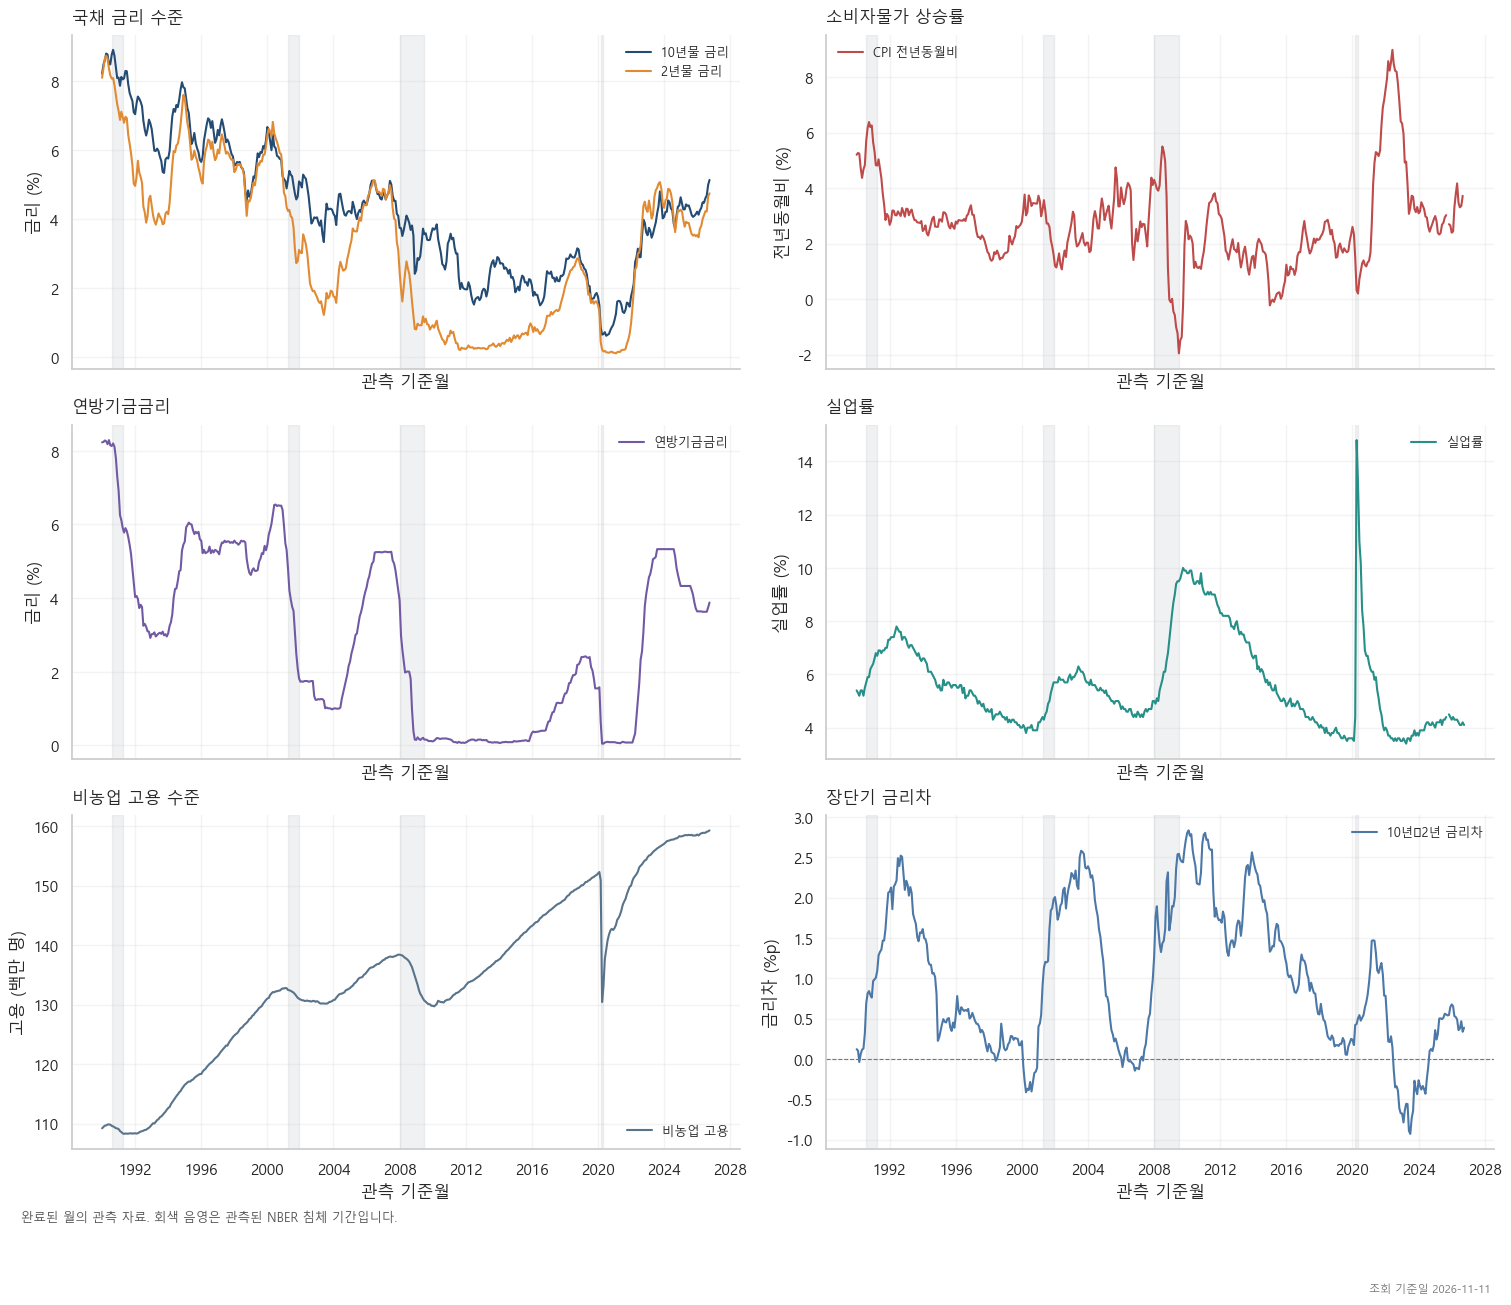

In [40]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True, constrained_layout=True)
specs = [(['US10Y','US2Y'],'국채 금리 수준','금리 (%)',1),
         (['CPI_YoY'],'소비자물가 상승률','전년동월비 (%)',1),
         (['FEDFUNDS'],'연방기금금리','금리 (%)',1),
         (['UNRATE'],'실업률','실업률 (%)',1),
         (['PAYEMS'],'비농업 고용 수준','고용 (백만 명)',.001),
         (['T10Y2Y'],'장단기 금리차','금리차 (%p)',1)]
for ax, (cols,title,unit,scale) in zip(axes.flat,specs):
    plotted = any([_vline(ax,c,scale=scale) for c in cols])
    _vstyle(ax,title,unit,zero=cols==['T10Y2Y'])
    if not plotted:
        _vempty(ax)
finish_figure(fig,'macro_overview_6panel',caption='완료된 월의 관측 자료. 회색 음영은 관측된 NBER 침체 기간입니다.')


### 3-2. 최근 흐름: 같은 단위끼리 겹쳐 보기

최근 `RECENT_MONTHS`개 달의 금리·CPI 전년비와 노동시장 변화에 집중합니다. 상단은 % 축, 하단은 실업률과 3개월 평균의 % 축입니다. 물가 상승률과 금리의 수치 차이는 가격지수와 할인율이라는 서로 다른 개념의 비교임을 유의합니다.


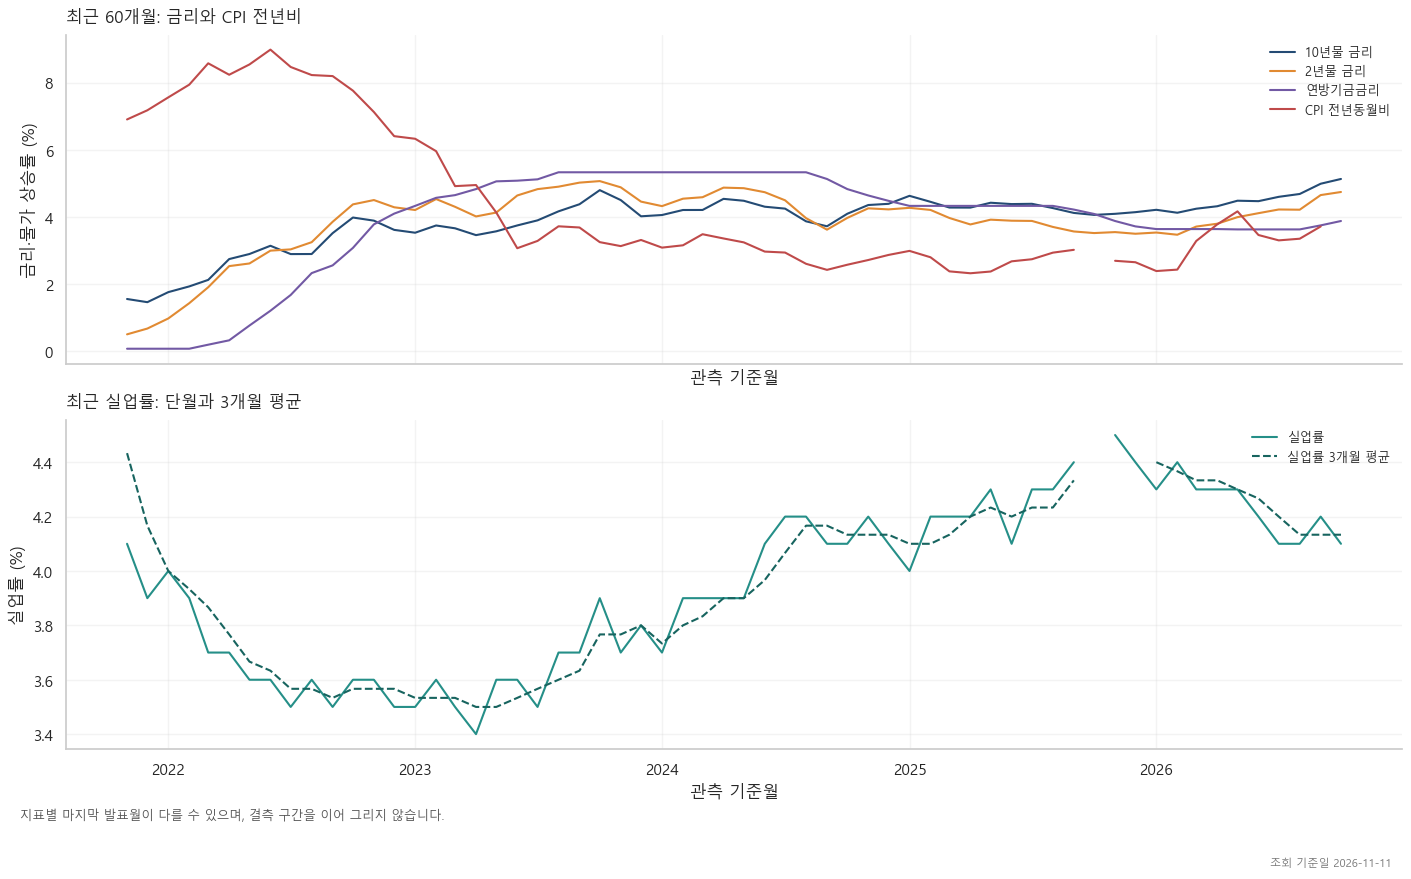

In [41]:
_v_recent = _V.tail(RECENT_MONTHS)
fig, axes = plt.subplots(2,1,figsize=(14,8),sharex=True,constrained_layout=True)
for c in ['US10Y','US2Y','FEDFUNDS','CPI_YoY']:
    _vline(axes[0],c,data=_v_recent)
_vstyle(axes[0],f'최근 {RECENT_MONTHS}개월: 금리와 CPI 전년비','금리·물가 상승률 (%)',data=_v_recent)
_vline(axes[1],'UNRATE',data=_v_recent)
_vline(axes[1],'UNRATE_3M',data=_v_recent,color='#17645F',ls='--')
_vstyle(axes[1],'최근 실업률: 단월과 3개월 평균','실업률 (%)',data=_v_recent)
finish_figure(fig,'macro_recent_overlay',caption='지표별 마지막 발표월이 다를 수 있으며, 결측 구간을 이어 그리지 않습니다.')


### 3-3. 국채 금리의 수준·변화·월말 집계

금리 변화는 상대 변화율 대신 bp로 읽습니다. **1%p = 100bp**이며 전월 변화와 3개월 누적 변화는 기간이 다릅니다. 일별 `raw_clean`의 DGS10/US10Y 관측 자료가 있을 때만 월평균과 마지막 관측일 금리를 비교합니다. 월말 휴일에는 마지막 거래·관측일 값이므로 달력상 말일 금리라는 뜻이 아닙니다. 알 수 없는 `daily_monthly_stats` 열에는 의존하지 않습니다.


c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)
c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)


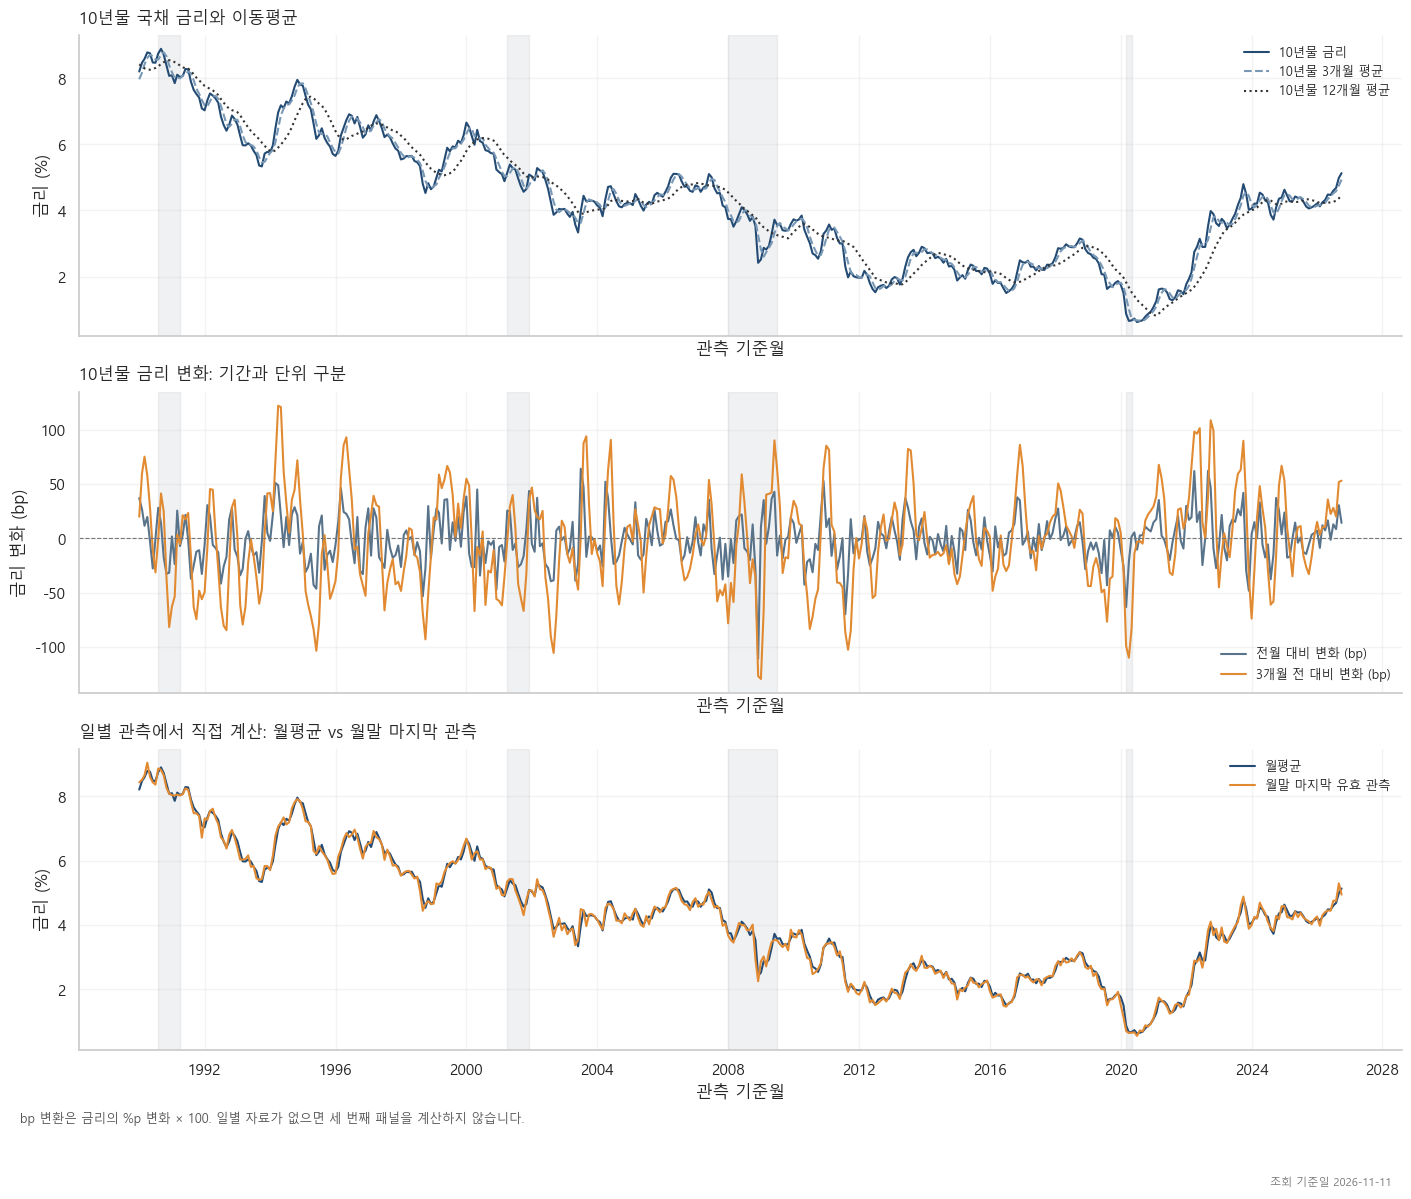

In [42]:
fig, axes = plt.subplots(3,1,figsize=(14,11),sharex=True,constrained_layout=True)
_vline(axes[0],'US10Y')
_vline(axes[0],'US10Y_MA3',label='10년물 3개월 평균',color='#7898B5',ls='--')
_vline(axes[0],'US10Y_MA12',label='10년물 12개월 평균',color='#333333',ls=':')
_vstyle(axes[0],'10년물 국채 금리와 이동평균','금리 (%)')
_vline(axes[1],'US10Y_Change',scale=100,label='전월 대비 변화 (bp)')
_vline(axes[1],'US10Y_3M_Change',scale=100,label='3개월 전 대비 변화 (bp)',color='#E18A32')
_vstyle(axes[1],'10년물 금리 변화: 기간과 단위 구분','금리 변화 (bp)',zero=True)
_v_daily = None
_v_raw = globals().get('raw_clean')
if isinstance(_v_raw,(dict,pd.DataFrame)):
    for _k in ['DGS10','US10Y']:
        if _k in _v_raw:
            candidate = _v_raw[_k]
            if isinstance(candidate,pd.Series) and isinstance(candidate.index,pd.DatetimeIndex):
                # 실제 일별 관측임을 확인: 한 달에 2개 이상 유효 관측이 있는 달 필요.
                candidate = pd.to_numeric(candidate,errors='coerce').sort_index()
                candidate = candidate.replace([np.inf,-np.inf],np.nan)
                candidate = candidate.loc[candidate.index < _v_cutoff]
                if (candidate.resample('MS').count() > 1).any():
                    _v_daily = candidate
                    break
if _v_daily is not None:
    agg = pd.DataFrame({'월평균':_v_daily.resample('MS').mean(),
                        '월말 마지막 유효 관측':_v_daily.resample('MS').last(),
                        '일별 유효 관측수':_v_daily.resample('MS').count()}).reindex(_V.index)
    for c,color in [('월평균','#244B74'),('월말 마지막 유효 관측','#E18A32')]:
        axes[2].plot(agg.index,agg[c].to_numpy(dtype=float,na_value=np.nan),label=c,color=color)
    _vsave_table('daily_mean_eop',agg,show=False)
else:
    _vempty(axes[2],'사용 가능한 일별 raw_clean 금리 없음: 월평균·월말 비교를 생략합니다.')
_vstyle(axes[2],'일별 관측에서 직접 계산: 월평균 vs 월말 마지막 관측','금리 (%)')
finish_figure(fig,'macro_yield_levels_changes',caption='bp 변환은 금리의 %p 변화 × 100. 일별 자료가 없으면 세 번째 패널을 계산하지 않습니다.')


### 3-4. 금리 변화의 연도×월 히트맵

10년물 금리의 **전월 대비 bp 변화**를 월별 달력 형태로 배치합니다. 붉은색은 상승, 파란색은 하락이며 0을 중심으로 대칭 색 범위를 사용합니다. 빠진 달과 아직 없는 미래 달은 마스킹하고 0으로 채우지 않습니다.


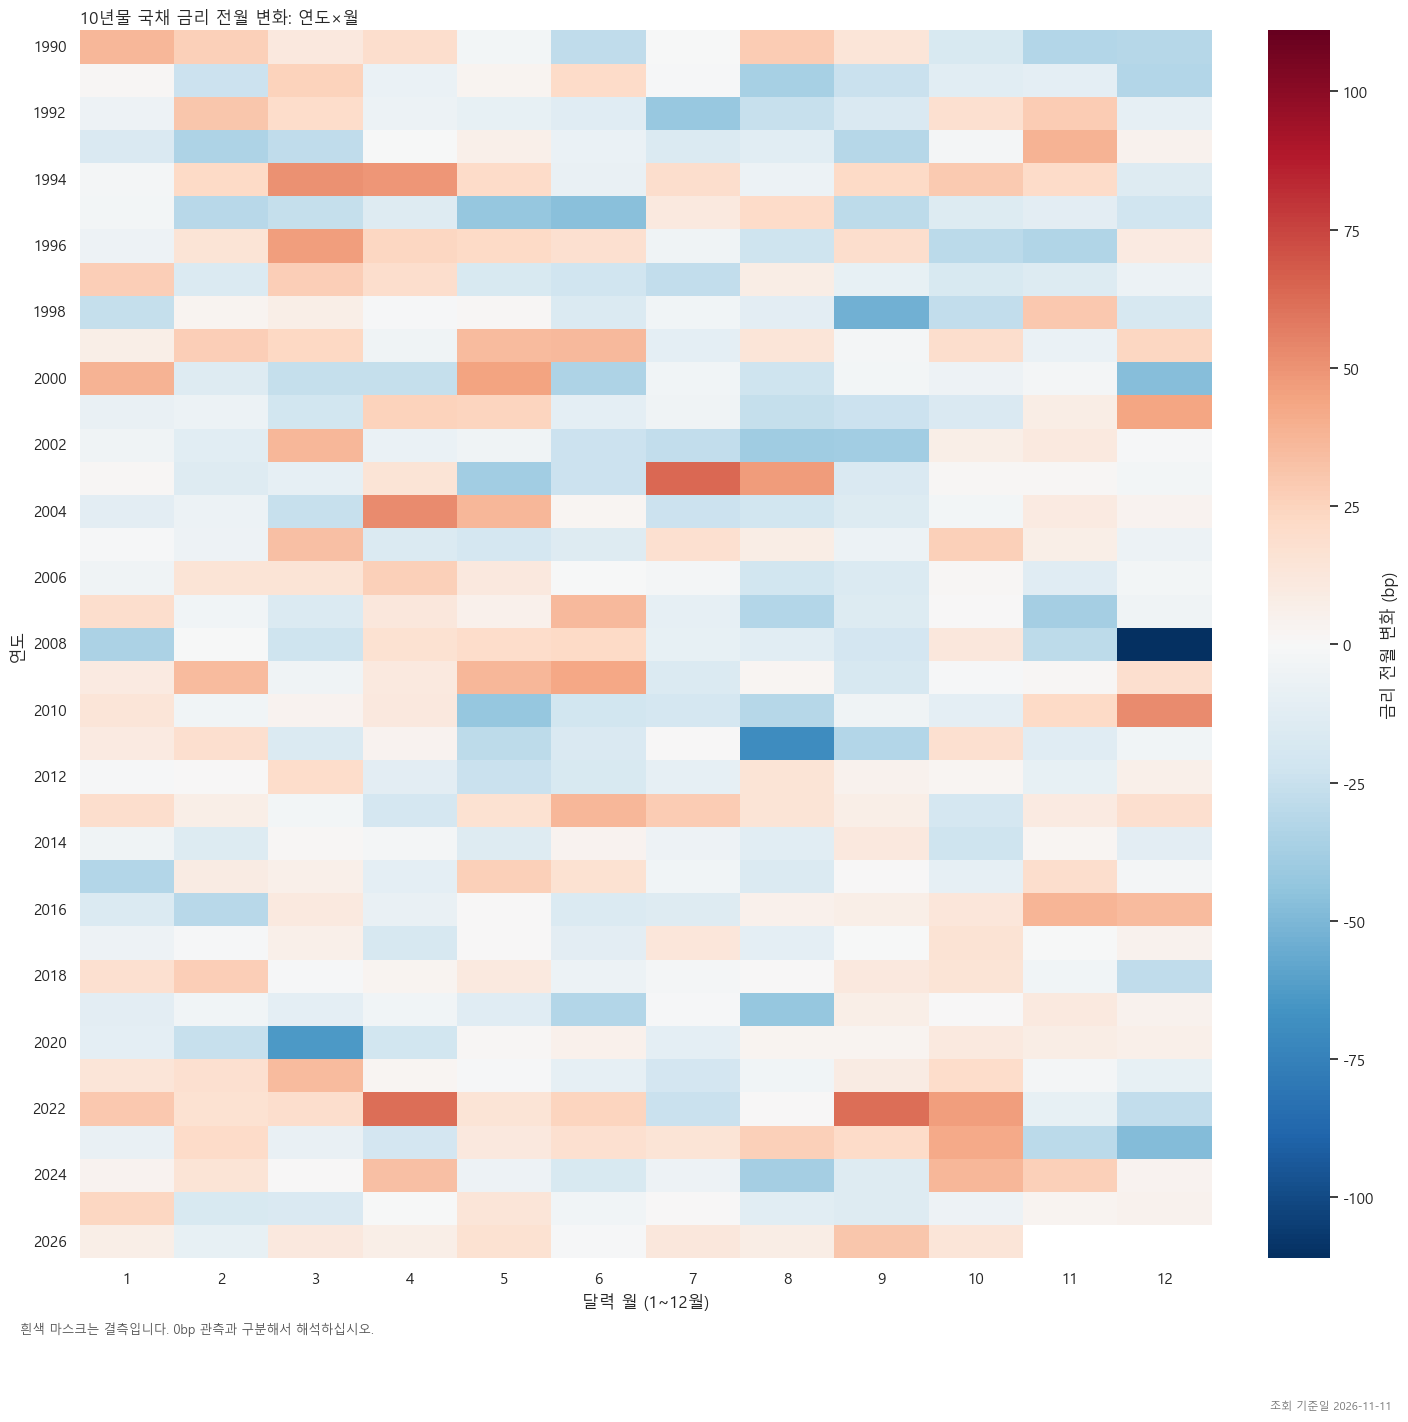

In [43]:
s = _vs('US10Y_Change') * 100
h = pd.DataFrame({'연도':s.index.year,'월':s.index.month,'변화_bp':s.to_numpy(dtype=float,na_value=np.nan)})
h = h.pivot(index='연도',columns='월',values='변화_bp').reindex(columns=range(1,13)) if len(h) else pd.DataFrame(columns=range(1,13))
fig,ax = plt.subplots(figsize=(14,max(4,min(14,len(h)*.30+2))),constrained_layout=True)
if h.notna().any().any():
    vals = np.abs(h.to_numpy(dtype=float,na_value=np.nan))
    lim = float(np.nanmax(vals))
    # 전부 0인 관측에서도 색 축만 비퇴화하도록 설정; 관측값 자체는 변경하지 않음.
    lim = lim if lim > 0 else 1.0
    sns.heatmap(h,mask=h.isna(),cmap='RdBu_r',center=0,vmin=-lim,vmax=lim,
                annot=len(h)<=12,fmt='.0f',ax=ax,cbar_kws={'label':'금리 전월 변화 (bp)'})
    if len(h)>30:
        locs = np.arange(0,len(h),2)
        ax.set_yticks(locs+.5)
        ax.set_yticklabels(h.index[locs],rotation=0)
else:
    _vempty(ax)
ax.set_title('10년물 국채 금리 전월 변화: 연도×월',loc='left')
ax.set_xlabel('달력 월 (1~12월)'); ax.set_ylabel('연도'); ax.grid(False)
_vsave_table('yield_month_heatmap',h,show=False)
finish_figure(fig,'macro_yield_month_heatmap',caption='흰색 마스크는 결측입니다. 0bp 관측과 구분해서 해석하십시오.')


### 3-5. 물가: YoY·MoM·단기 연율을 분리

CPI 전년동월비는 12개월 누적 변화를, 전월비는 단월 변화를 보여 줍니다. 3·6개월 연율은 각각 최근 가격 변화가 1년간 지속된다고 환산한 값으로 **예측이 아닙니다**. 작은 전월비가 다른 선에 가려지지 않도록 세 패널의 y축을 독립적으로 둡니다.


c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)


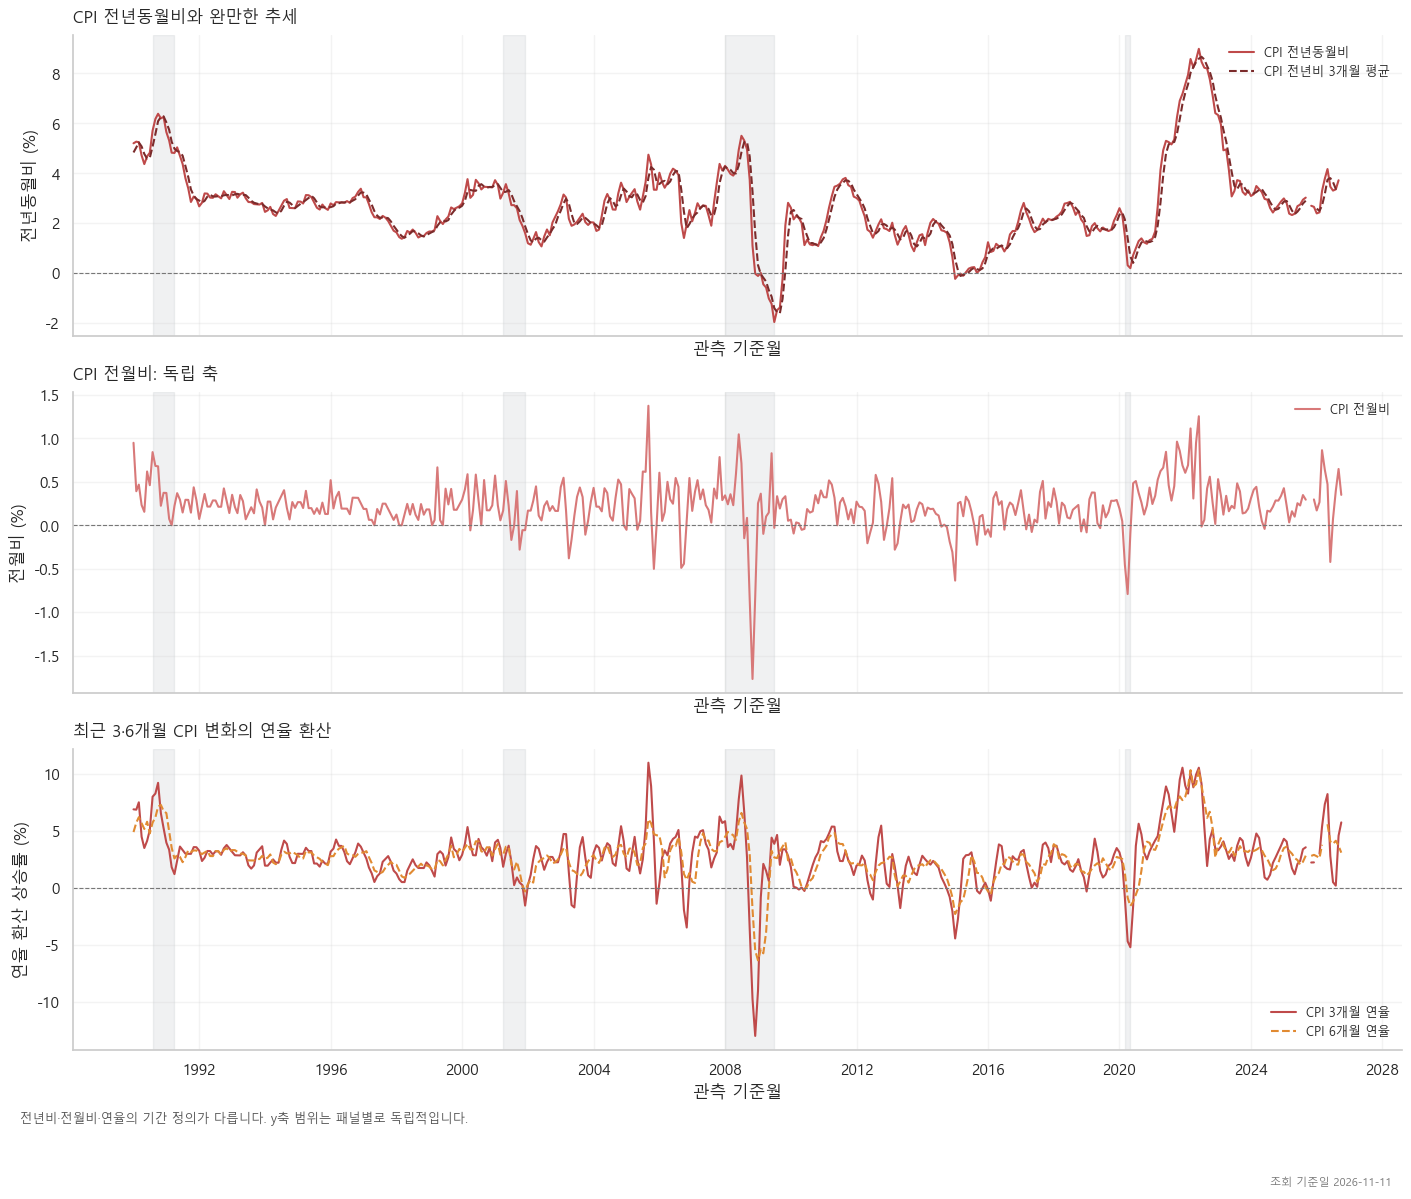

In [44]:
fig,axes = plt.subplots(3,1,figsize=(14,11),sharex=True,constrained_layout=True)
_vline(axes[0],'CPI_YoY')
_vline(axes[0],'CPI_YoY_MA3',label='CPI 전년비 3개월 평균',color='#7B2B2B',ls='--')
_vstyle(axes[0],'CPI 전년동월비와 완만한 추세','전년동월비 (%)',zero=True)
_vline(axes[1],'CPI_MoM',color='#D87979')
_vstyle(axes[1],'CPI 전월비: 독립 축','전월비 (%)',zero=True)
_vline(axes[2],'CPI_3M_Annualized',color='#BF4A4A')
_vline(axes[2],'CPI_6M_Annualized',color='#E18A32',ls='--')
_vstyle(axes[2],'최근 3·6개월 CPI 변화의 연율 환산','연율 환산 상승률 (%)',zero=True)
finish_figure(fig,'macro_inflation_horizons',caption='전년비·전월비·연율의 기간 정의가 다릅니다. y축 범위는 패널별로 독립적입니다.')


### 3-6. 명목금리와 실현 물가의 사후 차이

`ExPost_Real_US10Y`와 `ExPost_Real_FEDFUNDS`는 명목금리에서 **실현된 CPI 전년비**를 뺀 사후 비교값입니다. 시장 기대 인플레이션을 반영한 실질금리 또는 TIPS 수익률이 아니며, 10년 투자기간과 1년 실현 물가의 기간도 일치하지 않습니다. 할인율·물가 비교를 위한 설명용 근사치로만 사용합니다.


C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


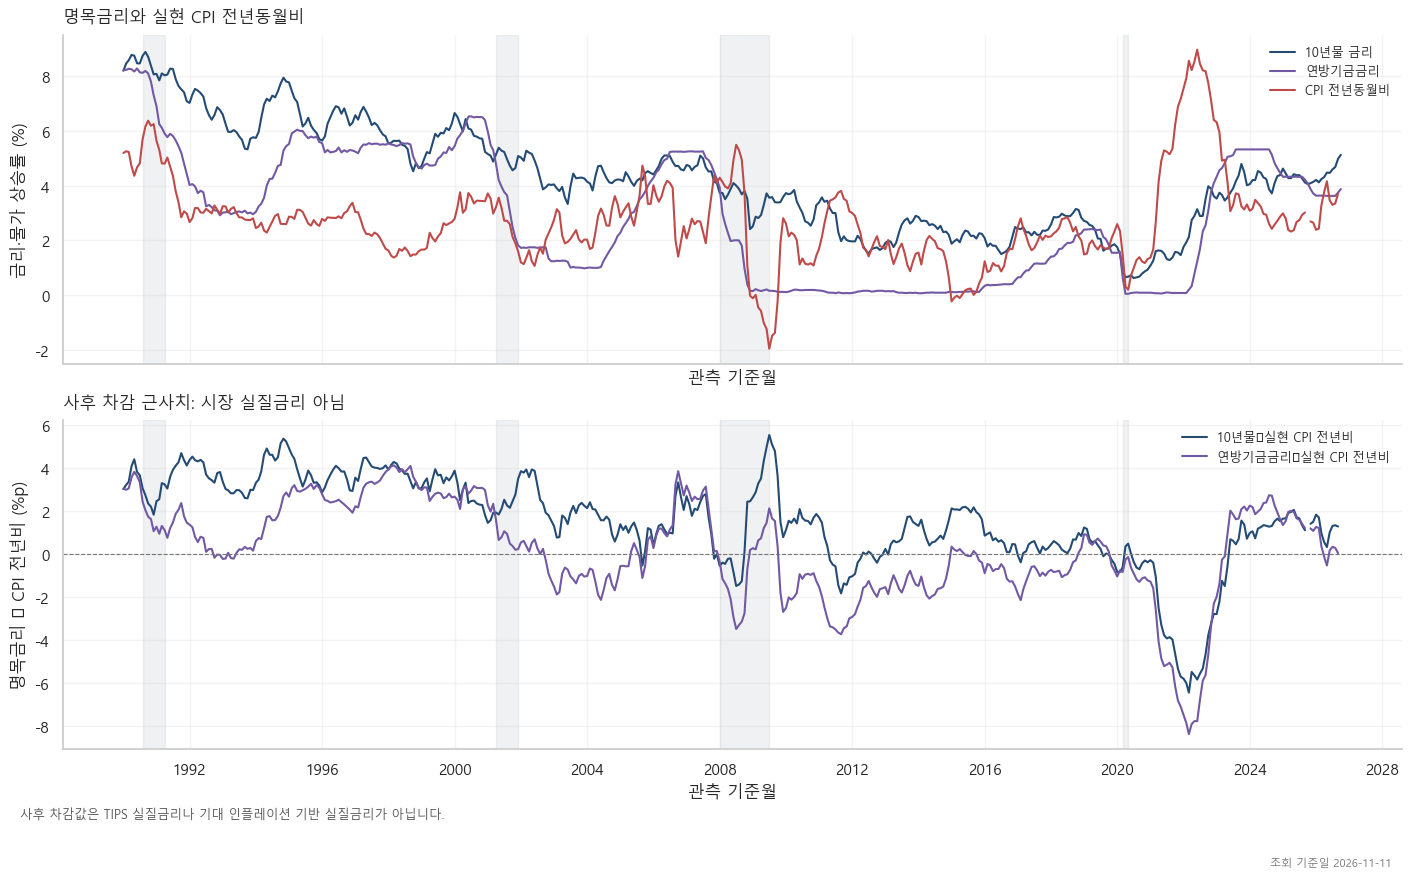

In [45]:
fig,axes = plt.subplots(2,1,figsize=(14,8),sharex=True,constrained_layout=True)
for c in ['US10Y','FEDFUNDS','CPI_YoY']:
    _vline(axes[0],c)
_vstyle(axes[0],'명목금리와 실현 CPI 전년동월비','금리·물가 상승률 (%)')
_vline(axes[1],'ExPost_Real_US10Y',color='#244B74')
_vline(axes[1],'ExPost_Real_FEDFUNDS',color='#7259A4')
_vstyle(axes[1],'사후 차감 근사치: 시장 실질금리 아님','명목금리 − CPI 전년비 (%p)',zero=True)
finish_figure(fig,'macro_expost_real_proxy',caption='사후 차감값은 TIPS 실질금리나 기대 인플레이션 기반 실질금리가 아닙니다.')


### 3-7. 고용: 수준과 증감을 분리

비농업 고용 원자료 `PAYEMS`의 단위는 천 명입니다. 수준은 백만 명으로, 전월 증감과 증감의 최근 3개월 평균은 천 명으로 표시합니다. 증가 속도의 둔화와 고용 수준 자체의 감소는 서로 다르므로 두 패널을 함께 읽습니다.


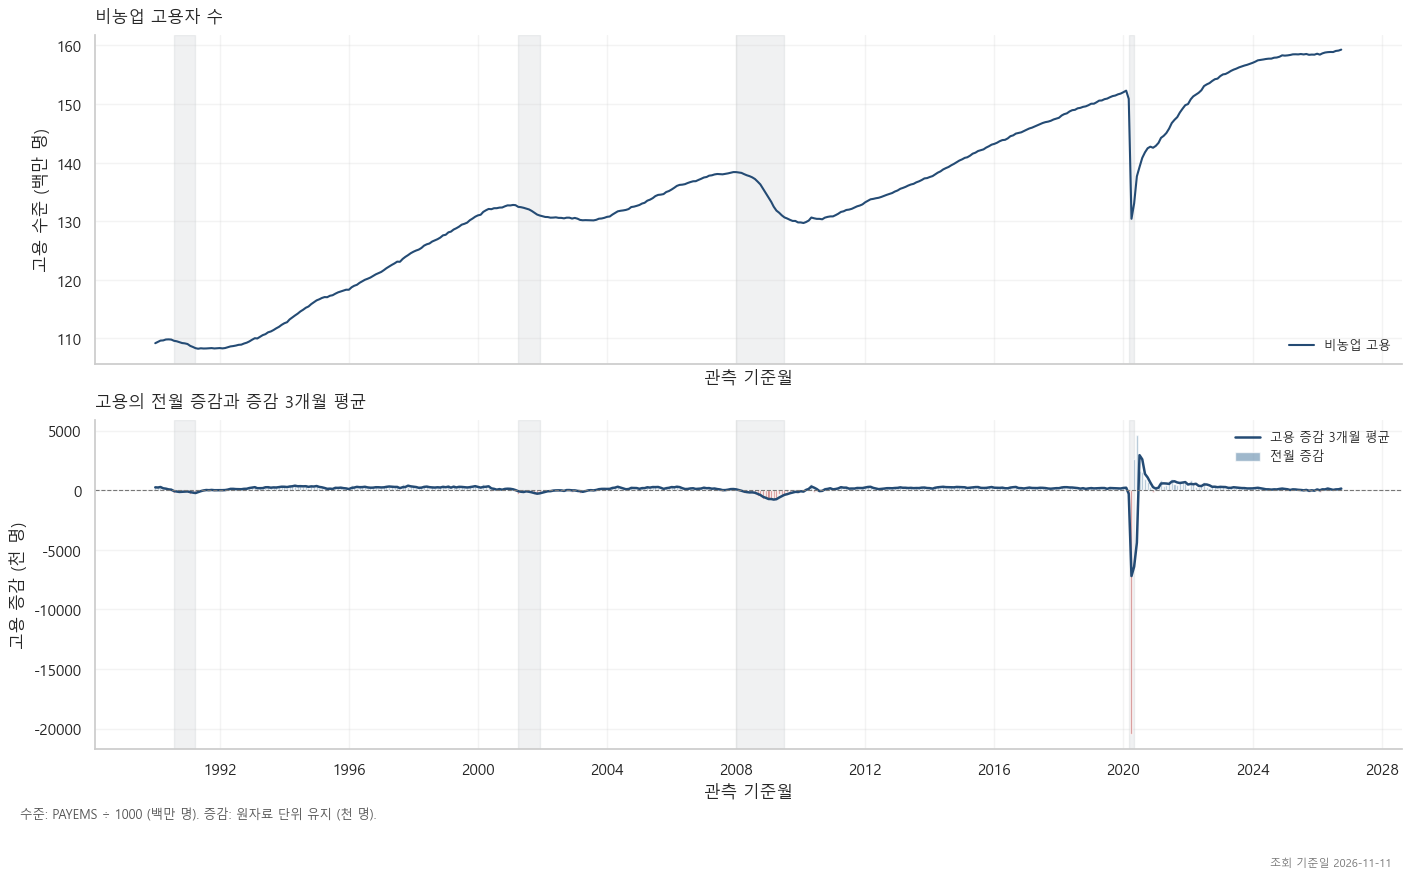

In [46]:
fig,axes = plt.subplots(2,1,figsize=(14,8),sharex=True,constrained_layout=True)
_vline(axes[0],'PAYEMS',scale=.001,color='#244B74')
_vstyle(axes[0],'비농업 고용자 수','고용 수준 (백만 명)')
s = _vs('PAYEMS_Change')
valid = s.notna()
if valid.any():
    axes[1].bar(s.index[valid],s.loc[valid].to_numpy(dtype=float,na_value=np.nan),width=23,
                color=np.where(s.loc[valid].to_numpy()<0,'#BF4A4A','#779AB7'),alpha=.7,label='전월 증감')
else:
    _vempty(axes[1])
_vline(axes[1],'PAYEMS_Change_3M_Mean',color='#244B74',lw=1.8)
_vstyle(axes[1],'고용의 전월 증감과 증감 3개월 평균','고용 증감 (천 명)',zero=True)
finish_figure(fig,'macro_employment_levels_changes',caption='수준: PAYEMS ÷ 1000 (백만 명). 증감: 원자료 단위 유지 (천 명).')


### 3-8. 실업률과 Sahm 근사 지표

Sahm 근사 지표는 실업률의 3개월 평균에서 최근 12개월의 해당 평균 최저값을 뺀 **%p 차이**입니다. 0.50%p 기준선은 지표의 정의상 참조 기준이지, 모든 시점에서 침체를 확정하는 보편 규칙은 아닙니다. 공식 실시간 빈티지 지표와 같다고 간주하지 않습니다.


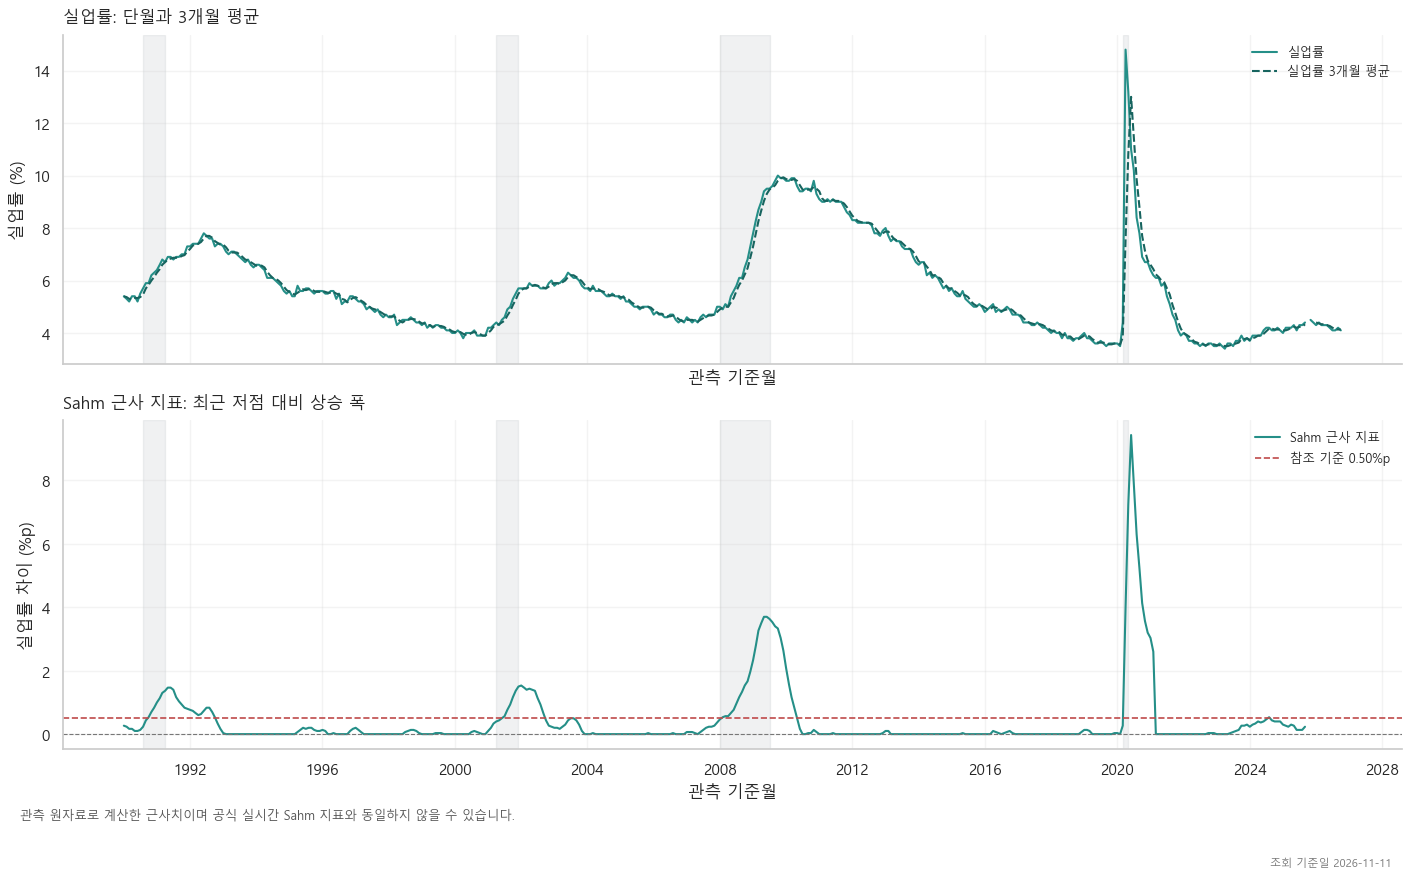

In [47]:
fig,axes = plt.subplots(2,1,figsize=(14,8),sharex=True,constrained_layout=True)
_vline(axes[0],'UNRATE')
_vline(axes[0],'UNRATE_3M',color='#17645F',ls='--')
_vstyle(axes[0],'실업률: 단월과 3개월 평균','실업률 (%)')
plotted = _vline(axes[1],'Sahm_Rule',color='#258F88')
axes[1].axhline(.50,color='#BF4A4A',ls='--',lw=1.2,label='참조 기준 0.50%p')
_vstyle(axes[1],'Sahm 근사 지표: 최근 저점 대비 상승 폭','실업률 차이 (%p)',zero=True)
if not plotted:
    _vempty(axes[1],'계산에 필요한 관측 윈도 부족 또는 결측입니다.')
finish_figure(fig,'macro_unemployment_sahm',caption='관측 원자료로 계산한 근사치이며 공식 실시간 Sahm 지표와 동일하지 않을 수 있습니다.')


### 3-9. 물가–실업률의 시대별 위상

각 점은 CPI 전년비와 실업률이 동시에 관측된 한 달입니다. 색은 달력상의 10년대 구분이며, 부분적으로 관측된 첫·마지막 10년대도 포함합니다. 동일한 실업률에서도 시대에 따라 물가가 달라질 수 있습니다. 회귀선이나 인과적 필립스곡선을 추정하지 않고 분포만 묘사합니다.


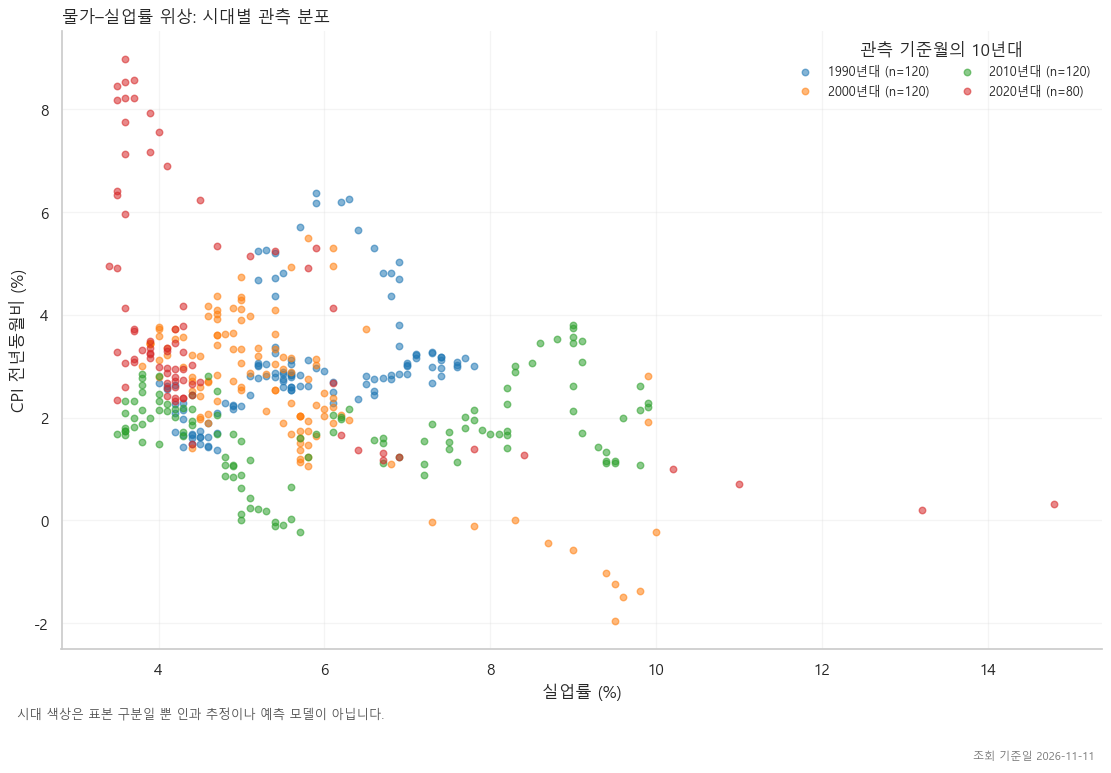

In [48]:
z = _vf(_V,['CPI_YoY','UNRATE']).dropna()
fig,ax = plt.subplots(figsize=(11,7),constrained_layout=True)
if len(z)>=3:
    decades = sorted(set((z.index.year//10)*10))
    palette = plt.get_cmap('tab10')
    for i,d in enumerate(decades):
        g = z.loc[(z.index.year//10)*10==d]
        ax.scatter(g['UNRATE'].to_numpy(dtype=float),g['CPI_YoY'].to_numpy(dtype=float),
                   s=22,alpha=.55,color=palette(i%10),label=f'{d}년대 (n={len(g)})')
    ax.legend(title='관측 기준월의 10년대',fontsize=9,frameon=False,ncol=2)
else:
    _vempty(ax,'동시 관측 월이 3개 미만: 위상 산점도를 생략합니다.')
ax.set_title('물가–실업률 위상: 시대별 관측 분포',loc='left')
ax.set_xlabel('실업률 (%)'); ax.set_ylabel('CPI 전년동월비 (%)'); ax.grid(alpha=.2)
finish_figure(fig,'macro_inflation_unemployment_phase',caption='시대 색상은 표본 구분일 뿐 인과 추정이나 예측 모델이 아닙니다.')


### 3-10. 금리차 역전: 깊이·지속기간·검열

역전은 관측된 `T10Y2Y < 0`의 연속 월 구간으로 정의합니다. 결측 월은 구간을 끊고, 자료 시작·끝 또는 결측과 맞닿은 구간에는 좌·우 검열을 표시합니다. 따라서 지속개월은 **관측된 하한**일 수 있습니다. 음수 금리차 자체와 역전의 깊이(bp, 양수)를 구분합니다.

표의 후속 침체 판정은 **관측된 역전 시작 다음 달부터 24개월**만 추적합니다. 역전 시작이 좌검열되었거나 시작월의 USREC가 미상/이미 침체이면 다음 침체 시점을 식별하지 않습니다. 추적 중 USREC 결측은 식별불가, 자료 끝은 우검열이며, 완전히 관측된 24개월에 시작이 없을 때만 “24개월 내 시작 없음”으로 표시합니다. 이는 이후 영구적인 침체 부재를 뜻하지 않습니다.


,observed_start,observed_end,observed_months,left_censored,right_censored,left_boundary,right_boundary,event_start_known
0,1990-08-01,1991-03-01,8,False,False,관측 전환,관측 전환,True
1,2001-04-01,2001-11-01,8,False,False,관측 전환,관측 전환,True
2,2008-01-01,2009-06-01,18,False,False,관측 전환,관측 전환,True
3,2020-03-01,2020-04-01,2,False,False,관측 전환,관측 전환,True


,observed_start,observed_end,observed_months,left_censored,right_censored,left_boundary,right_boundary,min_spread_bp,max_depth_bp,next_recession_start,months_to_next_recession,followup_observed_months,followup_24m_status
0,1990-03-01,1990-03-01,1,False,False,관측 전환,관측 전환,-3.818182,3.818182,1990-08-01,5.0,5,연속 관측 추적에서 침체 시작 확인
1,1998-06-01,1998-06-01,1,False,False,관측 전환,관측 전환,-2.363636,2.363636,NaT,NaN,24,24개월 관측 내 침체 시작 없음 (이후 미판정)
2,2000-02-01,2000-12-01,11,False,False,관측 전환,관측 전환,-41.315789,41.315789,2001-04-01,14.0,14,연속 관측 추적에서 침체 시작 확인
3,2006-02-01,2006-03-01,2,False,False,관측 전환,관측 전환,-9.947368,9.947368,2008-01-01,23.0,23,연속 관측 추적에서 침체 시작 확인
4,2006-06-01,2007-03-01,10,False,False,관측 전환,관측 전환,-14.523810,14.523810,2008-01-01,19.0,19,연속 관측 추적에서 침체 시작 확인
5,2007-05-01,2007-05-01,1,False,False,관측 전환,관측 전환,-2.000000,2.000000,2008-01-01,8.0,8,연속 관측 추적에서 침체 시작 확인
6,2022-07-01,2024-08-01,26,False,False,관측 전환,관측 전환,-92.900000,92.900000,NaT,NaN,24,24개월 관측 내 침체 시작 없음 (이후 미판정)


c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)
c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)
C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIG

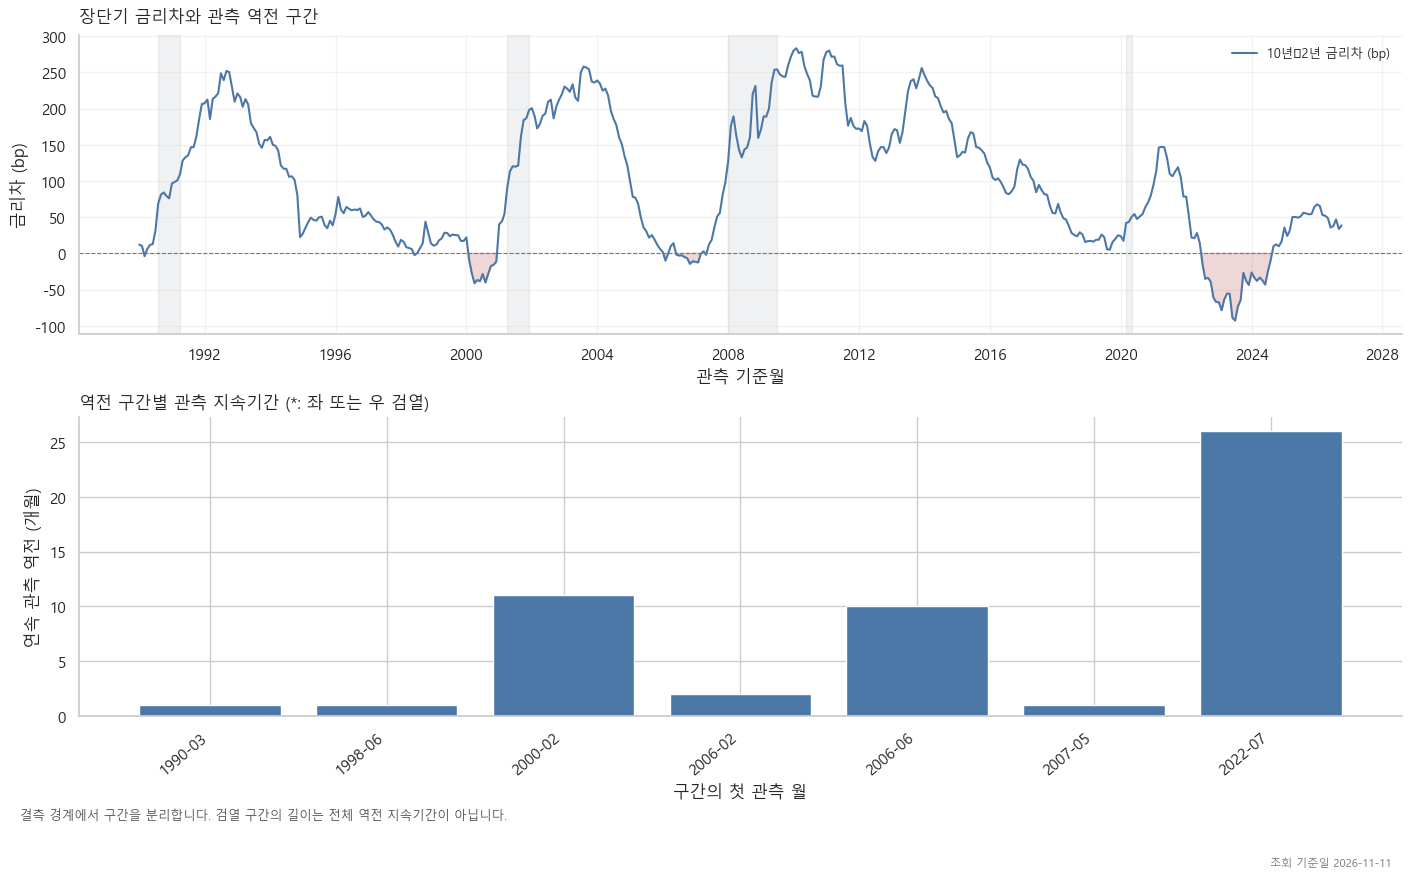

In [49]:
_v_spread = _vs('T10Y2Y')
_v_inv = (_v_spread < 0).astype(float).where(_v_spread.notna())
_v_rec = _vs('USREC').where(_vs('USREC').isin([0,1]))
_v_rec_records = _vruns(_v_rec)
_v_rec_table = pd.DataFrame(_v_rec_records,columns=['observed_start','observed_end','observed_months','left_censored','right_censored','left_boundary','right_boundary'])
_v_rec_table['event_start_known'] = ~_v_rec_table['left_censored'].astype(bool)
_vsave_table('recession_events',_v_rec_table)
_v_known_starts = [r['observed_start'] for r in _v_rec_records if not r['left_censored']]
_v_inv_records = _vruns(_v_inv)
for r in _v_inv_records:
    seg = _v_spread.loc[r['observed_start']:r['observed_end']]
    r['min_spread_bp'] = seg.min()*100
    r['max_depth_bp'] = -seg.min()*100
    r['next_recession_start'] = pd.NaT
    r['months_to_next_recession'] = np.nan
    r['followup_observed_months'] = 0
    start = r['observed_start']
    if r['left_censored']:
        r['followup_24m_status'] = '식별불가: 역전 시작 좌검열'
    elif pd.isna(_v_rec.get(start,np.nan)):
        r['followup_24m_status'] = '식별불가: 시작월 USREC 결측'
    elif _v_rec.loc[start] == 1:
        r['followup_24m_status'] = '시작월 이미 침체: 다음 침체 추적 미실시'
    else:
        r['followup_24m_status'] = '24개월 관측 내 침체 시작 없음 (이후 미판정)'
        for h in range(1,25):
            d = start + pd.DateOffset(months=h)
            if d not in _v_rec.index:
                r['followup_24m_status'] = '우검열: 24개월 추적 전 자료 종료'
                break
            if pd.isna(_v_rec.loc[d]):
                r['followup_24m_status'] = '식별불가: 추적 중 USREC 결측'
                break
            r['followup_observed_months'] += 1
            if d in _v_known_starts:
                r['next_recession_start'] = d
                r['months_to_next_recession'] = h
                r['followup_24m_status'] = '연속 관측 추적에서 침체 시작 확인'
                break
_v_inv_cols = ['observed_start','observed_end','observed_months','left_censored','right_censored','left_boundary','right_boundary','min_spread_bp','max_depth_bp','next_recession_start','months_to_next_recession','followup_observed_months','followup_24m_status']
_v_inv_table = pd.DataFrame(_v_inv_records,columns=_v_inv_cols)
_vsave_table('inversion_episodes',_v_inv_table)
fig,axes = plt.subplots(2,1,figsize=(14,8),constrained_layout=True)
_vline(axes[0],'T10Y2Y',scale=100,label='10년−2년 금리차 (bp)')
y = _v_spread.to_numpy(dtype=float,na_value=np.nan)*100
axes[0].fill_between(_V.index,y,0,where=np.isfinite(y)&(y<0),color='#BF4A4A',alpha=.22)
_vstyle(axes[0],'장단기 금리차와 관측 역전 구간','금리차 (bp)',zero=True)
if not _v_spread.notna().any():
    _vempty(axes[0],'금리차 유효 관측이 없습니다. 역전 여부를 판정하지 않습니다.')
if len(_v_inv_table):
    x = np.arange(len(_v_inv_table))
    axes[1].bar(x,_v_inv_table['observed_months'].to_numpy(dtype=float),color='#4C78A8')
    labs = [r['observed_start'].strftime('%Y-%m')+(' *' if r['left_censored'] or r['right_censored'] else '') for r in _v_inv_records]
    step = max(1,int(np.ceil(len(x)/18)))
    axes[1].set_xticks(x[::step]); axes[1].set_xticklabels(labs[::step],rotation=40,ha='right')
else:
    _vempty(axes[1],'관측된 역전 구간이 없습니다. 이는 결측 기간의 역전 부재를 뜻하지 않습니다.')
axes[1].set_title('역전 구간별 관측 지속기간 (*: 좌 또는 우 검열)',loc='left')
axes[1].set_xlabel('구간의 첫 관측 월'); axes[1].set_ylabel('연속 관측 역전 (개월)')
finish_figure(fig,'macro_inversion_depth_duration',caption='결측 경계에서 구간을 분리합니다. 검열 구간의 길이는 전체 역전 지속기간이 아닙니다.')


### 3-11. 쌍별 Pearson·Spearman 상관

Pearson은 선형 동행을, Spearman은 각 **쌍별 공통 관측 표본 안에서 다시 계산한 순위**의 동행을 요약합니다. 일괄 완전행 삭제 대신 각 쌍의 유효 월을 사용하며, `MIN_CORR_PAIRS` 미만 또는 상수열이 포함된 셀은 마스킹합니다. 자기상관이 강한 거시 수준의 상관은 공통 추세·시대 구성을 반영할 수 있습니다.


,US10Y,CPI_YoY,FEDFUNDS,UNRATE,T10Y2Y
US10Y,1.000000,0.285617,0.827071,-0.115774,-0.157656
CPI_YoY,0.285617,1.000000,0.354256,-0.330856,-0.330539
FEDFUNDS,0.827071,0.354256,1.000000,-0.447547,-0.632697
UNRATE,-0.115774,-0.330856,-0.447547,1.000000,0.714466
T10Y2Y,-0.157656,-0.330539,-0.632697,0.714466,1.000000


,US10Y,CPI_YoY,FEDFUNDS,UNRATE,T10Y2Y
US10Y,1.000000,0.400826,0.831871,-0.025127,-0.199157
CPI_YoY,0.400826,1.000000,0.428763,-0.252542,-0.298094
FEDFUNDS,0.831871,0.428763,1.000000,-0.424486,-0.635760
UNRATE,-0.025127,-0.252542,-0.424486,1.000000,0.804363
T10Y2Y,-0.199157,-0.298094,-0.635760,0.804363,1.000000


c:\Users\pc377\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
c:\Users\pc377\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


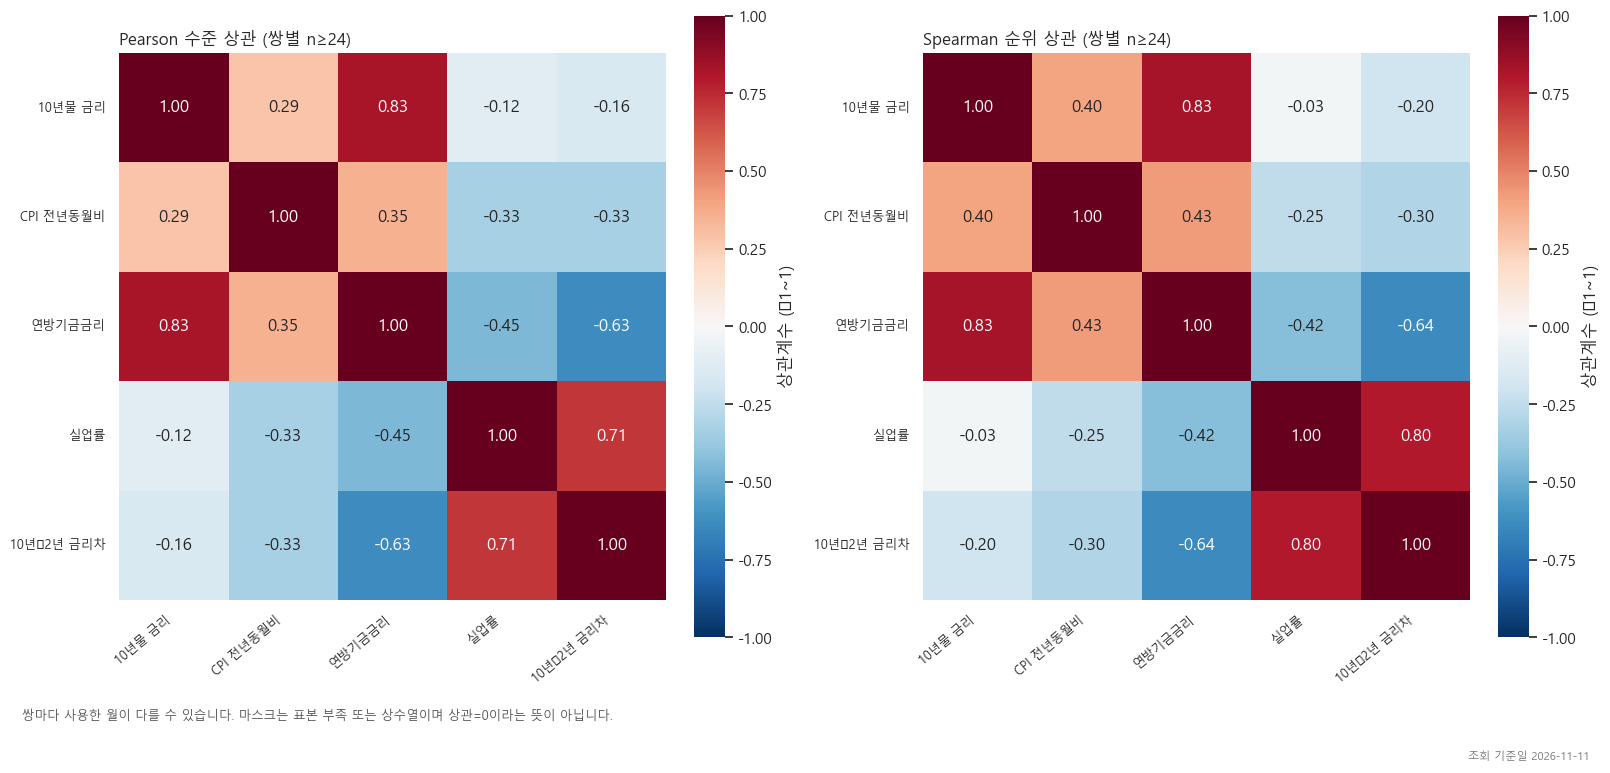

In [50]:
_v_pearson,_v_counts = _vcorr(_V,_v_corr_cols,'pearson')
_v_spearman,_ = _vcorr(_V,_v_corr_cols,'spearman')
_vsave_table('correlations_pairwise',_v_pearson.round(6))
_vsave_table('correlations_spearman',_v_spearman.round(6))
fig,axes = plt.subplots(1,2,figsize=(16,7),constrained_layout=True)
_vheat(axes[0],_v_pearson,f'Pearson 수준 상관 (쌍별 n≥{MIN_CORR_PAIRS})')
_vheat(axes[1],_v_spearman,f'Spearman 순위 상관 (쌍별 n≥{MIN_CORR_PAIRS})')
finish_figure(fig,'macro_correlations_pairwise',caption='쌍마다 사용한 월이 다를 수 있습니다. 마스크는 표본 부족 또는 상수열이며 상관=0이라는 뜻이 아닙니다.')


### 3-12. 상관계수의 실제 표본수

상관행렬과 동일한 쌍에 대한 **동시 유효 관측 월 수**를 표시합니다. 최소 표본수 미만 셀은 그림에서 마스킹하되 CSV에는 실제 개수를 보존합니다. 대각선은 각 변수 단독 관측수이므로 비대각선보다 클 수 있습니다. 관측수가 충분해도 상수열의 상관계수는 정의되지 않습니다.


,US10Y,CPI_YoY,FEDFUNDS,UNRATE,T10Y2Y
US10Y,442,440,442,441,442
CPI_YoY,440,440,440,440,440
FEDFUNDS,442,440,442,441,442
UNRATE,441,440,441,441,441
T10Y2Y,442,440,442,441,442


C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


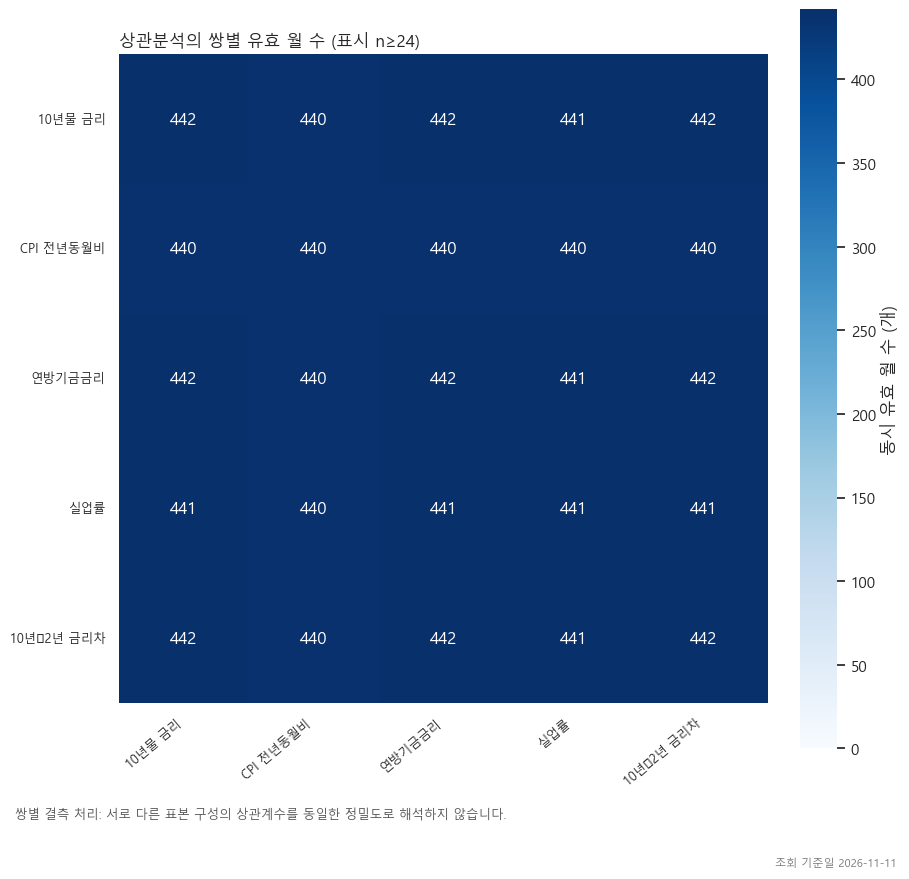

In [51]:
_vsave_table('sample_counts',_v_counts)
fig,ax = plt.subplots(figsize=(9,8),constrained_layout=True)
_vheat(ax,_v_counts,f'상관분석의 쌍별 유효 월 수 (표시 n≥{MIN_CORR_PAIRS})',kind='count',min_n=MIN_CORR_PAIRS)
finish_figure(fig,'macro_correlation_sample_counts',caption='쌍별 결측 처리: 서로 다른 표본 구성의 상관계수를 동일한 정밀도로 해석하지 않습니다.')


### 3-13. 수준 상관과 1개월 차분 상관 비교

같은 변수의 수준 상관과 1개월 차분 상관을 비교해 공통 장기 추세와 단기 동행을 구분합니다. `CPI_YoY`의 차분은 CPI 전월비가 아니라 **전년동월비 상승률의 전월 변화(%p)**입니다. 차분은 결측을 메우지 않으며, 인접 두 달이 관측되어야 계산됩니다. 두 행렬의 표본수가 다를 수 있으므로 표도 별도 저장합니다.


,US10Y,CPI_YoY,FEDFUNDS,UNRATE,T10Y2Y
US10Y,1.000000,0.189270,0.177645,-0.072626,0.276287
CPI_YoY,0.189270,1.000000,0.143108,-0.184319,0.079930
FEDFUNDS,0.177645,0.143108,1.000000,-0.214795,-0.422357
UNRATE,-0.072626,-0.184319,-0.214795,1.000000,0.032012
T10Y2Y,0.276287,0.079930,-0.422357,0.032012,1.000000


c:\Users\pc377\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
c:\Users\pc377\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


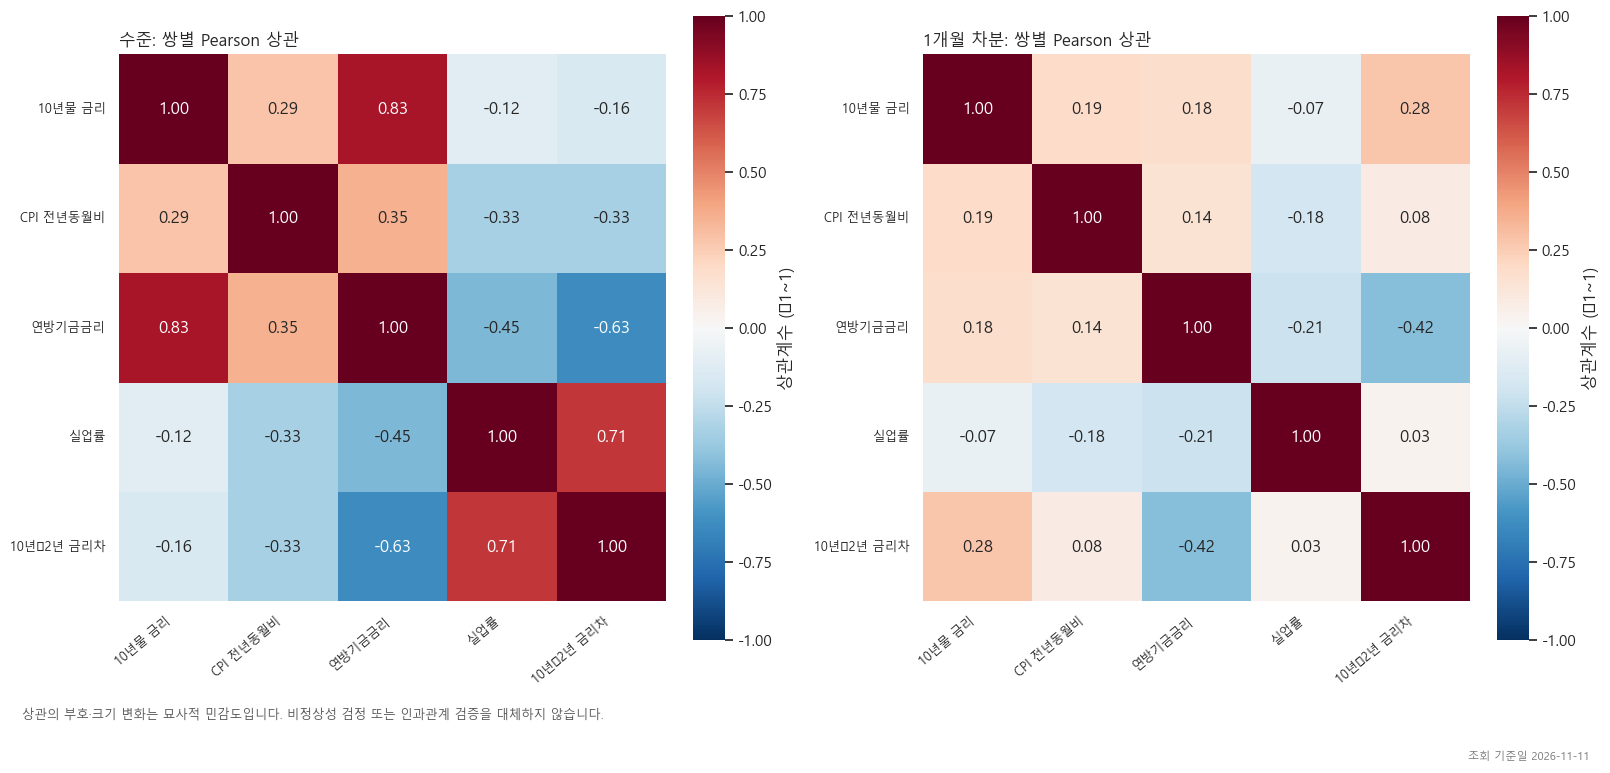

In [52]:
_v_diff = _vf(_V,_v_corr_cols).diff(1)
_v_dc,_v_dn = _vcorr(_v_diff,_v_corr_cols)
_vsave_table('correlations_firstdiff',_v_dc.round(6))
_vsave_table('sample_counts_firstdiff',_v_dn,show=False)
fig,axes = plt.subplots(1,2,figsize=(16,7),constrained_layout=True)
_vheat(axes[0],_v_pearson,'수준: 쌍별 Pearson 상관')
_vheat(axes[1],_v_dc,'1개월 차분: 쌍별 Pearson 상관')
finish_figure(fig,'macro_level_vs_firstdiff_corr',caption='상관의 부호·크기 변화는 묘사적 민감도입니다. 비정상성 검정 또는 인과관계 검증을 대체하지 않습니다.')


### 3-14. 이동 상관: 12개월과 36개월

10년물 금리와 CPI 전년비의 Pearson 상관을 매달 다시 계산합니다. **12개월은 단기 윈도이므로 잡음이 크며**, 36개월도 구간 선택에 민감합니다. 전체 상관의 최소 표본수 기준과는 별도로 여기서는 해당 윈도 전체의 유효 쌍(12/36개)을 요구합니다. 관측 결측이나 상수 윈도는 선을 끊습니다.


c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)
c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)


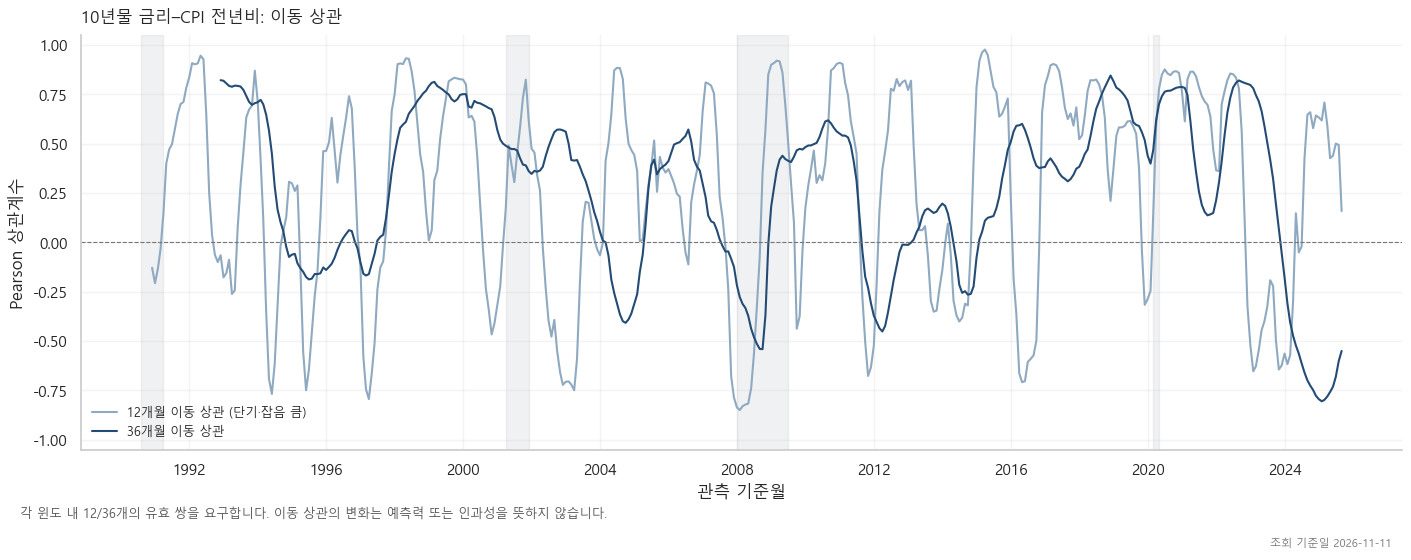

In [53]:
x,y = _vs('US10Y'),_vs('CPI_YoY')
_v_roll = pd.DataFrame(index=_V.index)
for w in [12,36]:
    paired = (x.notna()&y.notna()).astype(int).rolling(w,min_periods=w).sum()
    r = x.rolling(w,min_periods=w).corr(y)
    r = r.where((paired==w)&(x.rolling(w,min_periods=w).std()>0)&(y.rolling(w,min_periods=w).std()>0))
    _v_roll[f'corr_{w}m'] = r.replace([np.inf,-np.inf],np.nan)
    _v_roll[f'n_{w}m'] = paired
fig,ax = plt.subplots(figsize=(14,5),constrained_layout=True)
plotted = False
for w,color in [(12,'#8EA9C0'),(36,'#244B74')]:
    if _v_roll[f'corr_{w}m'].notna().any():
        ax.plot(_v_roll.index,_v_roll[f'corr_{w}m'].to_numpy(dtype=float,na_value=np.nan),
                color=color,label=f'{w}개월 이동 상관'+(' (단기·잡음 큼)' if w==12 else ''),lw=1.5)
        plotted = True
_vstyle(ax,'10년물 금리–CPI 전년비: 이동 상관','Pearson 상관계수',zero=True)
ax.set_ylim(-1.05,1.05)
if not plotted:
    _vempty(ax,'완전 관측 윈도 또는 변동이 부족하여 이동 상관을 계산하지 않습니다.')
_vsave_table('rolling_correlations',_v_roll,show=False)
finish_figure(fig,'macro_rolling_corr_12_36',caption='각 윈도 내 12/36개의 유효 쌍을 요구합니다. 이동 상관의 변화는 예측력 또는 인과성을 뜻하지 않습니다.')


### 3-15. 시차 상관: 부호 정의를 먼저 읽기

시차 상관을 **corr(US10Y[t], CPI_YoY[t−lag])**로 정의합니다. 양의 lag는 과거 물가와 현재 금리를 비교하므로 **물가가 금리보다 앞서는 정렬**이고, 음의 lag는 미래 물가를 사용한 사후 비교입니다. 각 시차마다 유효 표본수가 다릅니다. 최소 표본수 미달·상수열이면 계수를 표시하지 않으며, 최대 상관 시차를 예측 최적 시차로 선택하지 않습니다.


,pearson_corr,pair_count,first_pair_month,last_pair_month
lag_months,,,,
-12,0.027206,428,1990-01-01,2025-09-01
-11,0.053319,429,1990-01-01,2025-10-01
-10,0.082464,430,1990-01-01,2025-11-01
-9,0.110270,431,1990-01-01,2025-12-01
-8,0.134612,432,1990-01-01,2026-01-01
-7,0.156455,433,1990-01-01,2026-02-01
-6,0.175901,434,1990-01-01,2026-03-01
-5,0.194763,435,1990-01-01,2026-04-01
-4,0.211633,436,1990-01-01,2026-05-01


C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


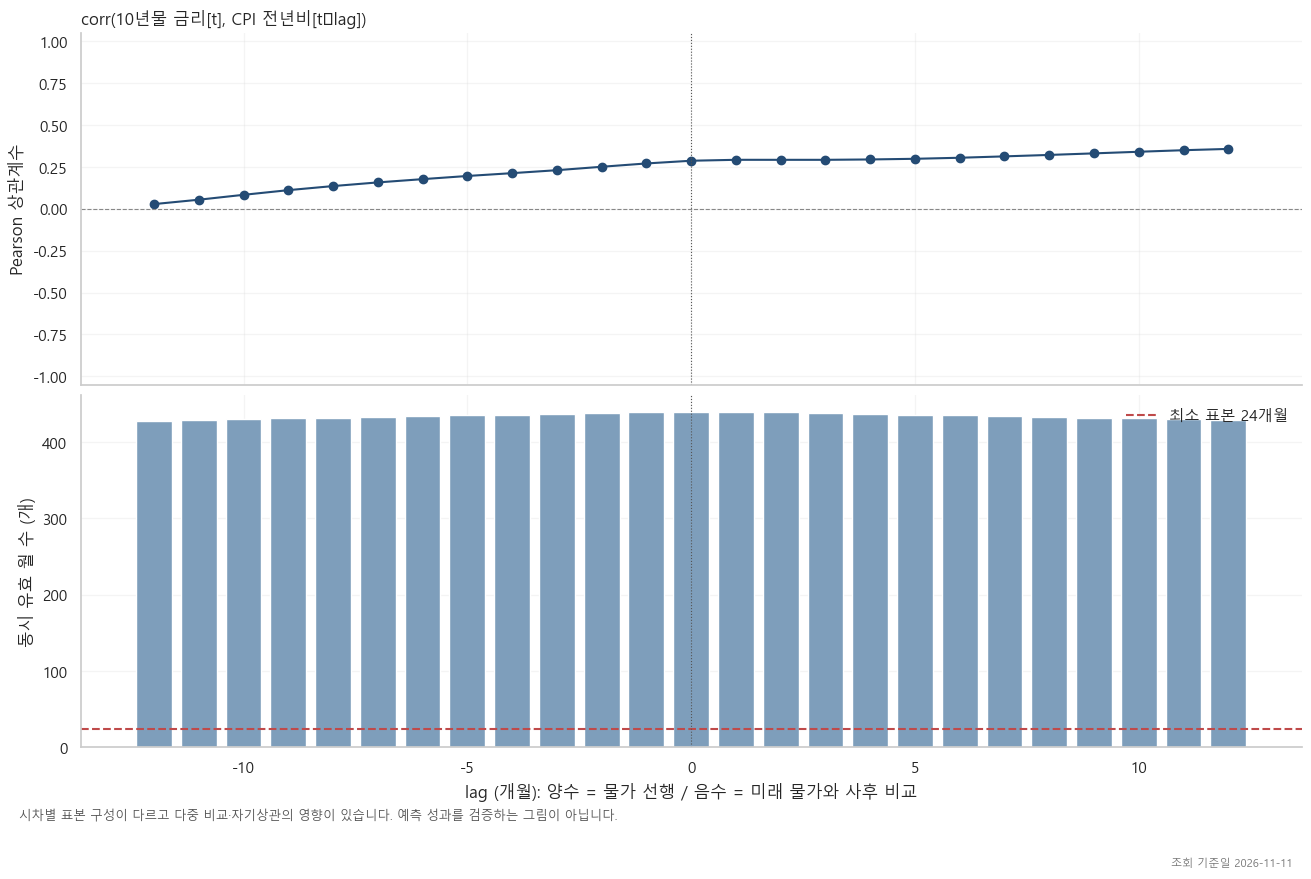

In [54]:
_v_lag_rows = []
for lag in LAGS:
    z = pd.DataFrame({'금리_t':_vs('US10Y'),'물가_t_minus_lag':_vs('CPI_YoY').shift(lag)}).dropna()
    n = len(z)
    valid = n>=MIN_CORR_PAIRS and z['금리_t'].nunique()>1 and z['물가_t_minus_lag'].nunique()>1
    r = z['금리_t'].corr(z['물가_t_minus_lag']) if valid else np.nan
    _v_lag_rows.append({'lag_months':lag,'pearson_corr':r,'pair_count':n,
                        'first_pair_month':z.index.min() if n else pd.NaT,'last_pair_month':z.index.max() if n else pd.NaT})
_v_lag = pd.DataFrame(_v_lag_rows).set_index('lag_months')
_vsave_table('lag_correlation',_v_lag)
fig,axes = plt.subplots(2,1,figsize=(13,8),sharex=True,constrained_layout=True)
if _v_lag['pearson_corr'].notna().any():
    axes[0].plot(_v_lag.index,_v_lag['pearson_corr'].to_numpy(dtype=float,na_value=np.nan),marker='o',color='#244B74')
else:
    _vempty(axes[0],'시차별 최소 표본수 또는 변동성 조건이 충족되지 않습니다.')
axes[0].set_ylim(-1.05,1.05); axes[0].axhline(0,color='#888888',ls='--',lw=.8)
axes[0].set_title('corr(10년물 금리[t], CPI 전년비[t−lag])',loc='left'); axes[0].set_ylabel('Pearson 상관계수')
axes[1].bar(_v_lag.index,_v_lag['pair_count'].to_numpy(dtype=float),color='#7E9EBB')
axes[1].axhline(MIN_CORR_PAIRS,color='#BF4A4A',ls='--',label=f'최소 표본 {MIN_CORR_PAIRS}개월')
axes[1].legend(frameon=False); axes[1].set_ylabel('동시 유효 월 수 (개)')
axes[1].set_xlabel('lag (개월): 양수 = 물가 선행 / 음수 = 미래 물가와 사후 비교')
for ax in axes:
    ax.axvline(0,color='#555555',lw=.8,ls=':'); ax.grid(alpha=.2)
finish_figure(fig,'macro_lag_correlation',caption='시차별 표본 구성이 다르고 다중 비교·자기상관의 영향이 있습니다. 예측 성과를 검증하는 그림이 아닙니다.')


### 3-16. 국채 금리–물가: 확장기와 침체기 분리

USREC=0인 달과 USREC=1인 달의 산점도를 **동일한 % 단위·축 범위**로 나란히 비교합니다. USREC 미상인 달은 분류하지 않습니다. 각 국면에서 유효 관측이 3개월 미만이면 산점도를 생략합니다. NBER 침체 구분 자체도 사후 판정이므로 실제 거래 시점의 가용 정보로 해석하지 않습니다.


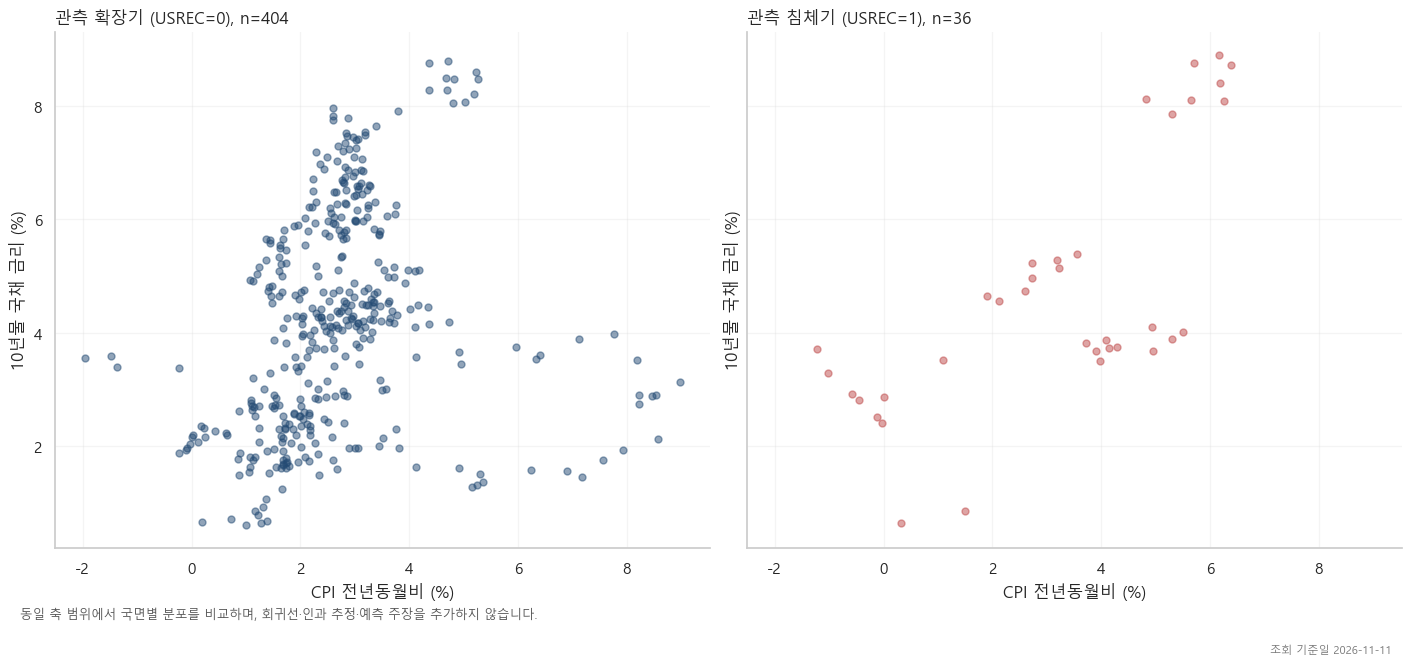

In [55]:
z = _vf(_V,['US10Y','CPI_YoY','USREC']).dropna()
z = z.loc[z['USREC'].isin([0,1])]
fig,axes = plt.subplots(1,2,figsize=(14,6),sharex=True,sharey=True,constrained_layout=True)
for ax,state,title,color in zip(axes,[0,1],['관측 확장기 (USREC=0)','관측 침체기 (USREC=1)'],['#244B74','#BF4A4A']):
    g = z.loc[z['USREC']==state]
    if len(g)>=3:
        ax.scatter(g['CPI_YoY'].to_numpy(dtype=float),g['US10Y'].to_numpy(dtype=float),s=25,alpha=.5,color=color)
    else:
        _vempty(ax,f'유효 관측 {len(g)}개월: 최소 3개월 미달')
    ax.set_title(f'{title}, n={len(g)}',loc='left')
    ax.set_xlabel('CPI 전년동월비 (%)'); ax.set_ylabel('10년물 국채 금리 (%)'); ax.grid(alpha=.2)
_v_regime_n = pd.DataFrame({'regime':['expansion','recession'],'pair_count':[int((z['USREC']==0).sum()),int((z['USREC']==1).sum())]})
_vsave_table('yield_inflation_regime_counts',_v_regime_n,show=False)
finish_figure(fig,'macro_yield_inflation_regimes',caption='동일 축 범위에서 국면별 분포를 비교하며, 회귀선·인과 추정·예측 주장을 추가하지 않습니다.')


### 3-17. 변화 지표의 분포와 극단 관측

수준 변수를 한 축에서 혼합하지 않고 네 변화 지표를 각각 독립된 단위 축에 배치합니다. 금리 전월 변화는 bp, 물가 전월비는 %, 실업률 변화는 %p, 고용 증감은 천 명입니다. 히스토그램은 월 수이며, 별도 상자그림의 극단점은 제거 대상이라고 자동 판단하지 않습니다. 결측값은 분포에서 제외합니다.


C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\2985386062.py:12: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1,j].boxplot(s.to_numpy(dtype=float),vert=False,patch_artist=True,
C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\2985386062.py:12: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1,j].boxplot(s.to_numpy(dtype=float),vert=False,patch_artist=True,
C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\2985386062.py:12: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1,j].boxplot(s.to_numpy(dtype=float),vert=False,patch_artist=True,
C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\2985386062.py:12: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'hori

,unit,n,mean,median,std,p05,p95
series,,,,,,,
US10Y_Change,bp,442,-0.612002,-1.630326,21.757762,-32.874741,36.556656
CPI_MoM,%,440,0.223419,0.217111,0.273186,-0.133762,0.624674
UNRATE_Change,%p,440,-0.003182,0.000000,0.547505,-0.300000,0.200000
PAYEMS_Change,천 명,442,114.156109,163.000000,1041.187363,-217.500000,455.850000


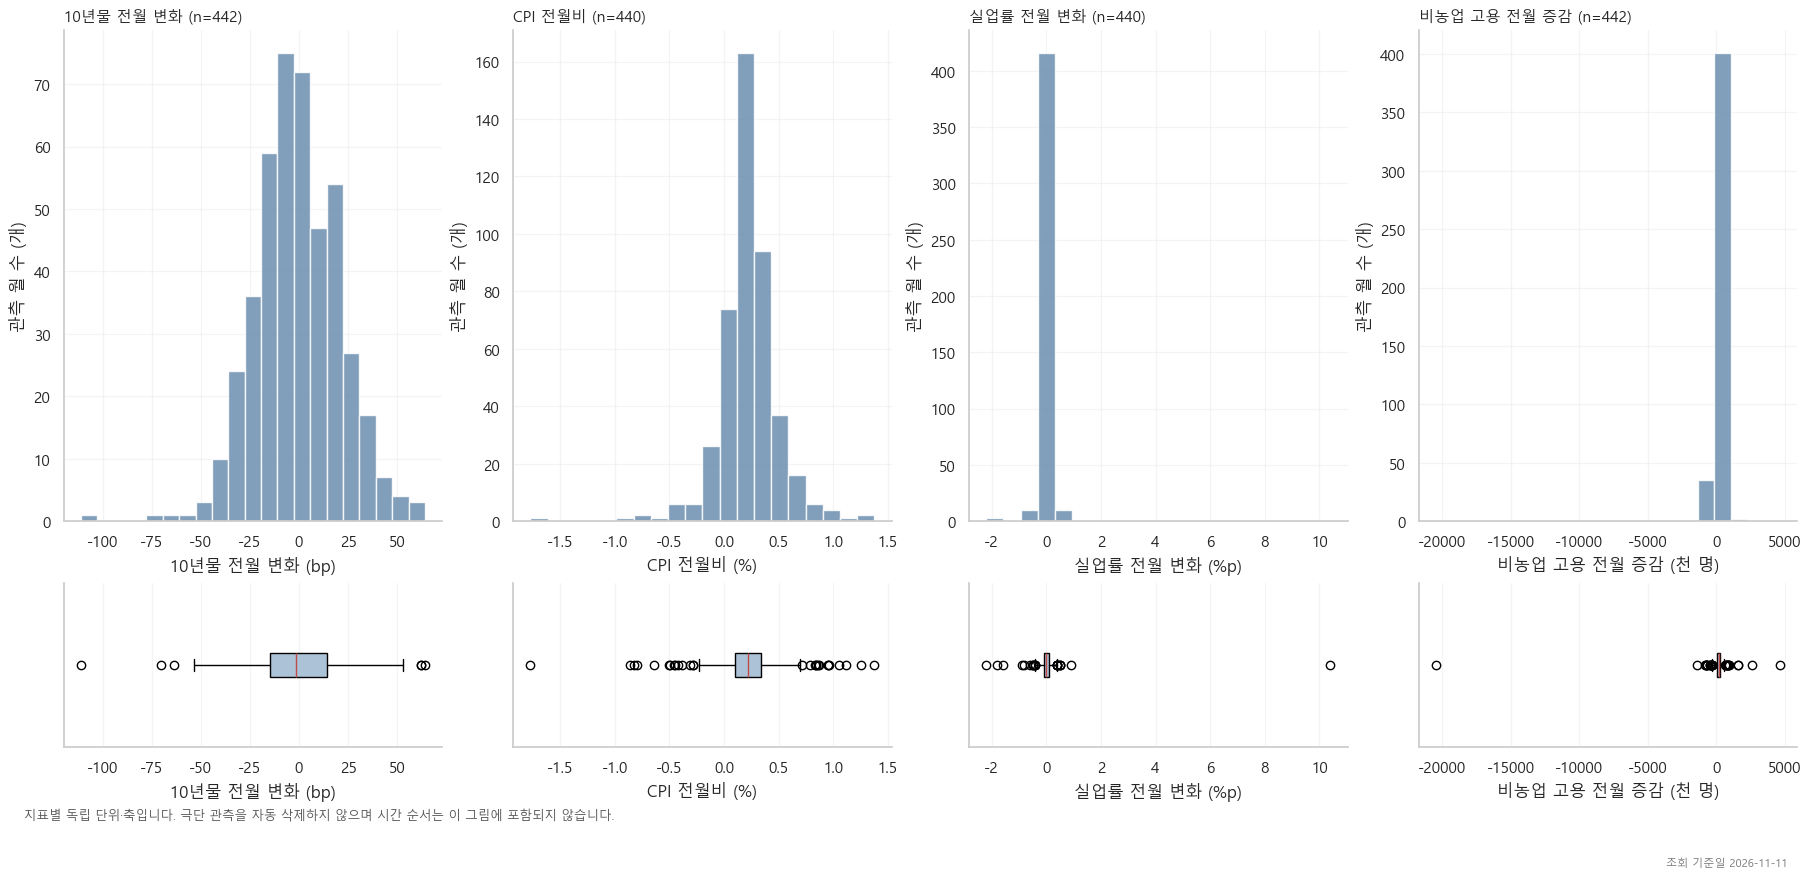

In [56]:
_v_dist_specs = [('US10Y_Change',100,'10년물 전월 변화','bp'),('CPI_MoM',1,'CPI 전월비','%'),
                 ('UNRATE_Change',1,'실업률 전월 변화','%p'),('PAYEMS_Change',1,'비농업 고용 전월 증감','천 명')]
fig,axes = plt.subplots(2,4,figsize=(18,8),constrained_layout=True,gridspec_kw={'height_ratios':[3,1]})
_v_dist_summary = []
for j,(c,scale,label,unit) in enumerate(_v_dist_specs):
    s = (_vs(c)*scale).dropna()
    _v_dist_summary.append({'series':c,'unit':unit,'n':len(s),'mean':s.mean(),'median':s.median(),
                            'std':s.std(),'p05':s.quantile(.05),'p95':s.quantile(.95)})
    if len(s)>=3:
        bins = min(40,max(5,int(np.sqrt(len(s)))))
        axes[0,j].hist(s.to_numpy(dtype=float),bins=bins,color='#6B8EAF',alpha=.85,edgecolor='white')
        axes[1,j].boxplot(s.to_numpy(dtype=float),vert=False,patch_artist=True,
                          boxprops={'facecolor':'#ACC3D7'},medianprops={'color':'#BF4A4A'})
        axes[1,j].set_yticks([])
    else:
        for ax in axes[:,j]:
            _vempty(ax,f'유효 관측 n={len(s)}: 최소 3개 미달')
    axes[0,j].set_title(f'{label} (n={len(s)})',loc='left',fontsize=11)
    axes[0,j].set_ylabel('관측 월 수 (개)')
    for ax in axes[:,j]:
        ax.set_xlabel(f'{label} ({unit})'); ax.grid(alpha=.2)
_vsave_table('difference_distribution_summary',pd.DataFrame(_v_dist_summary).set_index('series'))
finish_figure(fig,'macro_difference_distributions',caption='지표별 독립 단위·축입니다. 극단 관측을 자동 삭제하지 않으며 시간 순서는 이 그림에 포함되지 않습니다.')


### 3-18. 10년대별 요약: 평균·분산·표본수

금리 수준·CPI 전년비·실업률의 10년대별 평균과 월별 표준편차를 요약합니다. 오차 막대는 **±1 표준편차**, 신뢰구간이 아닙니다. 각 점 옆의 n은 해당 지표의 유효 월 수이며, 완결된 10년대와 부분 기간을 같게 비교하지 않도록 CSV에 첫·마지막 관측월을 기록합니다. 관측 3개월 미만이면 점을 생략합니다.


,series,decade,n,mean,std,median,first_observation,last_observation
0,US10Y,1990,120,6.664410,1.052806,6.522500,1990-01-01,1999-12-01
1,US10Y,2000,120,4.457748,0.802034,4.430619,2000-01-01,2009-12-01
2,US10Y,2010,120,2.405806,0.550488,2.325051,2010-01-01,2019-12-01
3,US10Y,2020,82,3.149089,1.423002,3.809502,2020-01-01,2026-10-01
4,CPI_YoY,1990,120,3.007507,1.125600,2.824305,1990-01-01,1999-12-01
5,CPI_YoY,2000,120,2.573315,1.422802,2.795577,2000-01-01,2009-12-01
6,CPI_YoY,2010,120,1.771272,0.858073,1.737792,2010-01-01,2019-12-01
7,CPI_YoY,2020,80,3.898358,2.228140,3.247772,2020-01-01,2026-09-01
8,UNRATE,1990,120,5.762500,1.049294,5.600000,1990-01-01,1999-12-01
9,UNRATE,2000,120,5.541667,1.447199,5.300000,2000-01-01,2009-12-01


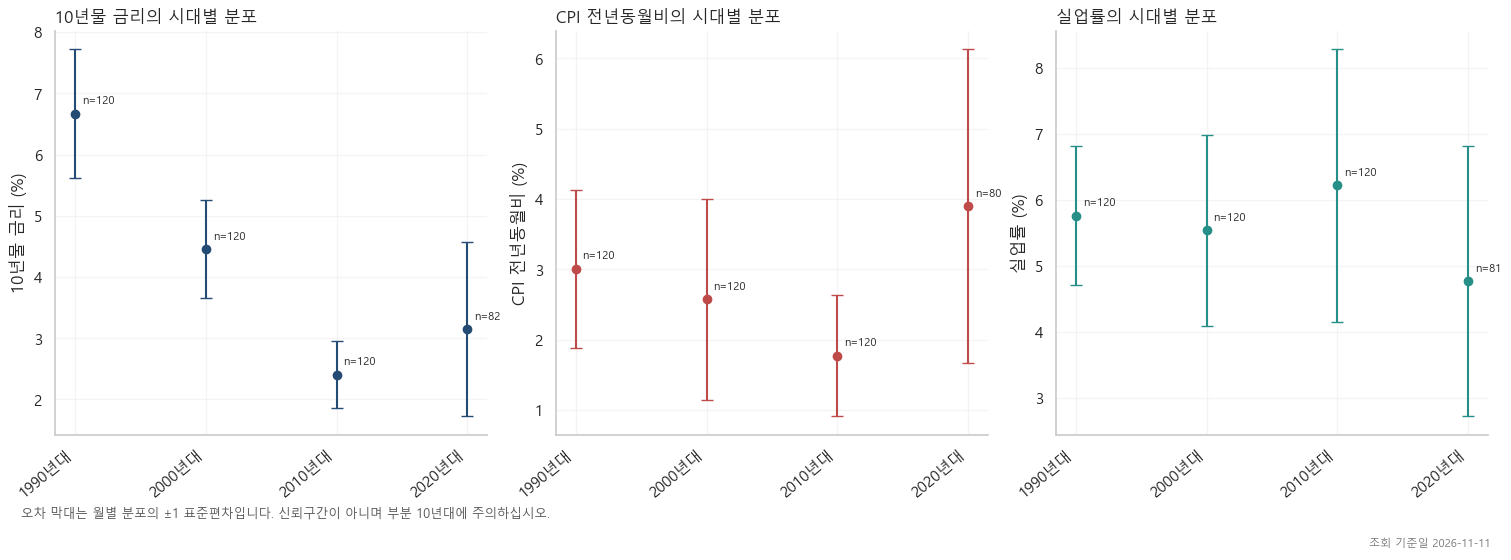

In [57]:
_v_decade_rows = []
for c in ['US10Y','CPI_YoY','UNRATE']:
    s = _vs(c)
    for d,g in s.groupby((s.index.year//10)*10):
        g = g.dropna()
        _v_decade_rows.append({'series':c,'decade':int(d),'n':len(g),'mean':g.mean(),'std':g.std(),
                               'median':g.median(),'first_observation':g.index.min() if len(g) else pd.NaT,
                               'last_observation':g.index.max() if len(g) else pd.NaT})
_v_decade = pd.DataFrame(_v_decade_rows,columns=['series','decade','n','mean','std','median','first_observation','last_observation'])
_vsave_table('decade_summary',_v_decade)
fig,axes = plt.subplots(1,3,figsize=(15,5),constrained_layout=True)
for ax,c in zip(axes,['US10Y','CPI_YoY','UNRATE']):
    g = _v_decade.loc[(_v_decade['series']==c)&(_v_decade['n']>=3)]
    if len(g):
        xpos = np.arange(len(g))
        ax.errorbar(xpos,g['mean'].to_numpy(dtype=float),yerr=g['std'].to_numpy(dtype=float),
                    fmt='o',capsize=4,color=_v_colors.get(c,'#244B74'))
        ax.set_xticks(xpos); ax.set_xticklabels([f'{int(d)}년대' for d in g['decade']],rotation=40,ha='right')
        for x,m,n in zip(xpos,g['mean'],g['n']):
            ax.annotate(f'n={int(n)}',(x,m),xytext=(5,7),textcoords='offset points',fontsize=8)
    else:
        _vempty(ax,'10년대별 유효 관측이 3개월 미만입니다.')
    ax.set_title(_v_labels[c]+'의 시대별 분포',loc='left'); ax.set_ylabel(_v_labels[c]+' (%)'); ax.grid(alpha=.2)
finish_figure(fig,'macro_decade_summaries',caption='오차 막대는 월별 분포의 ±1 표준편차입니다. 신뢰구간이 아니며 부분 10년대에 주의하십시오.')


### 3-19. NBER 침체 시작 사건 연구

NBER 지표에서 **직전 달 0 → 현재 달 1**이 실제로 관측된 시작만 사용합니다. 데이터 시작이나 결측 뒤에 이미 1인 구간은 시작 시점을 알 수 없어 사건 정렬에서 제외합니다. 각 사건의 침체 시작월을 t=0으로 두고 전 `EVENT_WINDOW_BEFORE`개월·후 `EVENT_WINDOW_AFTER`개월을 조회합니다.

각 지표는 사건 직전 **t=−1의 실제 관측값**을 기준으로 차감합니다. 기준값이 없으면 그 사건·지표를 전부 제외하고 보간·전방 채우기를 하지 않습니다. 옅은 선은 사건별 변화, 굵은 선은 같은 상대 월에서 관측 가능한 사건들의 **동일 가중 평균**입니다. 상대월별 실제 n을 별도 표로 저장하며, n<2이면 평균선은 생략합니다. 이는 원인·정책 효과 추정이 아니라 사후 평균 경로입니다.


,event_start,series,baseline_month,baseline_value,baseline_observed
0,1990-08-01,US10Y,1990-07-01,8.471429,True
1,2001-04-01,US10Y,2001-03-01,4.885455,True
2,2008-01-01,US10Y,2007-12-01,4.097500,True
3,2020-03-01,US10Y,2020-02-01,1.504211,True
4,1990-08-01,T10Y2Y,1990-07-01,0.314286,True
5,2001-04-01,T10Y2Y,2001-03-01,0.543182,True
6,2008-01-01,T10Y2Y,2007-12-01,0.980500,True
7,2020-03-01,T10Y2Y,2020-02-01,0.173158,True
8,1990-08-01,CPI_YoY,1990-07-01,4.819277,True
9,2001-04-01,CPI_YoY,2001-03-01,2.982456,True


series,CPI_YoY,T10Y2Y,UNRATE,US10Y
relative_month,,,,
-12,3,3,3,3
-11,3,3,3,3
-10,3,3,3,3
-9,3,3,3,3
-8,3,3,3,3
-7,4,4,4,4
-6,4,4,4,4
-5,4,4,4,4
-4,4,4,4,4


C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


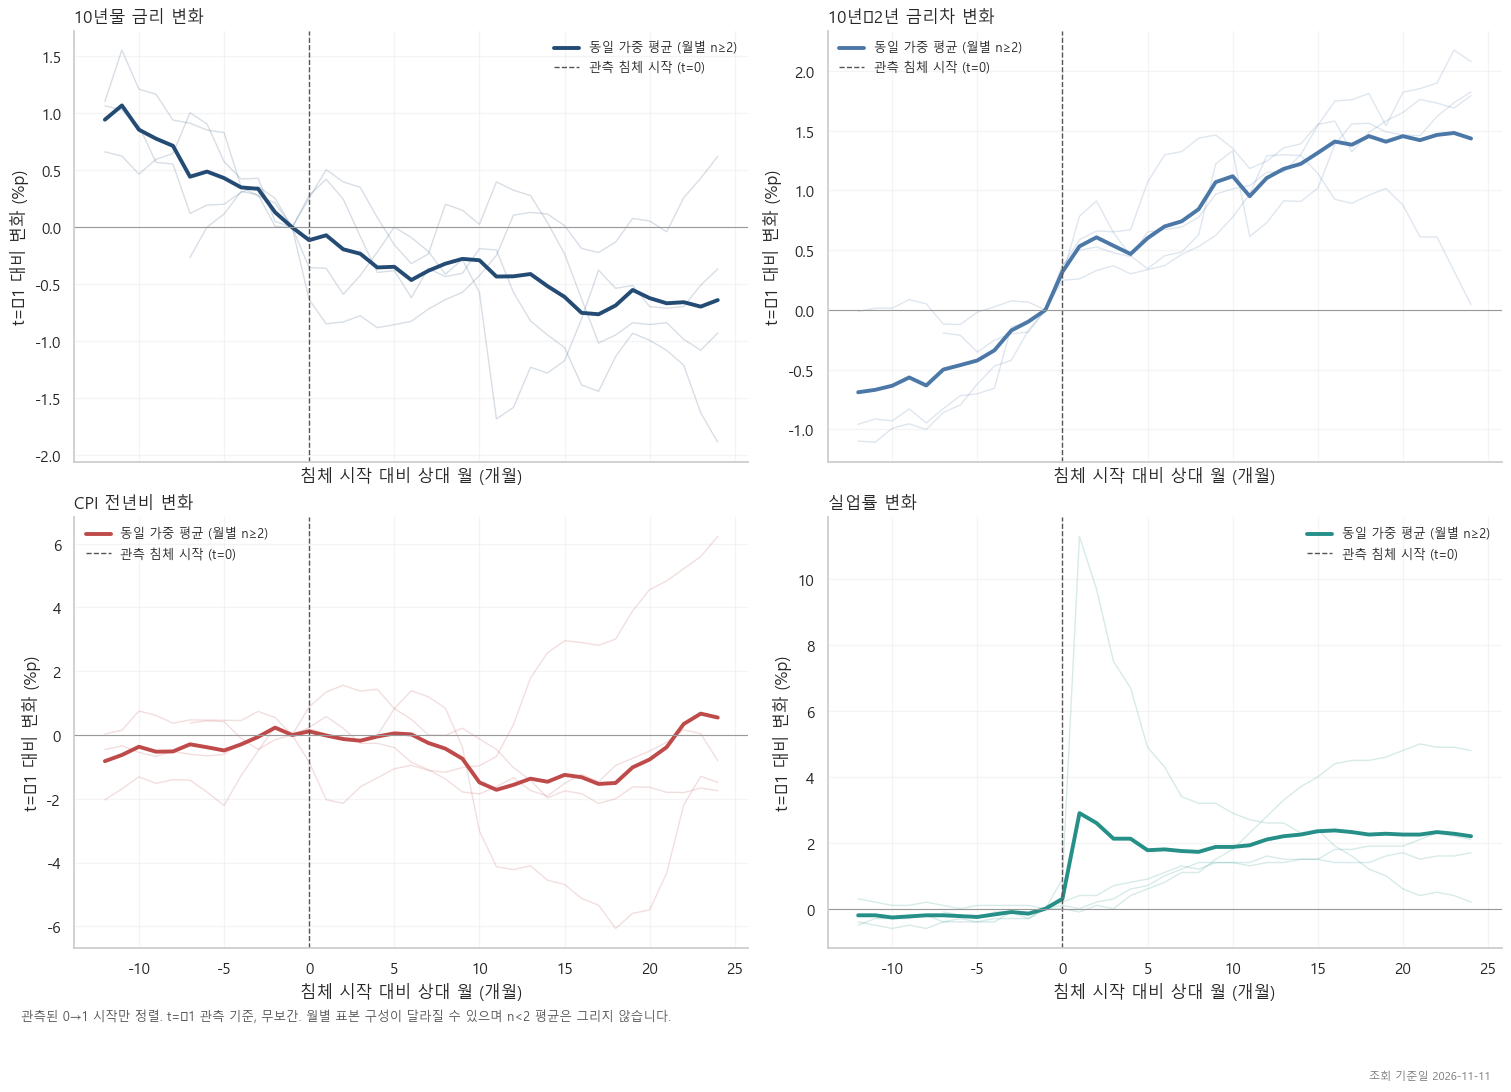

In [58]:
_v_event_specs = [('US10Y','10년물 금리 변화','%p','#244B74'),('T10Y2Y','10년−2년 금리차 변화','%p','#4C78A8'),
                  ('CPI_YoY','CPI 전년비 변화','%p','#BF4A4A'),('UNRATE','실업률 변화','%p','#258F88')]
_v_rel = np.arange(-EVENT_WINDOW_BEFORE,EVENT_WINDOW_AFTER+1)
_v_event_rows, _v_event_count_rows, _v_event_path_rows = [], [], []
fig,axes = plt.subplots(2,2,figsize=(15,10),sharex=True,constrained_layout=True)
for ax,(c,label,unit,color) in zip(axes.flat,_v_event_specs):
    paths = []
    s = _vs(c)
    for start in _v_known_starts:
        baseline_month = start-pd.DateOffset(months=1)
        baseline = s.get(baseline_month,np.nan)
        _v_event_rows.append({'event_start':start,'series':c,'baseline_month':baseline_month,
                              'baseline_value':baseline,'baseline_observed':pd.notna(baseline)})
        dates = pd.DatetimeIndex([start+pd.DateOffset(months=int(h)) for h in _v_rel])
        delta = s.reindex(dates).to_numpy(dtype=float,na_value=np.nan)-baseline if pd.notna(baseline) else np.full(len(_v_rel),np.nan)
        if pd.notna(baseline):
            paths.append(delta)
            if np.isfinite(delta).any():
                ax.plot(_v_rel,delta,color=color,alpha=.18,lw=1)
        for h,d,v in zip(_v_rel,dates,delta):
            _v_event_path_rows.append({'event_start':start,'series':c,'relative_month':int(h),
                                       'observation_month':d,'delta_vs_minus1':v})
    matrix = np.vstack(paths) if paths else np.empty((0,len(_v_rel)))
    n = np.isfinite(matrix).sum(axis=0)
    mean = np.divide(np.nansum(matrix,axis=0),n,out=np.full(len(_v_rel),np.nan),where=n>0)
    for h,count,m in zip(_v_rel,n,mean):
        _v_event_count_rows.append({'series':c,'relative_month':int(h),'actual_event_count':int(count),
                                    'unweighted_mean_delta':m,'mean_line_shown':bool(count>=2)})
    if (n>=2).any():
        ax.plot(_v_rel,np.where(n>=2,mean,np.nan),color=color,lw=2.8,label='동일 가중 평균 (월별 n≥2)')
    elif (n>0).any():
        ax.text(.03,.95,'월별 n<2: 평균선 생략, 개별 사건만 표시',transform=ax.transAxes,va='top',fontsize=9)
    else:
        _vempty(ax,'관측된 시작과 t=−1 기준값이 있는 사건이 없습니다.')
    ax.axvline(0,color='#555555',ls='--',lw=1,label='관측 침체 시작 (t=0)')
    ax.axhline(0,color='#999999',lw=.8)
    ax.set_title(label,loc='left'); ax.set_ylabel(f't=−1 대비 변화 ({unit})')
    ax.set_xlabel('침체 시작 대비 상대 월 (개월)'); ax.grid(alpha=.2)
    ax.legend(frameon=False,fontsize=9)
_vsave_table('event_baseline_coverage',pd.DataFrame(_v_event_rows,columns=['event_start','series','baseline_month','baseline_value','baseline_observed']))
_vsave_table('event_sample_counts',pd.DataFrame(_v_event_count_rows),show=False)
display(viz_tables['event_sample_counts'].pivot(index='relative_month',columns='series',values='actual_event_count'))
_vsave_table('event_individual_paths',pd.DataFrame(_v_event_path_rows,columns=['event_start','series','relative_month','observation_month','delta_vs_minus1']),show=False)
finish_figure(fig,'macro_recession_event_study',caption='관측된 0→1 시작만 정렬. t=−1 관측 기준, 무보간. 월별 표본 구성이 달라질 수 있으며 n<2 평균은 그리지 않습니다.')


### 3-20. 보간 민감도: 계수와 표본을 같이 비교

각 변수 쌍을 (1) 원관측, (2) 보간 후 사후 EDA, (3) 해당 두 변수 중 하나라도 `taint_mask`의 보간 영향을 받은 달을 제외한 EDA로 비교합니다. 표본수와 첫·마지막 사용월을 함께 저장합니다. `taint_mask`가 없는 열/달은 “영향 없음”으로 가정하지 않고 보수적으로 제외합니다.

위 비교는 표본 구성이 달라질 수 있습니다. 추가로 세 자료에서 동시에 유효하며 영향이 없는 **동일 월 표본**의 상관도 저장하여 값 변화와 표본 변화의 혼동을 줄입니다. 원자료 보간 표시 `imputed_mask`만으로는 파생변수의 여러 달 영향 범위를 판단할 수 없으므로 taint 이력을 사용합니다. 차이를 물가·금리 관계가 강화되었다는 경제적 결론으로 단정하지 않습니다.


,series_a,series_b,sample,pair_count,pearson_corr,first_pair_month,last_pair_month,identical_unaffected_n,identical_unaffected_corr
0,US10Y,CPI_YoY,관측 원자료,440,0.285617,1990-01-01,2026-09-01,429,0.285119
1,US10Y,CPI_YoY,보간후 EDA,442,0.286133,1990-01-01,2026-10-01,429,0.285119
2,US10Y,CPI_YoY,영향 제외 EDA,429,0.285119,1990-01-01,2025-09-01,429,0.285119
3,US10Y,FEDFUNDS,관측 원자료,442,0.827071,1990-01-01,2026-10-01,442,0.827071
4,US10Y,FEDFUNDS,보간후 EDA,442,0.827071,1990-01-01,2026-10-01,442,0.827071
5,US10Y,FEDFUNDS,영향 제외 EDA,442,0.827071,1990-01-01,2026-10-01,442,0.827071
6,US10Y,UNRATE,관측 원자료,441,-0.115774,1990-01-01,2026-10-01,441,-0.115774
7,US10Y,UNRATE,보간후 EDA,442,-0.115551,1990-01-01,2026-10-01,441,-0.115774
8,US10Y,UNRATE,영향 제외 EDA,441,-0.115774,1990-01-01,2026-10-01,441,-0.115774
9,US10Y,T10Y2Y,관측 원자료,442,-0.157656,1990-01-01,2026-10-01,442,-0.157656


c:\Users\pc377\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
c:\Users\pc377\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
c:\Users\pc377\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.draw()
C:\Users\pc377\AppData\Local\Temp\ipykernel_28636\3321493192.py:32: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight", facecolor="white")
c:\Users\pc377\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


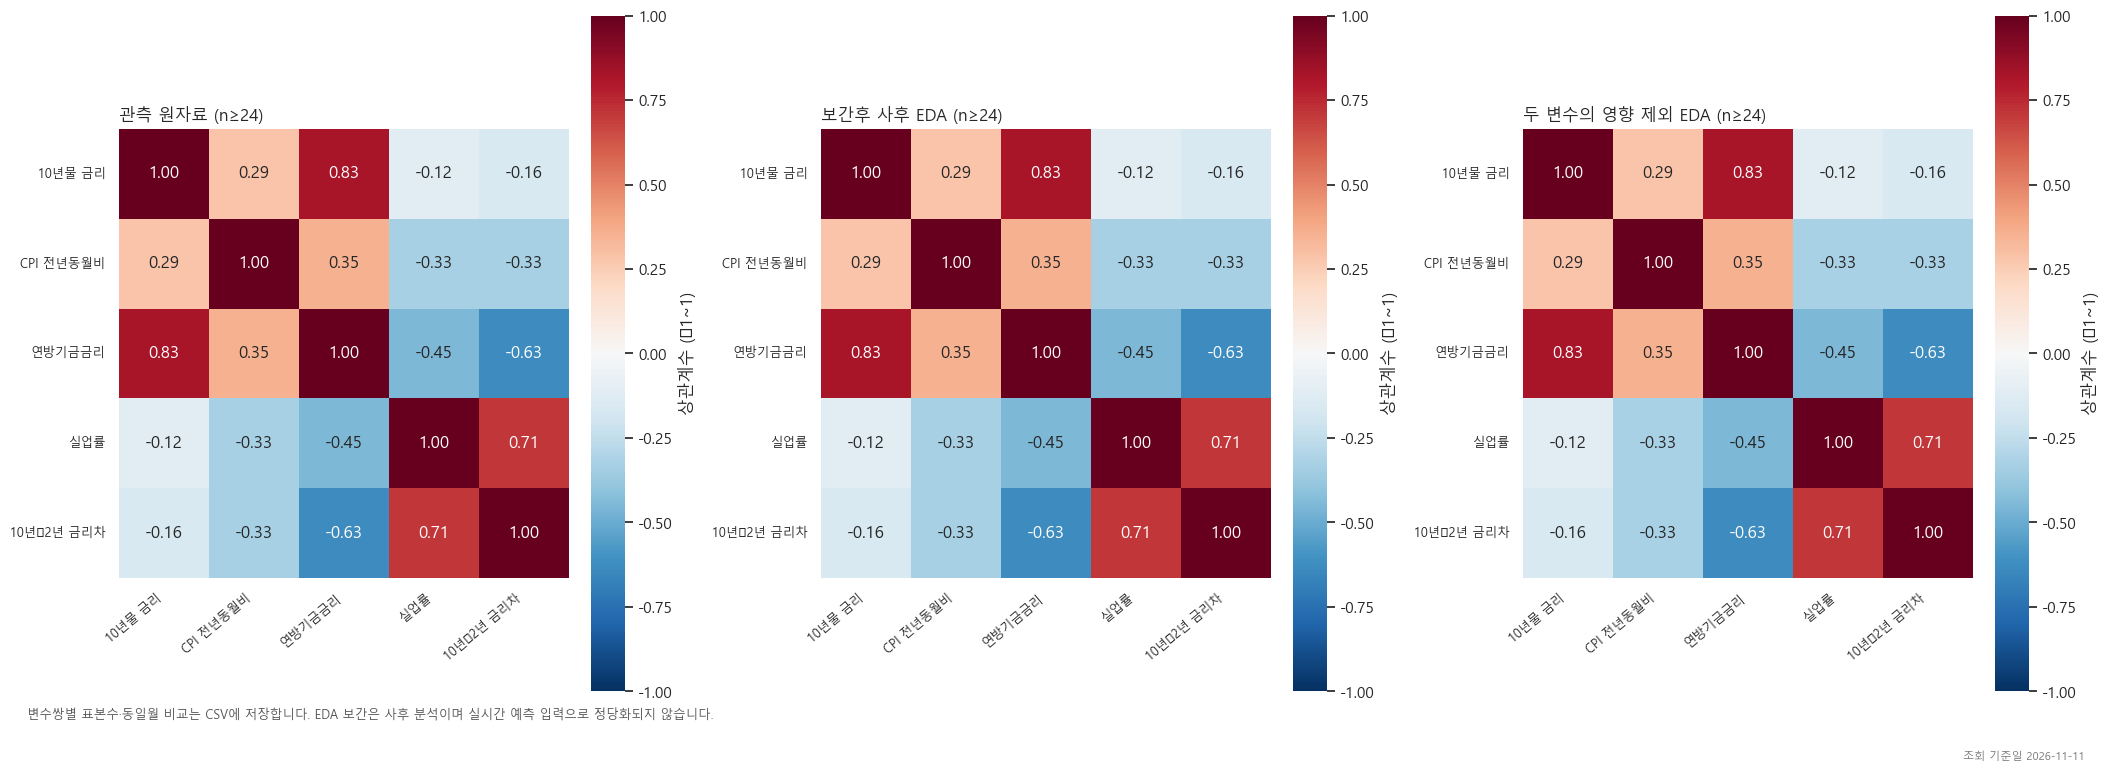

In [59]:
_v_eda = monthly_eda.reindex(_V.index).copy()
_v_taint = globals().get('taint_mask')
if isinstance(_v_taint,pd.DataFrame):
    _v_t = _v_taint.reindex(index=_V.index,columns=_v_corr_cols).fillna(True).astype(bool)
else:
    _v_t = pd.DataFrame(True,index=_V.index,columns=_v_corr_cols)
    print('taint_mask 없음: 영향 제외 표본은 보수적으로 계산 불가로 처리합니다.')
_v_obs_d = _vf(_V,_v_corr_cols)
_v_eda_d = _vf(_v_eda,_v_corr_cols)
_v_clean_d = _v_eda_d.mask(_v_t)
_v_sens_rows = []
for i,a in enumerate(_v_corr_cols):
    for b in _v_corr_cols[i+1:]:
        common = (_v_obs_d[[a,b]].notna().all(axis=1)&_v_eda_d[[a,b]].notna().all(axis=1)&~_v_t[[a,b]].any(axis=1))
        for sample,d in [('관측 원자료',_v_obs_d),('보간후 EDA',_v_eda_d),('영향 제외 EDA',_v_clean_d)]:
            z = d[[a,b]].dropna()
            n = len(z)
            ok = n>=MIN_CORR_PAIRS and z[a].nunique()>1 and z[b].nunique()>1
            fixed = d.loc[common,[a,b]].dropna()
            fixed_ok = len(fixed)>=MIN_CORR_PAIRS and fixed[a].nunique()>1 and fixed[b].nunique()>1
            _v_sens_rows.append({'series_a':a,'series_b':b,'sample':sample,'pair_count':n,
                                  'pearson_corr':z[a].corr(z[b]) if ok else np.nan,
                                  'first_pair_month':z.index.min() if n else pd.NaT,
                                  'last_pair_month':z.index.max() if n else pd.NaT,
                                  'identical_unaffected_n':len(fixed),
                                  'identical_unaffected_corr':fixed[a].corr(fixed[b]) if fixed_ok else np.nan})
_v_sensitivity = pd.DataFrame(_v_sens_rows,columns=['series_a','series_b','sample','pair_count','pearson_corr','first_pair_month','last_pair_month','identical_unaffected_n','identical_unaffected_corr'])
_vsave_table('imputation_correlation_sensitivity',_v_sensitivity)
fig,axes = plt.subplots(1,3,figsize=(21,7),constrained_layout=True)
for ax,title,d in zip(axes,['관측 원자료','보간후 사후 EDA','두 변수의 영향 제외 EDA'],[_v_obs_d,_v_eda_d,_v_clean_d]):
    c,n = _vcorr(d,_v_corr_cols)
    _vheat(ax,c,title+f' (n≥{MIN_CORR_PAIRS})')
finish_figure(fig,'macro_imputation_sensitivity',caption='변수쌍별 표본수·동일월 비교는 CSV에 저장합니다. EDA 보간은 사후 분석이며 실시간 예측 입력으로 정당화되지 않습니다.')


### 3-21. 최신 상태: 지표별 마지막 실제 관측월

모든 지표가 동시에 존재하는 마지막 행 하나를 “최신”으로 사용하지 않습니다. **각 지표별 마지막 유효 관측값과 해당 월**을 따로 제시하며 현재 달은 제외합니다. 변화폭은 그 지표의 마지막 관측월에서 정확히 1·3·12개월 이전 값과 비교합니다. 중간 결측을 뛰어넘는 “직전 유효값”과의 비교가 아니며, 기준월이 없으면 변화도 결측입니다.

금리·실업률·CPI 전년비의 차이는 %p, 금리차 차이는 %p, 고용 차이는 천 명입니다. `USREC` 및 Sahm 근사 지표는 관측 상태의 요약이며 미래 경고 확률이 아닙니다. 이 표는 발표일·빈티지 정보가 없으므로 실시간 정보 집합을 재구성하지 않습니다.


In [60]:
_v_latest_specs = [('US10Y','%','%p'),('US2Y','%','%p'),('T10Y2Y','%p','%p'),
                   ('CPI_YoY','%','%p'),('CPI_MoM','%','%p'),('FEDFUNDS','%','%p'),
                   ('UNRATE','%','%p'),('PAYEMS','천 명','천 명'),('Sahm_Rule','%p','%p'),('USREC','0/1',None)]
_v_latest_rows = []
_v_last_closed = _v_cutoff-pd.DateOffset(months=1)
for c,unit,change_unit in _v_latest_specs:
    s = _vs(c)
    last = s.last_valid_index()
    row = {'series':c,'label':_v_labels.get(c,c),'last_observation_month':last if last is not None else pd.NaT,
           'last_observed_value':s.loc[last] if last is not None else np.nan,'value_unit':unit,
           'change_unit':change_unit,'closed_months_behind':np.nan,'status':'관측 없음'}
    if last is not None:
        row['closed_months_behind'] = (_v_last_closed.year-last.year)*12+_v_last_closed.month-last.month
        row['status'] = '관측값 (발표일·빈티지 별도 확인 필요)'
    for h in [1,3,12]:
        prior = last-pd.DateOffset(months=h) if last is not None else pd.NaT
        old = s.get(prior,np.nan) if last is not None else np.nan
        row[f'change_{h}m'] = (s.loc[last]-old) if last is not None and pd.notna(old) and change_unit is not None else np.nan
        row[f'comparison_month_{h}m'] = prior
    _v_latest_rows.append(row)
_v_latest = pd.DataFrame(_v_latest_rows).set_index('series')
_vsave_table('latest_summary',_v_latest)
print('그림·표는 실제 실행 자료에서만 산출됩니다. 표본 부족·결측·검열 상태를 먼저 확인하십시오.')
print(f'저장 표 {len(viz_tables)}개 | 디렉터리: {Path(TABLE_DIR).resolve()}')


,label,last_observation_month,last_observed_value,value_unit,change_unit,closed_months_behind,status,change_1m,comparison_month_1m,change_3m,comparison_month_3m,change_12m,comparison_month_12m
series,,,,,,,,,,,,,
US10Y,10년물 금리,2026-10-01,5.130952,%,%p,0,관측값 (발표일·빈티지 별도 확인 필요),0.141905,2026-09-01,0.531407,2026-07-01,1.069134,2025-10-01
US2Y,2년물 금리,2026-10-01,4.743333,%,%p,0,관측값 (발표일·빈티지 별도 확인 필요),0.091905,2026-09-01,0.520606,2026-07-01,1.221970,2025-10-01
T10Y2Y,10년−2년 금리차,2026-10-01,0.387619,%p,%p,0,관측값 (발표일·빈티지 별도 확인 필요),0.050000,2026-09-01,0.010801,2026-07-01,-0.152835,2025-10-01
CPI_YoY,CPI 전년동월비,2026-09-01,3.717251,%,%p,1,관측값 (발표일·빈티지 별도 확인 필요),0.364235,2026-08-01,0.253720,2026-06-01,0.694679,2025-09-01
CPI_MoM,CPI 전월비,2026-10-01,0.350285,%,%p,0,관측값 (발표일·빈티지 별도 확인 필요),-0.298263,2026-09-01,0.276615,2026-07-01,NaN,2025-10-01
FEDFUNDS,연방기금금리,2026-10-01,3.880000,%,%p,0,관측값 (발표일·빈티지 별도 확인 필요),0.130000,2026-09-01,0.250000,2026-07-01,-0.210000,2025-10-01
UNRATE,실업률,2026-10-01,4.100000,%,%p,0,관측값 (발표일·빈티지 별도 확인 필요),-0.100000,2026-09-01,0.000000,2026-07-01,NaN,2025-10-01
PAYEMS,비농업 고용,2026-10-01,159293.000000,천 명,천 명,0,관측값 (발표일·빈티지 별도 확인 필요),165.000000,2026-09-01,411.000000,2026-07-01,885.000000,2025-10-01
Sahm_Rule,Sahm 근사 지표,2025-09-01,0.233333,%p,%p,13,관측값 (발표일·빈티지 별도 확인 필요),0.100000,2025-08-01,0.100000,2025-06-01,-0.200000,2024-09-01


그림·표는 실제 실행 자료에서만 산출됩니다. 표본 부족·결측·검열 상태를 먼저 확인하십시오.
저장 표 19개 | 디렉터리: C:\Users\pc377\Downloads\samples-20261111T112459Z-1-001\samples\03.데이터수집\src\02.CrawScrap\outputs_detailed\2026-11-11\tables


## 선택적 예측 A. 미래 6개월 정답의 완전성

아래 함수는 모델 실행 여부와 관계없이 정답의 구성부터 진단합니다. `t+1`부터 `t+6`까지 **6개 달력월 모두** 관측되어야 타깃을 정의합니다. 중간결측·끝부분·진행 중인 관측월은 정답이 없는 상태로 남깁니다. 일부 관측값이 침체 1이어도 이번 실습에서는 완전한 6개월 창만 사용합니다.

관측된 6개월 안에 침체 상태가 한 번이라도 있으면 1입니다. 이미 시작된 침체가 지속되는 경우도 포함하므로 '새 침체 시작'만을 뜻하지 않습니다. USREC의 0은 해당 데이터 버전에서의 분류이며 NBER의 최종 확정을 보장하지 않습니다.

빈티지 이력을 다운로드하지 않아도 타깃 완전성은 그릴 수 있습니다. 다만 조회일 버전의 타깃이 존재한다는 사실만으로 당시 그 정답을 알 수 있었다고 가정하지 않습니다.


In [61]:
# 이 셀은 외부 보조 파일 없이 실행할 수 있도록 모든 함수를 포함합니다.
import json
import time
from urllib.parse import urlencode
from urllib.request import urlopen
from urllib.error import HTTPError, URLError


def download_release_intervals(series_id, api_key, observation_start, as_of_date, cache_dir):
    """FRED output_type=1 이력을 끝까지 내려받습니다. 캐시에 API 키는 저장하지 않습니다."""
    as_of_date = pd.Timestamp(as_of_date).strftime("%Y-%m-%d")
    observation_start = pd.Timestamp(observation_start).strftime("%Y-%m-%d")
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_path = cache_dir / f"{series_id}_{observation_start}_{as_of_date}_intervals_v1.csv"
    meta_path = cache_path.with_suffix(".json")
    required = ["date", "realtime_start", "realtime_end", "value"]
    if cache_path.exists() and meta_path.exists():
        meta = json.loads(meta_path.read_text(encoding="utf-8"))
        table = pd.read_csv(cache_path, dtype={"realtime_start": str, "realtime_end": str})
        if (meta.get("complete") is not True or meta.get("series_id") != series_id
                or meta.get("as_of_date") != as_of_date or len(table) != meta.get("row_count")):
            raise ValueError(f"{series_id}: 캐시 검증 실패. 해당 캐시 파일을 삭제 후 재실행하세요.")
        print(f"캐시 사용: {series_id} ({len(table):,}행)")
    else:
        observations, offset = [], 0
        while True:
            params = {
                "series_id": series_id, "api_key": api_key, "file_type": "json",
                "realtime_start": "1776-07-04", "realtime_end": as_of_date,
                "observation_start": observation_start, "observation_end": as_of_date,
                "output_type": 1, "limit": 100000, "offset": offset,
                "sort_order": "asc",
            }
            request_url = "https://api.stlouisfed.org/fred/series/observations?" + urlencode(params)
            payload = None
            for attempt in range(4):
                try:
                    with urlopen(request_url, timeout=90) as response:
                        payload = json.load(response)
                    break
                except HTTPError as exc:
                    # 예외 URL에는 API 키가 포함될 수 있어 원문 예외를 출력하지 않습니다.
                    if exc.code in (429, 500, 502, 503, 504) and attempt < 3:
                        time.sleep(2 ** (attempt + 1))
                    else:
                        raise RuntimeError(f"{series_id}: FRED 요청 실패 (HTTP {exc.code}).") from None
                except (URLError, TimeoutError):
                    if attempt < 3:
                        time.sleep(2 ** (attempt + 1))
                    else:
                        raise RuntimeError(f"{series_id}: 연결 실패. 캐시/네트워크를 확인하세요.") from None
            if payload is None or "observations" not in payload:
                raise RuntimeError(f"{series_id}: 예상한 관측값 응답이 없습니다.")
            batch = payload["observations"]
            total = int(payload["count"])
            observations.extend(batch)
            offset += len(batch)
            print(f"ALFRED 이력: {series_id} {offset:,}/{total:,}행")
            if offset >= total:
                break
            if not batch:
                raise RuntimeError(f"{series_id}: 페이지 중단. 불완전한 데이터를 저장하지 않습니다.")
            time.sleep(0.6)
        table = pd.DataFrame(observations, columns=required)
        meta = {
            "series_id": series_id, "as_of_date": as_of_date,
            "observation_start": observation_start, "output_type": 1,
            "row_count": len(table), "complete": True,
            "retrieved_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
            "endpoint": "https://api.stlouisfed.org/fred/series/observations",
        }
        # 전체 조회 성공 후에만 캐시 생성. 임시 파일은 최종 파일로 교체합니다.
        temporary_path = cache_path.with_suffix(".tmp")
        table.to_csv(temporary_path, index=False, encoding="utf-8")
        temporary_path.replace(cache_path)
        meta_path.write_text(json.dumps(meta, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
        time.sleep(0.6)
    if not set(required).issubset(table.columns):
        raise ValueError(f"{series_id}: 이력 필수 열 누락.")
    table["date"] = pd.to_datetime(table["date"], errors="raise")
    # 9999-12-31은 pandas Timestamp 범위를 넘을 수 있어 유효기간은 ISO 문자열로 비교.
    for name in ["realtime_start", "realtime_end"]:
        table[name] = table[name].astype(str)
        if not table[name].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all():
            raise ValueError(f"{series_id}: 잘못된 실시간 기간 형식.")
    values = table["value"].replace(".", np.nan)
    table["value"] = pd.to_numeric(values, errors="raise")
    return table.sort_values(["date", "realtime_start"]).reset_index(drop=True)


def asof_snapshot(intervals, cutoff):
    """cutoff에 유효한 버전만 선택. 미공개/철회/결측 값을 최신판으로 대체하지 않습니다."""
    cutoff_ts = pd.Timestamp(cutoff).normalize()
    cutoff_str = cutoff_ts.strftime("%Y-%m-%d")
    active = intervals.loc[
        (intervals["realtime_start"] <= cutoff_str)
        & (intervals["realtime_end"] >= cutoff_str)
        & (intervals["date"] <= cutoff_ts)
    ].copy()
    if active["date"].duplicated().any():
        raise ValueError("동일 관측일에 유효 빈티지가 중복되어 있습니다. 이력을 확인하세요.")
    series = active.set_index("date")["value"].sort_index().astype(float)
    return series, active


def build_pit_features(release_history, forecast_months, features, max_age_months):
    """월초 예측, 전날 정보 마감. 지표별 최신 가용 관측월의 파생변수를 선택합니다."""
    feature_rows, audit_rows = [], []
    series_features = {
        "DGS10": ("US10Y", ["US10Y", "US10Y_Change", "T10Y2Y"]),
        "DGS2": ("US2Y", []),
        "CPIAUCSL": ("CPI", ["CPI_YoY"]),
        "FEDFUNDS": ("FEDFUNDS", ["FEDFUNDS"]),
        "UNRATE": ("UNRATE", ["UNRATE", "Sahm_Rule"]),
        "PAYEMS": ("PAYEMS", ["PAYEMS_Change"]),
    }
    forecast_months = pd.DatetimeIndex(forecast_months)
    for number, forecast_month in enumerate(forecast_months, start=1):
        if forecast_month != forecast_month.to_period("M").to_timestamp():
            raise ValueError("예측 기준일은 월초여야 합니다.")
        cutoff = forecast_month - pd.Timedelta(days=1)
        snapshots, active_tables = {}, {}
        for series_id, intervals in release_history.items():
            snapshots[series_id], active_tables[series_id] = asof_snapshot(intervals, cutoff)
        # 매번 당시 빈티지로 전체 이력과 파생변수를 재계산. 현재 수정판 파생변수 shift 금지.
        history = add_derived_features(build_monthly_base(snapshots)[0])
        history = history.loc[history.index < forecast_month]
        row = {name: np.nan for name in features}
        audit = {"forecast_month": forecast_month, "information_cutoff": cutoff,
                 "cutoff_basis": "ALFRED_date_before_month_start"}
        source_months = {}
        issues = []
        for series_id, (base_name, derived_names) in series_features.items():
            month = history[base_name].last_valid_index() if not history.empty else None
            source_months[series_id] = month
            age = (forecast_month.to_period("M").ordinal - month.to_period("M").ordinal
                   if month is not None else np.nan)
            audit[f"{series_id}_observation_month"] = month
            audit[f"{series_id}_age_months"] = age
            valid_source = (month is not None and 1 <= age <= max_age_months[series_id])
            if not valid_source:
                issues.append(f"{series_id}: 미공개/빈티지 부족/허용 시차 초과")
            if month is not None:
                used = active_tables[series_id].loc[
                    active_tables[series_id]["date"] <= month + pd.offsets.MonthEnd(0)
                ]
                audit[f"{series_id}_max_known_revision_date"] = (
                    used["realtime_start"].max() if not used.empty else None
                )
                for name in derived_names:
                    if valid_source:
                        # 최신 원시 관측월에서 파생값이 결측이면 오래된 파생값으로 후퇴하지 않음.
                        row[name] = history.at[month, name]
            else:
                audit[f"{series_id}_max_known_revision_date"] = None
        # 금리차는 반드시 같은 관측월의 두 금리를 사용해야 합니다.
        if (source_months["DGS10"] != source_months["DGS2"]
                or pd.isna(audit["DGS2_age_months"])
                or audit["DGS2_age_months"] > max_age_months["DGS2"]):
            row["T10Y2Y"] = np.nan
            issues.append("장단기 금리의 최신 관측월 불일치/부족")
        if not np.isfinite(pd.Series(row, dtype=float)).all():
            issues.append("입력/파생변수 결측 또는 비유한 값")
        audit["feature_complete"] = not issues
        audit["exclusion_reason"] = "; ".join(issues)
        # 허용 시차를 벗어난 원자료는 SimpleImputer로 가상의 입력을 만들지 않습니다.
        feature_rows.append(row)
        audit_rows.append(audit)
        if number == 1 or number % 24 == 0 or number == len(forecast_months):
            print(f"시점별 입력 계산: {number}/{len(forecast_months)}개월")
    X_all = pd.DataFrame(feature_rows, index=forecast_months, columns=features, dtype=float)
    X_all.index.name = "forecast_month"
    feature_audit = pd.DataFrame(audit_rows).set_index("forecast_month")
    return X_all, feature_audit


def build_complete_future_target(usrec, forecast_months, horizon=6):
    """달력월 t+1~t+horizon이 모두 관측됐을 때만 타깃을 정의합니다."""
    if horizon < 1:
        raise ValueError("horizon은 1 이상이어야 합니다.")
    usrec = usrec.copy().sort_index()
    if not isinstance(usrec.index, pd.DatetimeIndex):
        raise TypeError("USREC 인덱스는 DatetimeIndex여야 합니다.")
    if usrec.index.has_duplicates:
        raise ValueError("USREC에 중복 관측월이 있습니다.")
    if not (usrec.index == usrec.index.to_period("M").to_timestamp()).all():
        raise ValueError("USREC 인덱스는 월초로 통일해야 합니다.")
    if not usrec.dropna().isin([0, 1]).all():
        raise ValueError("USREC은 0, 1 또는 결측만 허용합니다.")
    forecast_months = pd.DatetimeIndex(forecast_months)
    if not (forecast_months == forecast_months.to_period("M").to_timestamp()).all():
        raise ValueError("예측 기준월은 월초로 통일해야 합니다.")
    future = pd.DataFrame(index=forecast_months)
    for h in range(1, horizon + 1):
        dates = forecast_months + pd.DateOffset(months=h)
        future[f"USREC_t_plus_{h}"] = usrec.reindex(dates).to_numpy()
    future.index.name = "forecast_month"
    future["future_observed_months"] = future.notna().sum(axis=1)
    future["future_complete"] = future["future_observed_months"].eq(horizon)
    outcome_cols = [f"USREC_t_plus_{h}" for h in range(1, horizon + 1)]
    future["Target"] = future[outcome_cols].max(axis=1, skipna=False).where(future["future_complete"])
    future["target_start"] = forecast_months + pd.DateOffset(months=1)
    future["target_end"] = forecast_months + pd.DateOffset(months=horizon)
    return future


완전한 6개월 정답 행: 436
정답 미완성 행: 7


,USREC_t_plus_1,USREC_t_plus_2,USREC_t_plus_3,USREC_t_plus_4,USREC_t_plus_5,USREC_t_plus_6,future_observed_months,future_complete,Target,target_start,target_end,label_snapshot_date
forecast_month,,,,,,,,,,,,
2025-12-01,0.0,0.0,0.0,0.0,0.0,0.0,6,True,0.0,2026-01-01,2026-06-01,2026-11-11
2026-01-01,0.0,0.0,0.0,0.0,0.0,0.0,6,True,0.0,2026-02-01,2026-07-01,2026-11-11
2026-02-01,0.0,0.0,0.0,0.0,0.0,0.0,6,True,0.0,2026-03-01,2026-08-01,2026-11-11
2026-03-01,0.0,0.0,0.0,0.0,0.0,0.0,6,True,0.0,2026-04-01,2026-09-01,2026-11-11
2026-04-01,0.0,0.0,0.0,0.0,0.0,0.0,6,True,0.0,2026-05-01,2026-10-01,2026-11-11
2026-05-01,0.0,0.0,0.0,0.0,0.0,NaN,5,False,NaN,2026-06-01,2026-11-01,2026-11-11
2026-06-01,0.0,0.0,0.0,0.0,NaN,NaN,4,False,NaN,2026-07-01,2026-12-01,2026-11-11
2026-07-01,0.0,0.0,0.0,NaN,NaN,NaN,3,False,NaN,2026-08-01,2027-01-01,2026-11-11
2026-08-01,0.0,0.0,NaN,NaN,NaN,NaN,2,False,NaN,2026-09-01,2027-02-01,2026-11-11


c:\Users\pc377\miniconda3\Lib\site-packages\matplotlib\dates.py:328: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NaT_int = np.datetime64('NaT').astype(np.int64)


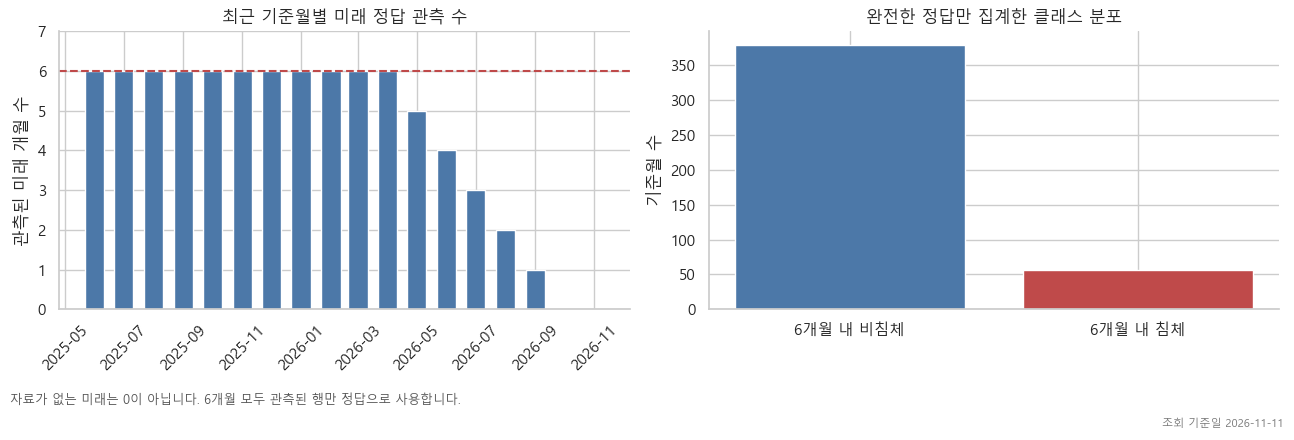

In [62]:
forecast_months = pd.date_range(START_DATE, SNAPSHOT_TS.to_period("M").to_timestamp(), freq="MS")
target_audit = build_complete_future_target(monthly_observed["USREC"], forecast_months, TARGET_HORIZON)
target_audit["label_snapshot_date"] = DATA_SNAPSHOT_DATE
print("완전한 6개월 정답 행:", int(target_audit["future_complete"].sum()))
print("정답 미완성 행:", int((~target_audit["future_complete"]).sum()))
display(target_audit.tail(12))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
recent_target = target_audit.tail(18)
axes[0].bar(recent_target.index, recent_target["future_observed_months"], width=20, color="#4C78A8")
axes[0].axhline(TARGET_HORIZON, color="#BF4A4A", ls="--")
axes[0].set(title="최근 기준월별 미래 정답 관측 수", ylabel="관측된 미래 개월 수", ylim=(0, 7))
axes[0].tick_params(axis="x", rotation=45)
counts = target_audit["Target"].value_counts().reindex([0, 1], fill_value=0)
axes[1].bar(["6개월 내 비침체", "6개월 내 침체"], counts.values, color=["#4C78A8", "#BF4A4A"])
axes[1].set(title="완전한 정답만 집계한 클래스 분포", ylabel="기준월 수")
finish_figure(fig, "model_target_completeness", "자료가 없는 미래는 0이 아닙니다. 6개월 모두 관측된 행만 정답으로 사용합니다.")


## 선택적 예측 B. 당시 발표된 빈티지만으로 입력 만들기

`RUN_PIT_MODEL=True`일 때만 실행합니다. 기준월의 월초에 예측하고 전날까지 ALFRED에 기록된 관측값만 사용합니다. 빈티지 유효기간 양 끝은 포함합니다. CPI·고용·Sahm 등 파생변수는 그 시점의 원자료에서 다시 계산하며, EDA 보간값은 사용하지 않습니다.

최근 가용 관측월은 지표별로 다를 수 있습니다. 관측월·정보 마감일·입력 시차를 기록하고 8개 입력 모두 계산 가능한 행만 사용합니다. 빈티지 공백은 최신 수정판으로 대체하지 않습니다. 금리는 최소 일별 관측 수 기준도 적용합니다.

이 방식은 ALFRED의 **일 단위 기록**을 활용한 가용정보 제한입니다. 실제 발표일 캘린더·발표시각·데이터 수신시각을 완전히 재현하지는 않습니다. 빈티지 날짜보다 훨씬 과거인 관측월을 당시 알 수 있었다고 가정하지 않습니다.


In [63]:
FEATURES = ["US10Y", "US10Y_Change", "CPI_YoY", "FEDFUNDS", "T10Y2Y", "UNRATE", "Sahm_Rule", "PAYEMS_Change"]
X_all = pd.DataFrame(columns=FEATURES, dtype=float)
feature_audit = pd.DataFrame()
dataset = pd.DataFrame()
train_target_audit = pd.DataFrame()
if RUN_PIT_MODEL:
    FRED_KEY = os.getenv("FRED_API_KEY")
    if not FRED_KEY:
        raise ValueError("PIT 모델 실행에는 FRED_API_KEY가 필요합니다.")
    release_history = {
        sid: download_release_intervals(sid, FRED_KEY, DATA_START_DATE, DATA_SNAPSHOT_DATE, CACHE_DIR)
        for sid in SERIES
    }
    X_all, feature_audit = build_pit_features(release_history, forecast_months, FEATURES, MAX_SOURCE_AGE_MONTHS)
    ready = feature_audit["feature_complete"] & X_all.notna().all(axis=1)
    dataset = X_all.join(target_audit[["Target"]])
    dataset = dataset.loc[ready & target_audit["future_complete"]].copy()
    print("전체 기준월:", len(X_all), "/ 입력 완전:", int(ready.sum()), "/ 정답까지 완전:", len(dataset))
    display(feature_audit.tail(12))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ages = feature_audit.filter(like="age_months").tail(36).T
    sns.heatmap(ages, cmap="YlGnBu", mask=ages.isna(), ax=axes[0], cbar_kws={"label": "관측월 시차(개월)"})
    axes[0].set_title("최근 36개월 입력 가용 시차")
    axes[1].bar(["전체", "입력 완전", "입력+정답 완전"], [len(X_all), int(ready.sum()), len(dataset)], color=["#999999", "#4C78A8", "#258F88"])
    axes[1].set(title="학습 후보 행의 제외 단계", ylabel="기준월 수")
    finish_figure(fig, "model_pit_availability", "단계별 표본 수는 실행 시 빈티지 지원과 결측 상황에 따라 달라집니다.")
else:
    print("PIT 입력·모델 파트를 건너뜁니다. 설정에서 RUN_PIT_MODEL=True로 켤 수 있습니다.")


PIT 입력·모델 파트를 건너뜁니다. 설정에서 RUN_PIT_MODEL=True로 켤 수 있습니다.


## 선택적 예측 C. 시간순 학습·평가와 Pipeline 전처리

입력·정답이 완전한 후보 행에서 앞 80%를 학습 후보, 뒤 20%를 테스트로 정합니다. 모델은 첫 테스트 월 전날에 학습한다고 가정하여 그때 유효한 USREC로 학습 정답을 다시 만듭니다. 미래 6개월이 아직 끝나지 않았거나 당시 발표되지 않은 학습 후보는 제외합니다. 테스트 정답은 조회 기준일 버전으로 사후 평가합니다.

표준화와 중앙값 대체는 Pipeline 내부에서 **학습 구간으로만 적합**합니다. 필수 입력은 앞 단계에서 모두 확인했기 때문에 결측 대체가 미공개 필수 입력을 만들어 내지는 않습니다. 전체기간 평균·표준편차로 모델 입력을 표준화하지 않습니다.

Logistic Regression과 Random Forest를 비교하되, 최종 출력 모델은 `PRIMARY_MODEL_NAME`으로 **평가 전에 지정**합니다. 테스트 성적이 좋다는 이유로 사후에 모델을 자동 선택하지 않습니다. 별도 검증구간·롤링 재학습·확률 보정까지 구현한 것은 아니며, 경기침체 사례가 적고 타깃 창이 중첩된다는 한계가 있습니다.


In [64]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, precision_score, recall_score, f1_score, brier_score_loss,
    RocCurveDisplay, PrecisionRecallDisplay)

fitted_models, model_test_scores = {}, pd.DataFrame()
results_df, importance, latest_prediction = pd.DataFrame(), pd.Series(dtype=float), pd.DataFrame()
model_tables = {}
if RUN_PIT_MODEL:
    if len(dataset) < 30:
        raise ValueError("완전한 입력·정답 표본이 부족합니다. 기간과 빈티지 지원을 확인하세요.")
    X = dataset[FEATURES]
    y = dataset["Target"].astype(int)
    split_idx = int(len(dataset) * 0.80)
    X_train_candidate, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
    y_test = y.iloc[split_idx:]
    TRAINING_CUTOFF = X_test.index.min() - pd.Timedelta(days=1)
    train_usrec_daily, _ = asof_snapshot(release_history["USREC"], TRAINING_CUTOFF)
    train_usrec = train_usrec_daily.resample("MS").max()
    train_usrec = train_usrec.loc[:(X_test.index.min().to_period("M") - 1).to_timestamp()]
    train_target_audit = build_complete_future_target(train_usrec, X_train_candidate.index, TARGET_HORIZON)
    train_target_audit["label_snapshot_date"] = TRAINING_CUTOFF.strftime("%Y-%m-%d")
    train_ready = train_target_audit["future_complete"]
    X_train = X_train_candidate.loc[train_ready]
    y_train = train_target_audit.loc[train_ready, "Target"].astype(int)
    if y_train.nunique() != 2 or len(X_train) < 20:
        raise ValueError("학습 마감일 당시 정답에 두 클래스가 충분히 존재하지 않습니다.")
    assert train_target_audit.loc[X_train.index, "target_end"].lt(X_test.index.min()).all()
    models = {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
            ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=5,
                        class_weight="balanced", random_state=RANDOM_STATE))]),
    }
    if PRIMARY_MODEL_NAME not in models:
        raise ValueError("PRIMARY_MODEL_NAME을 등록된 모델명으로 설정하세요.")
    model_test_scores = pd.DataFrame(index=X_test.index)
    model_test_scores["Target"] = y_test
    rows = []
    for name, pipeline in models.items():
        pipeline.fit(X_train, y_train)
        fitted_models[name] = pipeline
        probability = pipeline.predict_proba(X_test)[:, 1]
        prediction = (probability >= 0.5).astype(int)
        model_test_scores[name] = probability
        report = pd.DataFrame(classification_report(y_test, prediction, labels=[0, 1], output_dict=True, zero_division=0)).T
        model_tables["classification_" + name.replace(" ", "_")] = report
        model_tables["confusion_" + name.replace(" ", "_")] = pd.DataFrame(
            confusion_matrix(y_test, prediction, labels=[0, 1]),
            index=["실제0", "실제1"], columns=["예측0", "예측1"])
        rows.append({"Model": name, "ROC_AUC": roc_auc_score(y_test, probability) if y_test.nunique() == 2 else np.nan,
            "AP": average_precision_score(y_test, probability) if y_test.nunique() == 2 else np.nan,
            "Precision": precision_score(y_test, prediction, zero_division=0),
            "Recall": recall_score(y_test, prediction, zero_division=0),
            "F1": f1_score(y_test, prediction, zero_division=0),
            "Brier": brier_score_loss(y_test, probability), "Test_N": len(y_test)})
    results_df = pd.DataFrame(rows).set_index("Model")
    importance = pd.Series(fitted_models["Random Forest"].named_steps["model"].feature_importances_, index=FEATURES).sort_values()
    print("학습 정보 마감일:", TRAINING_CUTOFF.strftime("%Y-%m-%d"))
    print("학습/테스트 행:", len(X_train), len(X_test))
    display(results_df.round(3))
    for name in model_tables:
        display(model_tables[name])


## 선택적 예측 D. 결과를 여러 각도에서 읽기

혼동행렬은 누락과 오탐을 따로 보여 줍니다. ROC는 전체 구분 능력, Precision–Recall과 AP는 희귀한 침체 클래스 탐지의 정밀도·재현율을 살펴보는 도구입니다. 시간별 분류 점수 그래프는 경고가 언제 높아졌는지 확인하는 사후 진단입니다.

점수 구간별 실제 타깃 비율은 **보정 상태를 진단**할 뿐 확률을 보정하는 학습 과정이 아닙니다. 구간별 표본 수가 작은 점은 불확실합니다. 랜덤 포레스트 중요도와 표준화된 로지스틱 회귀 계수는 모델 내부의 기여이며 경제적 인과관계가 아닙니다. 상관이 높은 입력은 중요도를 나누어 가질 수 있습니다.


In [65]:
if RUN_PIT_MODEL:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (name, pipeline) in zip(axes, fitted_models.items()):
        matrix = confusion_matrix(y_test, pipeline.predict(X_test), labels=[0, 1])
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["비침체", "침체"], yticklabels=["비침체", "침체"])
        ax.set(title=name, xlabel="예측 클래스", ylabel="실제 클래스")
    finish_figure(fig, "model_confusion_matrices", "분류 임계값 0.5의 탐색적 진단. 오탐 비용과 누락 비용은 같지 않을 수 있습니다.")
    if y_test.nunique() == 2:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        for name in fitted_models:
            probability = model_test_scores[name]
            RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=axes[0])
            PrecisionRecallDisplay.from_predictions(y_test, probability, name=name, ax=axes[1])
        axes[1].axhline(y_test.mean(), color="#999999", ls="--", label="테스트 침체 비율")
        axes[1].legend()
        finish_figure(fig, "model_roc_pr", "한 클래스만 있는 평가 구간에서는 ROC·AP를 계산하지 않습니다.")
    fig, ax = plt.subplots(figsize=(14, 4))
    for name in fitted_models:
        ax.plot(model_test_scores.index, model_test_scores[name], label=name)
    ax.step(y_test.index, y_test, where="post", color="#999999", alpha=0.4, label="향후 6개월 실제 타깃")
    ax.set(title="테스트 기준월별 분류 점수와 사후 정답", ylabel="분류 점수 / 이진 타깃", ylim=(-0.03, 1.03))
    ax.legend()
    finish_figure(fig, "model_score_timeline", "이진 타깃은 해당 월 침체 여부가 아니라 다음 6개월 안에 침체가 있는지입니다.")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    bins = np.linspace(0, 1, 6)
    calibration_tables = []
    for name in fitted_models:
        frame = pd.DataFrame({"score": model_test_scores[name], "target": y_test})
        frame["bin"] = pd.cut(frame["score"], bins=bins, include_lowest=True)
        summary = frame.groupby("bin", observed=True).agg(mean_score=("score", "mean"),
                    actual_rate=("target", "mean"), count=("target", "size"))
        summary["Model"] = name
        calibration_tables.append(summary.reset_index())
        axes[0].plot(summary["mean_score"], summary["actual_rate"], "o-", label=name)
        axes[1].hist(frame["score"], bins=bins, alpha=0.4, label=name)
    axes[0].plot([0, 1], [0, 1], "--", color="#999999")
    axes[0].set(title="점수 구간별 실제 침체 비율", xlabel="구간 평균 점수", ylabel="구간 실제 타깃 비율", xlim=(0, 1), ylim=(0, 1))
    axes[1].set(title="테스트 점수 분포", xlabel="분류 점수", ylabel="표본 수")
    for ax in axes:
        ax.legend()
    model_tables["score_bin_diagnostics"] = pd.concat(calibration_tables, ignore_index=True)
    display(model_tables["score_bin_diagnostics"])
    finish_figure(fig, "model_score_diagnostics", "테스트에서 보정 상태를 진단한 그림이며, 보정 모델을 적합하지 않았습니다.")
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    importance.plot.barh(ax=axes[0], color="#4C78A8")
    axes[0].set(title="랜덤 포레스트 변수 중요도", xlabel="불순도 감소 기여")
    coefficients = pd.Series(fitted_models["Logistic Regression"].named_steps["model"].coef_[0], index=FEATURES).sort_values()
    coefficients.plot.barh(ax=axes[1], color=["#258F88" if x >= 0 else "#BF4A4A" for x in coefficients])
    axes[1].axvline(0, color="#999999", lw=1)
    axes[1].set(title="표준화 입력의 로지스틱 회귀 계수", xlabel="계수: 인과효과 아님")
    model_tables["feature_importance"] = importance.to_frame("Importance")
    model_tables["logistic_coefficients"] = coefficients.to_frame("Coefficient")
    finish_figure(fig, "model_feature_contributions", "중요도·계수는 학습된 모델의 설명이며 경제적 인과관계나 투자 신호가 아닙니다.")


## 선택적 예측 E. 정답 없는 최근 행으로 추론하기

최근 입력은 정답 필터를 통과한 학습용 `X`가 아니라 전체 `X_all`에서 선택합니다. 필수 입력이 부족하면 과거 기준월로 조용히 후퇴하지 않습니다. 아래 모델은 첫 테스트 월 이전의 학습구간에서 적합한 모델이며 최신 월까지 다시 학습한 모델이 아닙니다. 현재 월중 실행해도 입력은 월초 전날까지의 가용정보입니다.


In [66]:
if RUN_PIT_MODEL:
    latest_month = X_all.index.max()
    if not ready.loc[latest_month]:
        print("최신 기준월 입력이 불충분하여 최근 예측을 생성하지 않습니다.")
        display(feature_audit.loc[[latest_month]])
    else:
        selected_model = fitted_models[PRIMARY_MODEL_NAME]
        latest_X = X_all.loc[[latest_month], FEATURES]
        latest_score = selected_model.predict_proba(latest_X)[0, 1]
        latest_prediction = pd.DataFrame({
            "Model": [PRIMARY_MODEL_NAME], "Information_Cutoff": [latest_month - pd.Timedelta(days=1)],
            "Target_Start": [latest_month + pd.DateOffset(months=1)],
            "Target_End": [latest_month + pd.DateOffset(months=TARGET_HORIZON)],
            "Classification_Score": [latest_score], "Training_Cutoff": [TRAINING_CUTOFF],
        }, index=latest_X.index)
        display(latest_prediction)
        print(f"경기침체 분류 점수: {latest_score:.1%} — 보정된 실시간 확률이 아닙니다.")


## 결과 저장과 재현성

원자료는 `raw/`, 데이터·감사 표는 `tables/`, 그림은 `figures/`에 저장합니다. 그림마다 PNG와 편집 가능한 SVG를 함께 저장하며 조회 기준일과 해설 캡션을 포함합니다. `figure_index.csv`로 그림 목차를 확인할 수 있습니다.

`monthly_observed.csv`는 보간하지 않은 분석용 데이터, `monthly_eda.csv`는 사후 탐색용 보간 데이터입니다. `imputed_mask.csv`는 보간한 원자료 셀, `taint_mask.csv`는 그 값이 영향을 줄 수 있는 파생변수 셀을 표시합니다. 두 파일의 의미가 다릅니다. 학습 데이터는 이 두 데이터의 보간본이 아니라 ALFRED 빈티지 입력으로 따로 생성합니다.

실행한 자료 버전·설정·전처리 요약을 JSON에 남깁니다. API 키나 다른 서비스 인증정보는 저장하지 않습니다. 과거 기준일을 재현하려면 원자료·manifest와 설정 JSON을 함께 보관하세요.


In [67]:
export_tables = {
    "monthly_base": monthly_base, "monthly_observed": monthly_observed,
    "monthly_eda": monthly_eda, "raw_audit": raw_audit,
    "raw_invalid_log": raw_invalid_log, "daily_monthly_stats": daily_monthly_stats,
    "quality_before": quality_before, "quality_after": quality_after,
    "gap_intervals": gap_intervals, "missing_comparison": missing_comparison,
    "imputed_mask": imputed_mask, "impute_log": impute_log, "taint_mask": taint_mask,
    "outlier_flags": outlier_flags, "outlier_log": outlier_log,
    "data_dictionary": data_dictionary, "warmup_impact": warmup_impact,
    "target_completeness": target_audit,
    "figure_index": pd.DataFrame(figure_registry),
}
export_tables.update(viz_tables)
if RUN_PIT_MODEL:
    export_tables.update({"pit_features": X_all, "pit_feature_audit": feature_audit,
        "labeled_dataset": dataset, "training_labels_asof": train_target_audit,
        "model_evaluation": results_df, "model_test_scores": model_test_scores,
        "latest_prediction": latest_prediction})
    export_tables.update(model_tables)
for name, frame in export_tables.items():
    if isinstance(frame, pd.Series):
        frame = frame.to_frame()
    if isinstance(frame, pd.DataFrame):
        frame.to_csv(TABLE_DIR / f"{name}.csv", encoding="utf-8-sig", index=True)
run_config = {
    "source_notebook": "US_Macro_Intelligence_FRED_Analysis(1).ipynb",
    "snapshot_date": DATA_SNAPSHOT_DATE, "start_date": START_DATE, "warmup_start": DATA_START_DATE,
    "data_mode": DATA_MODE, "eda_interpolation": ENABLE_EDA_INTERPOLATION,
    "max_gap_months": MAX_GAP, "min_daily_observations": MIN_DAILY_OBSERVATIONS,
    "outlier_threshold": OUTLIER_Z_THRESHOLD, "pit_model_enabled": RUN_PIT_MODEL,
    "primary_model_preselected": PRIMARY_MODEL_NAME, "figure_count": len(figure_registry),
    "created_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "caveat": "EDA is retrospective; ALFRED daily records do not reproduce exact intraday publication calendars.",
}
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(run_config, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
(OUTPUT_DIR / "preprocessing_summary.json").write_text(json.dumps(preprocessing_report, ensure_ascii=False, indent=2, default=str) + "\n", encoding="utf-8")
print("저장된 표:", len(export_tables), "/ 생성한 그림:", len(figure_registry))
print("표:", TABLE_DIR, "/ PNG·SVG:", FIG_DIR)
display(pd.DataFrame(figure_registry)[["name", "caption"]])


저장된 표: 38 / 생성한 그림: 26
표: outputs_detailed\2026-11-11\tables / PNG·SVG: outputs_detailed\2026-11-11\figures


,name,caption
0,prep_01_missing_heatmap,원자료와 계산 준비기간 결측을 구분해서 해석합니다. 주황은 결측이며 0값이 아닙니다.
1,prep_02_missing_categories,전체가 결측인 열은 독립 범주로 계산합니다. 값이 전혀 없는 빈 기간과 결측 없는 ...
2,prep_03_daily_coverage,관측 개수 임계값은 분석 정책이며 거래일 커버리지 보증이 아닙니다. x 표시는 저관...
3,prep_04_eda_before_after,마름모만 실제 추정한 원자료입니다. 점선/파생값을 실제 관측이나 실시간 예측 입력으...
4,prep_05_historical_outliers,"현재 값은 과거 중앙값/MAD 계산에 포함하지 않습니다. 결측 점수는 미평가이며, ..."
5,macro_overview_6panel,완료된 월의 관측 자료. 회색 음영은 관측된 NBER 침체 기간입니다.
6,macro_recent_overlay,"지표별 마지막 발표월이 다를 수 있으며, 결측 구간을 이어 그리지 않습니다."
7,macro_yield_levels_changes,bp 변환은 금리의 %p 변화 × 100. 일별 자료가 없으면 세 번째 패널을 계산...
8,macro_yield_month_heatmap,흰색 마스크는 결측입니다. 0bp 관측과 구분해서 해석하십시오.
9,macro_inflation_horizons,전년비·전월비·연율의 기간 정의가 다릅니다. y축 범위는 패널별로 독립적입니다.
